# Synthetic Benchmark Analysis

This notebook analyzes profiler metrics from synthetic benchmark runs across two configurations:

- Baseline - vanilla Storm topology (no SGX/Teaclave overhead)
- Confidential (SGX) - topology running inside Intel SGX enclaves via Teaclave

## Sections:
- Outlier Detection (pre-analysis): Isolation Forest flags anomalous runs; optionally excluded from downstream analysis
- A - Overhead Analysis: direct baseline vs. confidential comparison
- B - Parameter Sensitivity: how parameters affect each setup
- C - Grid Search Overview: run health, completion status, catalog
- D - Single Run Deep-Dive: detailed profiler analysis for individual runs
- E - Synchronization & Dummy Analysis: counters/gauges comparing real vs dummy emissions, epoch lag, and DP bolt synchronization overhead (useful for debugging Zookeeper interactions)

## Dataset generation and collection details:

I generated the dataset by running `run-grid-search.py` on the two benchmarks (confidential and baseline) with the same parameter grid. Each run emitted profiler metrics to a local directory, which I then aggregated into a single DataFrame for analysis. This is the command I used to generate the dataset:

```bash
python3 scripts/run-grid-search.py \
    --tick-intervals 5 10 30 60 120 180 240 300 \
    --parallelism 8 \
    --num-users 100000 500000 1000000 \
    --num-keys 100000 500000 1000000 \
    --max-time-steps 10 30 50 100 \
    --mode <enclave|baseline> \ # change this depending on the benchmark to run
    --poll-interval 5
```

In [1]:
from typing import cast
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
from IPython.display import display

from helpers.visualization import (
    save_or_show, format_elapsed_axis, color_for,
    adaptive_figsize,
    COLOR_BASELINE, COLOR_CONFIDENTIAL,
    comparison_bar_chart, parameter_breakdown,
    paired_bar_chart, overhead_scatter,
    duration_breakdown_stacked, ecall_overhead_heatmap,
    paired_box_plot,
    parameter_heatmap, parameter_heatmap_faceted,
    sensitivity_line,
    completion_heatmap, status_distribution_plot,
    styled_summary_table,
    run_timeline_gantt, emission_timeline,
    dp_release_timeline, tick_tuple_validation,
    traffic_pattern_analysis,
    traffic_compliance_strip, traffic_compliance_sensitivity,
    traffic_violation_scatter,
    tick_irregularity_overview, tick_irregularity_sensitivity,
    compliance_vs_performance_scatter, irregularity_vs_performance_scatter,
    compliance_correlation_heatmap,
    counter_comparison_bar, dummy_vs_real_ratio_bar,
    emission_stacked_bar, counter_sensitivity_line,
    aggregation_partials_bar, gauge_epoch_lag_comparison,
)
from helpers.dataset import (
    _get_components, _get_ecall_names, get_lifecycle_events,
    discover_all_runs, discover_runs,
    detect_varying_params, short_label, compact_number,
    build_comparison_df, build_matched_pairs,
    load_profiler_csvs, canonical_ecall_name,
)

## Configuration

In [2]:
# --- Data directories ---
CONF_RUNS_DIR = Path("../examples/synthetic-benchmark-confidential/data/runs")
BASE_RUNS_DIR = Path("../examples/synthetic-benchmark-baseline/data/runs")

# --- Filters ---
# Multi-worker grid runs are stored under <runs_dir>/<label>/<timestamp>/n=<N>/<run>.
# The confidential and baseline sweeps were collected on different days, so the
# filter accepts either a single timestamp string or an iterable of timestamps.
FILTER_GRID_TIMESTAMP = ["20260605_202538", "20260607_120003"]
FILTER_LABELS = None  # e.g. ["scaling-sweep"] to restrict to specific labels
INCLUDE_FAILED_RUNS = True    # include OOM/timed-out runs in overview plots
EXCLUDE_OUTLIERS = False      # remove Isolation-Forest outliers from perf_df

# --- Single-run deep-dive (Section D) ---
SINGLE_RUN_IDX = None         # set to a catalog row index to enable Section D

# --- Output ---
OUTPUT_DIR = Path("plots")
SAVE_PLOTS = False
PLOT_FORMAT = "png"
MAX_EPOCH_COLOR = "black"

if SAVE_PLOTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load Run Catalog

Discover all runs from both baseline and confidential directories, parse `params.txt`, and build a unified catalog.

In [3]:
catalog = discover_all_runs(CONF_RUNS_DIR, BASE_RUNS_DIR, require_all=False, labels=FILTER_LABELS)
print(f"Discovered {len(catalog)} total runs")
print(f"  Topology types: {dict(catalog['topology_type'].value_counts())}")
print(f"  Grid batches: {catalog['grid_timestamp'].nunique()}")

if FILTER_GRID_TIMESTAMP:
    before = len(catalog)
    print(catalog["grid_timestamp"].value_counts())
    _ts_filter = [FILTER_GRID_TIMESTAMP] if isinstance(FILTER_GRID_TIMESTAMP, str) else list(FILTER_GRID_TIMESTAMP)
    catalog = catalog[catalog["grid_timestamp"].isin(_ts_filter)].copy()
    print(f"  Filter timestamp={_ts_filter}: {before} -> {len(catalog)} runs")

catalog = catalog.reset_index(drop=True)
vary_cols = detect_varying_params(catalog)
print(f"Varying parameters: {vary_cols}")

# Generate labels and mark status
catalog["label"] = catalog.apply(lambda r: short_label(r, vary_cols), axis=1)

catalog["status"] = "Completed"
catalog.loc[catalog.get("completed", True) == False, "status"] = "Timed out"
if "worker_oom_detected" in catalog.columns:
    catalog.loc[catalog["worker_oom_detected"] == True, "status"] = "OOM"

# remove runs with missing topology_type (e.g. failed before topology was launched)
catalog = catalog[catalog["topology_type"].notna()]

for ttype in sorted(catalog["topology_type"].unique()):
    sub = catalog[catalog["topology_type"] == ttype]
    n_c = (sub["status"] == "Completed").sum()
    n_t = (sub["status"] == "Timed out").sum()
    n_o = (sub["status"] == "OOM").sum()
    print(f"  {ttype}: {len(sub)} runs (Completed: {n_c}, Timed out: {n_t}, OOM: {n_o})")

Discovered 23 total runs
  Topology types: {'enclave': np.int64(12), 'baseline': np.int64(11)}
  Grid batches: 2
grid_timestamp
20260605_202538    12
20260607_120003    11
Name: count, dtype: int64
  Filter timestamp=['20260605_202538', '20260607_120003']: 23 -> 23 runs
Varying parameters: ['tick_interval_secs', 'num_users', 'num_keys']
  baseline: 11 runs (Completed: 10, Timed out: 0, OOM: 1)
  enclave: 12 runs (Completed: 11, Timed out: 0, OOM: 1)


In [4]:
# Build comparison summary from ALL runs (with pickle cache)
import hashlib, pickle

def _catalog_fingerprint(cat: pd.DataFrame) -> str:
    """Hash based on run paths and their profiler data modification times."""
    parts = []
    for _, row in cat.iterrows():
        p = Path(row["profiler_dir"])
        mtime = max((f.stat().st_mtime for f in p.rglob("*.csv")), default=0) if p.is_dir() else 0
        parts.append(f"{row['run_path']}:{mtime}")
    return hashlib.sha256("\n".join(sorted(parts)).encode()).hexdigest()[:16]

_cache_dir = Path(".cache")
_cache_dir.mkdir(exist_ok=True)
_fingerprint = _catalog_fingerprint(catalog)
_cache_file = _cache_dir / f"comparison_{_fingerprint}.pkl"

if _cache_file.exists():
    with open(_cache_file, "rb") as f:
        comparison_df, ecall_dists = pickle.load(f)
    print(f"Loaded comparison summary from cache ({_cache_file.name})")
else:
    comparison_df, ecall_dists = build_comparison_df(catalog, collect_ecall_distributions=True)
    with open(_cache_file, "wb") as f:
        pickle.dump((comparison_df, ecall_dists), f)
    # Clean up stale cache files
    for old in _cache_dir.glob("comparison_*.pkl"):
        if old != _cache_file:
            old.unlink()
    print(f"Built comparison summary and cached to {_cache_file.name}")

comparison_df["label"] = catalog.loc[comparison_df["_catalog_idx"].values, "label"].values
comparison_df["status"] = catalog.loc[comparison_df["_catalog_idx"].values, "status"].values

print(f"Comparison summary: {len(comparison_df)} runs")
for ttype in sorted(comparison_df["topology_type"].unique()):
    sub = comparison_df[comparison_df["topology_type"] == ttype]
    print(f"  {ttype}: {len(sub)} runs")

# Performance subset: filter failed runs if configured
if INCLUDE_FAILED_RUNS:
    perf_df = comparison_df.copy()
else:
    perf_df = comparison_df[comparison_df["status"] == "Completed"].copy()
perf_vary_cols = detect_varying_params(perf_df)

Loaded comparison summary from cache (comparison_be0ecda4489810e8.pkl)
Comparison summary: 23 runs
  baseline: 11 runs
  enclave: 12 runs


## Validity Filters

Remove runs with clearly invalid or degenerate metrics before any analysis.
These are not "outliers" in the statistical sense as they represent runs that failed silently / produced nonsensical data.

In [5]:
_before = len(comparison_df)

# Track removal reasons per run (a run can fail multiple checks)
_invalid_reasons: dict[int, list[str]] = {}

def _flag(mask: pd.Series, reason: str):
    for idx in comparison_df.index[mask]:
        _invalid_reasons.setdefault(idx, []).append(reason)

# --- Duration metrics must be strictly positive ---
for col in ["duration_secs", "startup_elapsed_secs", "active_duration_s"]:
    if col in comparison_df.columns:
        _flag(comparison_df[col].fillna(0) <= 0, f"{col} <= 0")

# --- Snapshot and epoch durations must be positive (when present) ---
for col in ["avg_epoch_duration_s", "avg_snapshot_duration_s", "total_snapshot_time_s"]:
    if col in comparison_df.columns:
        _flag(comparison_df[col].dropna().reindex(comparison_df.index).pipe(lambda s: s.notna() & (s <= 0)),
              f"{col} <= 0")

# --- Must have completed at least 1 epoch ---
if "max_epoch_completed" in comparison_df.columns:
    _flag(comparison_df["max_epoch_completed"].fillna(0) < 1, "max_epoch_completed < 1")

# --- Active duration should not exceed total duration (sanity check) ---
if "active_duration_s" in comparison_df.columns and "duration_secs" in comparison_df.columns:
    _flag(comparison_df["active_duration_s"] > comparison_df["duration_secs"] * 1.05,
          "active_duration > total_duration")

# --- ECALL avg latencies must be non-negative ---
_ecall_avg_cols = [c for c in comparison_df.columns if c.startswith("ecall_avg_")]
for col in _ecall_avg_cols:
    _flag(comparison_df[col].dropna().reindex(comparison_df.index).pipe(lambda s: s.notna() & (s < 0)),
          f"{col} < 0")

# --- Report and remove ---
_invalid_idx = set(_invalid_reasons.keys())
if _invalid_idx:
    print(f"Flagged {len(_invalid_idx)} invalid run(s) out of {_before}:\n")
    _report_cols = ["label", "topology_type", "status"]
    _report_cols += [c for c in ["duration_secs", "active_duration_s", "max_epoch_completed"] if c in comparison_df.columns]
    _report = comparison_df.loc[list(_invalid_idx), _report_cols].copy()
    _report["reasons"] = [", ".join(_invalid_reasons[i]) for i in _report.index]
    display(_report.round(2))

    comparison_df = comparison_df.drop(index=list(_invalid_idx)).reset_index(drop=True)
    # Rebuild perf_df from the cleaned comparison_df
    if INCLUDE_FAILED_RUNS:
        perf_df = comparison_df.copy()
    else:
        perf_df = comparison_df[comparison_df["status"] == "Completed"].copy()
    perf_vary_cols = detect_varying_params(perf_df)
    print(f"\nRemoved {len(_invalid_idx)} invalid run(s): {_before} -> {len(comparison_df)}")
else:
    print(f"All {_before} runs passed validity checks")

Flagged 2 invalid run(s) out of 23:



,label,topology_type,status,duration_secs,active_duration_s,max_epoch_completed,reasons
4,t240 u10M k10M,enclave,OOM,26079,-16403.96,24,"active_duration_s <= 0, avg_snapshot_duration_..."
12,t120 u10M k10M,baseline,OOM,13027,-5735.40,38,"active_duration_s <= 0, avg_snapshot_duration_..."



Removed 2 invalid run(s): 23 -> 21


## Outlier Detection (Isolation Forest)

A separate Isolation Forest is trained per topology type (baseline / enclave) so that each model
learns the normal metric profile for its own configuration. This avoids flagging runs simply because
baseline and enclave have different performance characteristics.

Flagged runs can optionally be excluded from `perf_df` (controlled by `EXCLUDE_OUTLIERS`)
so they don't skew the analysis in Sections A-E.

*$\textcolor{red}{FIXME}$*:
the outlier detection is not performed correctly. Currently, we use two different Isolation Forest models for baseline and confidential runs, which is good. However, I think we should group the runs by their parameter combinations (tick interval, parallelism, num users, num keys, max time steps) and then apply the Isolation Forest within each group.

This way, we can identify outliers that deviate from the expected performance for that specific configuration, rather than comparing across different configurations which may have inherently different performance profiles = outlier misclassification.

In [6]:
from sklearn.ensemble import IsolationForest

# --- Select numeric feature columns ---
_core_metrics = [
    "duration_secs", "startup_elapsed_secs",
    "avg_epoch_duration_s", "avg_snapshot_duration_s",
    "total_snapshot_time_s", "active_duration_s",
    "max_epoch_completed",
]
_ecall_cols = [c for c in comparison_df.columns if c.startswith("ecall_avg_") or c.startswith("ecall_time_")]
_counter_cols = [c for c in comparison_df.columns if c.startswith("counter_")]
_gauge_cols = [c for c in comparison_df.columns if c.startswith("gauge_avg_")]

_feature_cols = [c for c in _core_metrics + _ecall_cols + _counter_cols + _gauge_cols
                 if c in comparison_df.columns]

# --- Fit one Isolation Forest per topology type ---
comparison_df["anomaly_score"] = float("nan")
comparison_df["is_outlier"] = False

for ttype in sorted(comparison_df["topology_type"].unique()):
    mask = comparison_df["topology_type"] == ttype
    X = comparison_df.loc[mask, _feature_cols].copy()
    X = X.dropna(axis=1, how="all")
    X = X.fillna(X.median())

    if len(X) < 5:
        print(f"  {ttype}: only {len(X)} runs -- skipping (need >= 5)")
        continue

    iso = IsolationForest(n_estimators=200, contamination="auto", random_state=42)
    scores = iso.fit(X).decision_function(X)
    preds = iso.predict(X)

    comparison_df.loc[mask, "anomaly_score"] = scores
    comparison_df.loc[mask, "is_outlier"] = preds == -1

    n_out = (preds == -1).sum()
    print(f"  {ttype}: {len(X)} runs, {X.shape[1]} features -> {n_out} outlier(s)")

n_outliers = comparison_df["is_outlier"].sum()
print(f"\nTotal: {n_outliers} outlier(s) out of {len(comparison_df)} runs "
      f"({100 * n_outliers / len(comparison_df):.1f}%)")

if n_outliers > 0:
    outlier_display_cols = ["label", "topology_type", "status", "anomaly_score"]
    outlier_display_cols += [c for c in _core_metrics if c in comparison_df.columns]
    display(
        comparison_df[comparison_df["is_outlier"]][outlier_display_cols]
        .sort_values(["topology_type", "anomaly_score"])
        .round(3)
    )

# --- Filter perf_df ---
if EXCLUDE_OUTLIERS and n_outliers > 0:
    before = len(perf_df)
    perf_df = perf_df[~perf_df.index.isin(comparison_df.index[comparison_df["is_outlier"]])].copy()
    perf_vary_cols = detect_varying_params(perf_df)
    print(f"\nExcluded {before - len(perf_df)} outlier(s) from perf_df ({before} -> {len(perf_df)} runs)")
else:
    print("\nOutliers kept in perf_df (EXCLUDE_OUTLIERS is False or no outliers detected)")

  baseline: 10 runs, 26 features -> 3 outlier(s)
  enclave: 11 runs, 31 features -> 3 outlier(s)

Total: 6 outlier(s) out of 21 runs (28.6%)


,label,topology_type,status,anomaly_score,duration_secs,startup_elapsed_secs,avg_epoch_duration_s,avg_snapshot_duration_s,total_snapshot_time_s,active_duration_s,max_epoch_completed
14,t240 u10M k1M,baseline,Completed,-0.143,12061,20,240.000,0.304,243.168,11999.674,50
17,t60 u10M k10M,baseline,Completed,-0.077,3067,30,60.000,0.384,307.181,2999.916,50
11,t120 u10M k1M,baseline,Completed,-0.024,6055,20,120.000,0.273,218.156,5999.546,50
0,t120 u10M k10M,enclave,Completed,-0.143,6740,300,126.740,13.838,11070.223,6389.027,50
7,t60 u10M k10M,enclave,Completed,-0.100,3465,290,63.176,7.527,6021.228,3195.464,50
4,t240 u10M k1M,enclave,Completed,-0.080,12419,290,242.121,11.151,8920.819,12105.974,50



Outliers kept in perf_df (EXCLUDE_OUTLIERS is False or no outliers detected)


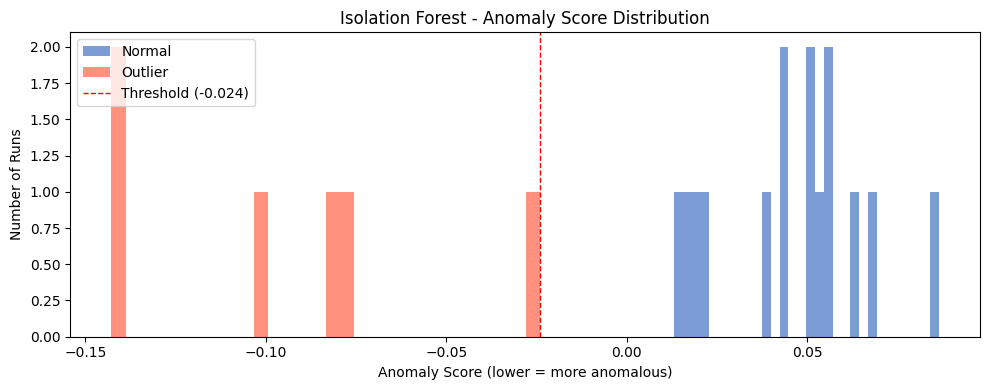

In [7]:
scores = comparison_df["anomaly_score"].dropna()
mask = comparison_df.loc[scores.index, "is_outlier"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(scores[~mask], bins=30, alpha=0.7, label="Normal", color=COLOR_BASELINE)
ax.hist(scores[mask], bins=30, alpha=0.7, label="Outlier", color="tomato")

threshold = scores[mask].max() if mask.any() else scores.min()
ax.axvline(threshold, color="red", linestyle="--", linewidth=1, label=f"Threshold ({threshold:.3f})")

ax.set_xlabel("Anomaly Score (lower = more anomalous)")
ax.set_ylabel("Number of Runs")
ax.set_title("Isolation Forest - Anomaly Score Distribution")
ax.legend()
plt.tight_layout()
save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, "outlier_score_distribution", PLOT_FORMAT, True)

In [8]:
# --- Top feature contributions per outlier (z-scores within each topology type) ---
if comparison_df["is_outlier"].any():
    rows = []
    top_n = 8

    for ttype in sorted(comparison_df["topology_type"].unique()):
        tmask = comparison_df["topology_type"] == ttype
        outlier_mask = tmask & comparison_df["is_outlier"]
        if not outlier_mask.any():
            continue

        X_t = comparison_df.loc[tmask, _feature_cols].copy()
        X_t = X_t.dropna(axis=1, how="all").fillna(X_t.median())

        _med = X_t.median()
        _mad = X_t.sub(_med).abs().median().replace(0, float("nan"))
        Z = X_t.sub(_med).div(_mad)

        for idx in comparison_df.index[outlier_mask]:
            zrow = Z.loc[idx].dropna().abs().nlargest(top_n)
            label = comparison_df.loc[idx, "label"]
            score = comparison_df.loc[idx, "anomaly_score"]
            for feat, zval in zrow.items():
                rows.append({
                    "topology_type": ttype,
                    "run": label,
                    "anomaly_score": round(score, 3),
                    "feature": feat,
                    "z_score": round(Z.loc[idx, feat], 2),
                    "direction": "high" if Z.loc[idx, feat] > 0 else "low",
                    "value": round(comparison_df.loc[idx, feat], 3),
                    "median": round(_med[feat], 3),
                })

    print("Top feature deviations per outlier (MAD-scaled z-scores within topology type):")
    display(pd.DataFrame(rows))
else:
    print("No outliers to explain.")

Top feature deviations per outlier (MAD-scaled z-scores within topology type):


,topology_type,run,anomaly_score,feature,z_score,direction,value,median
0,baseline,t120 u10M k1M,-0.024,gauge_avg_data_perturbation_contributions_this...,43.63,high,1.699012e+04,3127.719
1,baseline,t120 u10M k1M,-0.024,ecall_time_checkAndClamp_s,13.07,high,1.924000e+00,0.370
2,baseline,t120 u10M k1M,-0.024,counter_user_contribution_bounding_forwarded,9.81,high,2.099585e+07,5469127.000
3,baseline,t120 u10M k1M,-0.024,ecall_avg_user_contribution_bounding_checkAndC...,5.43,high,1.000000e-03,0.001
4,baseline,t120 u10M k1M,-0.024,ecall_time_addContribution_s,2.64,high,1.381000e+00,0.574
5,baseline,t120 u10M k1M,-0.024,ecall_avg_histogram_aggregation_mergePartial_ms,2.30,high,9.200000e-02,0.048
6,baseline,t120 u10M k1M,-0.024,ecall_time_mergePartial_s,2.30,high,7.400000e-02,0.038
7,baseline,t120 u10M k1M,-0.024,ecall_avg_data_perturbation_snapshot_ms,1.58,high,2.269070e+02,159.164
8,baseline,t240 u10M k1M,-0.143,gauge_avg_data_perturbation_contributions_this...,58.18,high,2.160967e+04,3127.719
9,baseline,t240 u10M k1M,-0.143,ecall_time_checkAndClamp_s,19.49,high,2.687000e+00,0.370


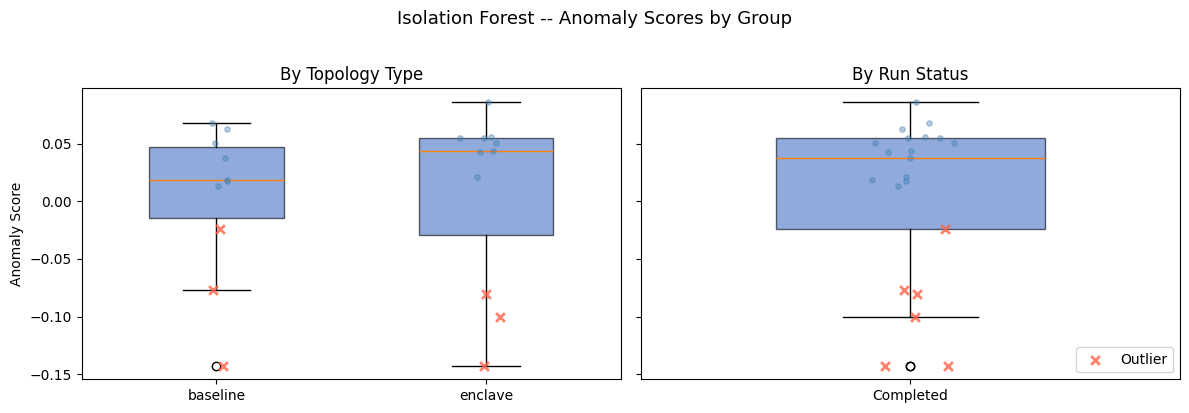

In [9]:
# --- Anomaly scores by topology type and status ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for i, (col, title) in enumerate([
    ("topology_type", "By Topology Type"),
    ("status", "By Run Status"),
]):
    ax = axes[i]
    groups = comparison_df.groupby(col)["anomaly_score"]
    labels = sorted(groups.groups.keys())
    data = [groups.get_group(l).values for l in labels]
    bp = ax.boxplot(data, tick_labels=labels, patch_artist=True, widths=0.5)
    for patch in bp["boxes"]:
        patch.set_facecolor(COLOR_BASELINE)
        patch.set_alpha(0.6)

    for j, label in enumerate(labels):
        subset = comparison_df[comparison_df[col] == label]
        normal = subset[~subset["is_outlier"]]
        outliers = subset[subset["is_outlier"]]
        ax.scatter(
            np.full(len(normal), j + 1) + np.random.normal(0, 0.04, len(normal)),
            normal["anomaly_score"], alpha=0.4, s=15, color="steelblue", zorder=3,
        )
        ax.scatter(
            np.full(len(outliers), j + 1) + np.random.normal(0, 0.04, len(outliers)),
            outliers["anomaly_score"], alpha=0.8, s=40, color="tomato", marker="x",
            linewidths=2, zorder=4, label="Outlier" if j == 0 else "",
        )

    ax.set_title(title)
    ax.set_ylabel("Anomaly Score" if i == 0 else "")

if comparison_df["is_outlier"].any():
    axes[1].legend(loc="lower right")

fig.suptitle("Isolation Forest -- Anomaly Scores by Group", fontsize=13, y=1.02)
plt.tight_layout()
save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, "outlier_scores_by_group", PLOT_FORMAT, True)

In [10]:
# Build matched pairs for baseline vs confidential comparison
matched = build_matched_pairs(comparison_df)
if matched.empty:
    print("No matched pairs found (need both baseline and enclave runs with matching parameters)")
else:
    print(f"Matched {len(matched)} parameter configurations across baseline and confidential")
    display_cols = ["label"] + [c for c in ["duration_secs_base", "duration_secs_conf", "duration_secs_ratio",
                                            "startup_elapsed_secs_base", "startup_elapsed_secs_conf",
                                            "avg_epoch_duration_s_base", "avg_epoch_duration_s_conf",
                                            "avg_snapshot_duration_s_base", "avg_snapshot_duration_s_conf"]
                                if c in matched.columns]
    styled_summary_table(matched, columns=display_cols, status_col="")

Matched 10 parameter configurations across baseline and confidential


---
# Section A: Overhead Analysis (Baseline vs Confidential)

Direct comparison of baseline and confidential runs that share the same parameter configurations.
This section quantifies the performance overhead of SGX enclaves and Teaclave encryption.

### A1: Startup Overhead

Enclave initialization (loading native images into SGX, establishing encrypted channels) adds significant startup time compared to the baseline.

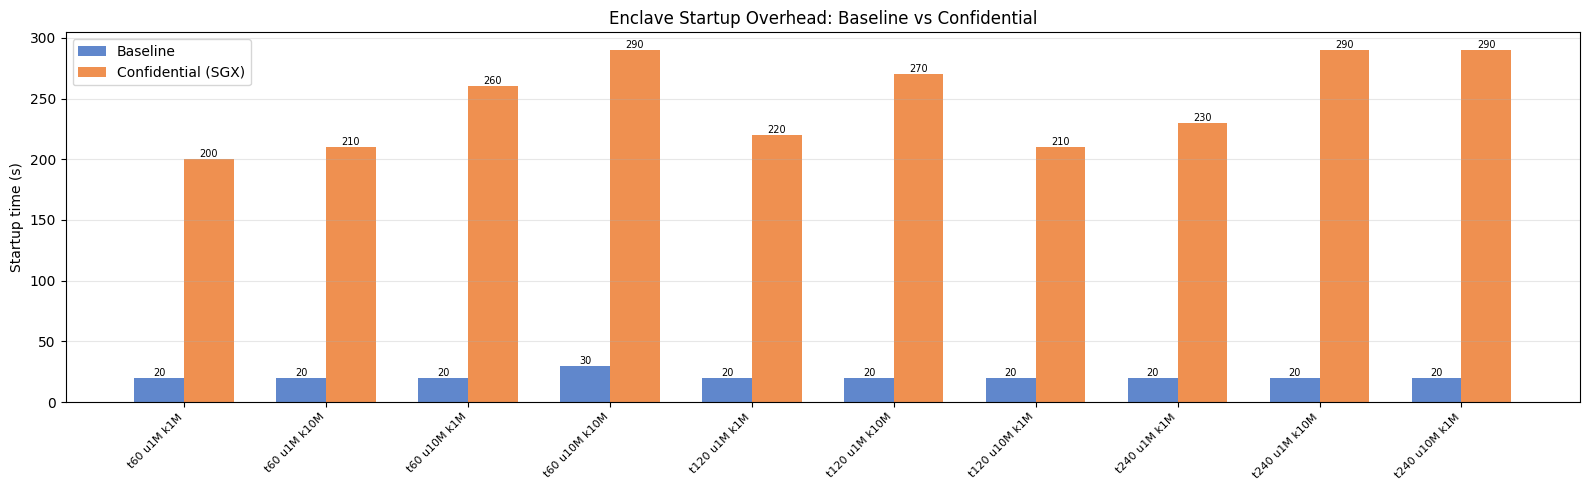

In [11]:
if not matched.empty and "startup_elapsed_secs_base" in matched.columns:
    paired_bar_chart(
        matched, "startup_elapsed_secs",
        ylabel="Startup time (s)",
        title="Enclave Startup Overhead: Baseline vs Confidential",
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        plot_name="a1-startup-overhead",
        fmt=PLOT_FORMAT,
    )
else:
    print("Skipped: no matched pairs available")

### A2: Snapshot Latency Overhead

Scatter plot comparing snapshot computation time between baseline and confidential.
Points above the diagonal (y=x) indicate confidential overhead. The distance from the diagonal shows the encryption + SGX cost.

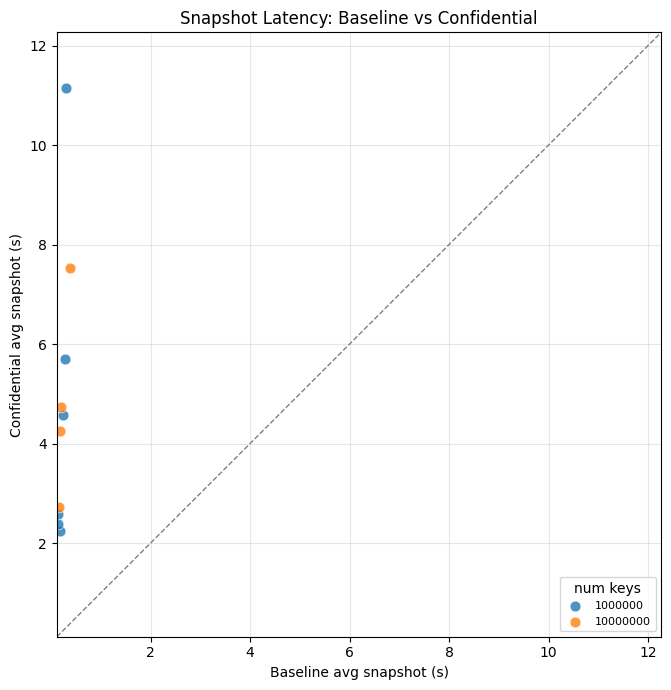

In [12]:
if not matched.empty and "avg_snapshot_duration_s_base" in matched.columns:
    # Determine a good hue column
    hue = None
    for candidate in ["num_keys", "max_time_steps", "parallelism"]:
        if candidate in matched.columns and matched[candidate].nunique() > 1:
            hue = candidate
            break

    overhead_scatter(
        matched, "avg_snapshot_duration_s",
        hue_col=hue,
        xlabel="Baseline avg snapshot (s)",
        ylabel="Confidential avg snapshot (s)",
        title="Snapshot Latency: Baseline vs Confidential",
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        plot_name="a2-snapshot-scatter",
        fmt=PLOT_FORMAT,
    )
else:
    print("Skipped: no matched pairs with snapshot data")

### A3: Per-ECALL Overhead Heatmap

Overhead ratio (confidential / baseline) for each ECALL across configurations.

> NOTE: Values > 1.0 (red) indicate encryption overhead; values near 1.0 (green) indicate negligible overhead.

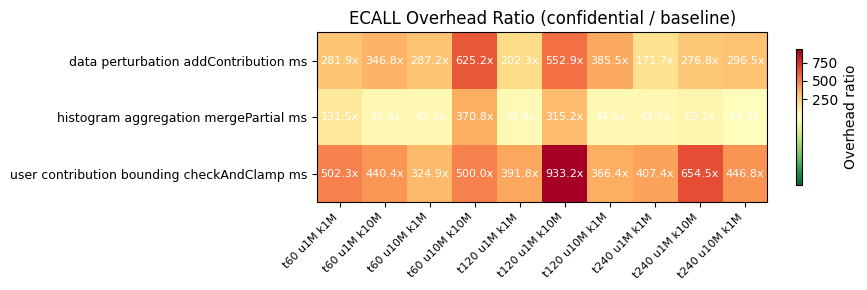

In [13]:
if not matched.empty:
    # Discover matching ecall columns between baseline and confidential
    base_ecall_cols = [c for c in matched.columns if c.startswith("ecall_avg_") and c.endswith("_base")]
    conf_ecall_cols = [c for c in matched.columns if c.startswith("ecall_avg_") and c.endswith("_conf")]

    # Build ecall pairs: (display_name, base_col_without_suffix, conf_col_without_suffix)
    ecall_pairs = []

    # Map: strip suffix to get the root column name
    base_roots = {c.removesuffix("_base"): c for c in base_ecall_cols}
    conf_roots = {c.removesuffix("_conf"): c for c in conf_ecall_cols}

    # Direct matches (same ecall name in both)
    for root in sorted(set(base_roots) & set(conf_roots)):
        label = root.removeprefix("ecall_avg_").replace("_", " ")
        ecall_pairs.append((label, root, root))

    # Mapped matches (snapshot -> getEncryptedSnapshot)
    for base_root in base_roots:
        base_name = base_root.split("_")[-2] + "_" + base_root.split("_")[-1] if "_" in base_root else base_root
        # Check if "snapshot" maps to "getEncryptedSnapshot"
        if "snapshot_ms" in base_root and base_root not in conf_roots:
            # Look for the encrypted variant
            for conf_root in conf_roots:
                if "getEncryptedSnapshot" in conf_root:
                    label = "snapshot vs getEncryptedSnapshot"
                    ecall_pairs.append((label, base_root, conf_root))
                    break

    if ecall_pairs:
        ecall_overhead_heatmap(
            matched, ecall_pairs,
            title="ECALL Overhead Ratio (confidential / baseline)",
            output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
            plot_name="a3-ecall-overhead",
            fmt=PLOT_FORMAT,
        )
    else:
        print("No matching ECALL columns found between baseline and confidential")
else:
    print("Skipped: no matched pairs available")

### A4: Total Duration Breakdown

Stacked bars showing where time is spent: startup, snapshot computation, and other active processing.
Reveals whether overhead is dominated by enclave initialization or by per-operation encryption cost.

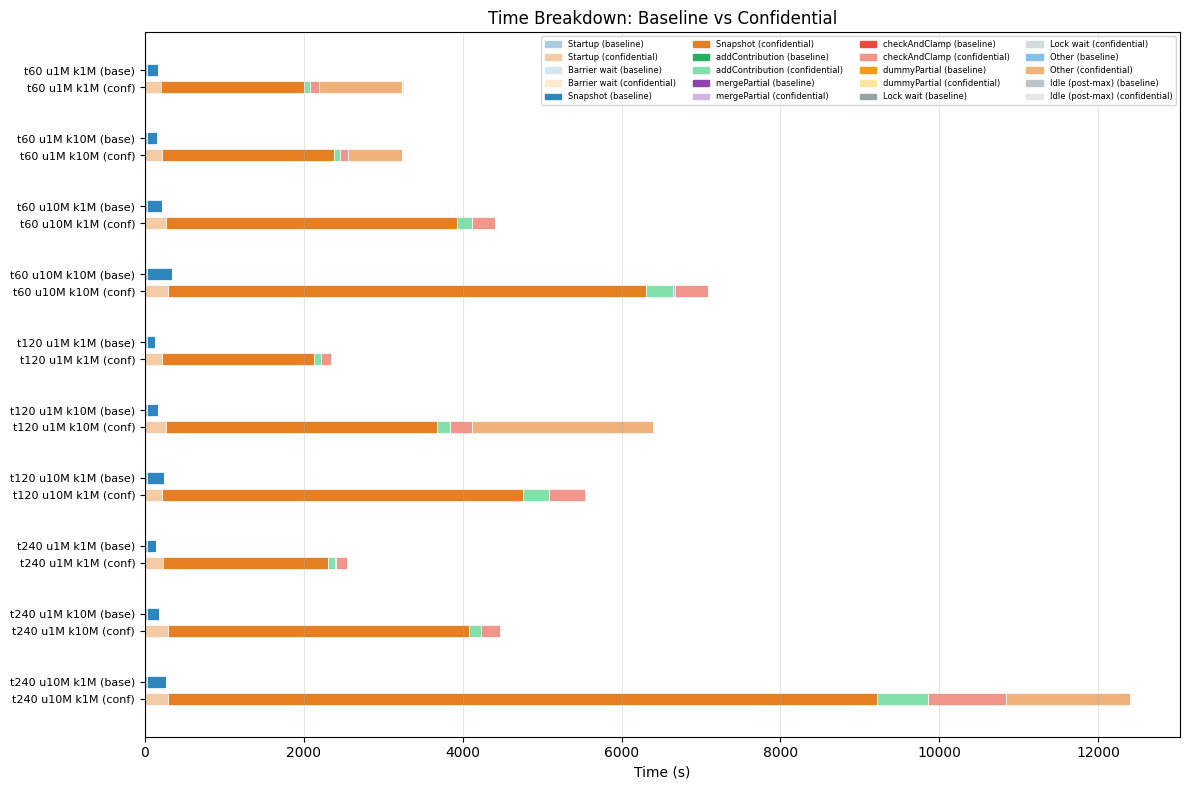

In [14]:
if not matched.empty:
    duration_breakdown_stacked(
        matched,
        title="Time Breakdown: Baseline vs Confidential",
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        plot_name="a4-duration-breakdown",
        fmt=PLOT_FORMAT,
    )
else:
    print("Skipped: no matched pairs available")

### A5: Epoch Duration - Paired Box Plots

Distribution of epoch durations comparing baseline vs confidential. Subplot rows are grouped by workload size (num_users × num_keys), columns by configuration (parallelism x tick frequency).

Every configuration across both topology types should result in the same epoch duration (reminder: epoch duration depends completely on tick interval)

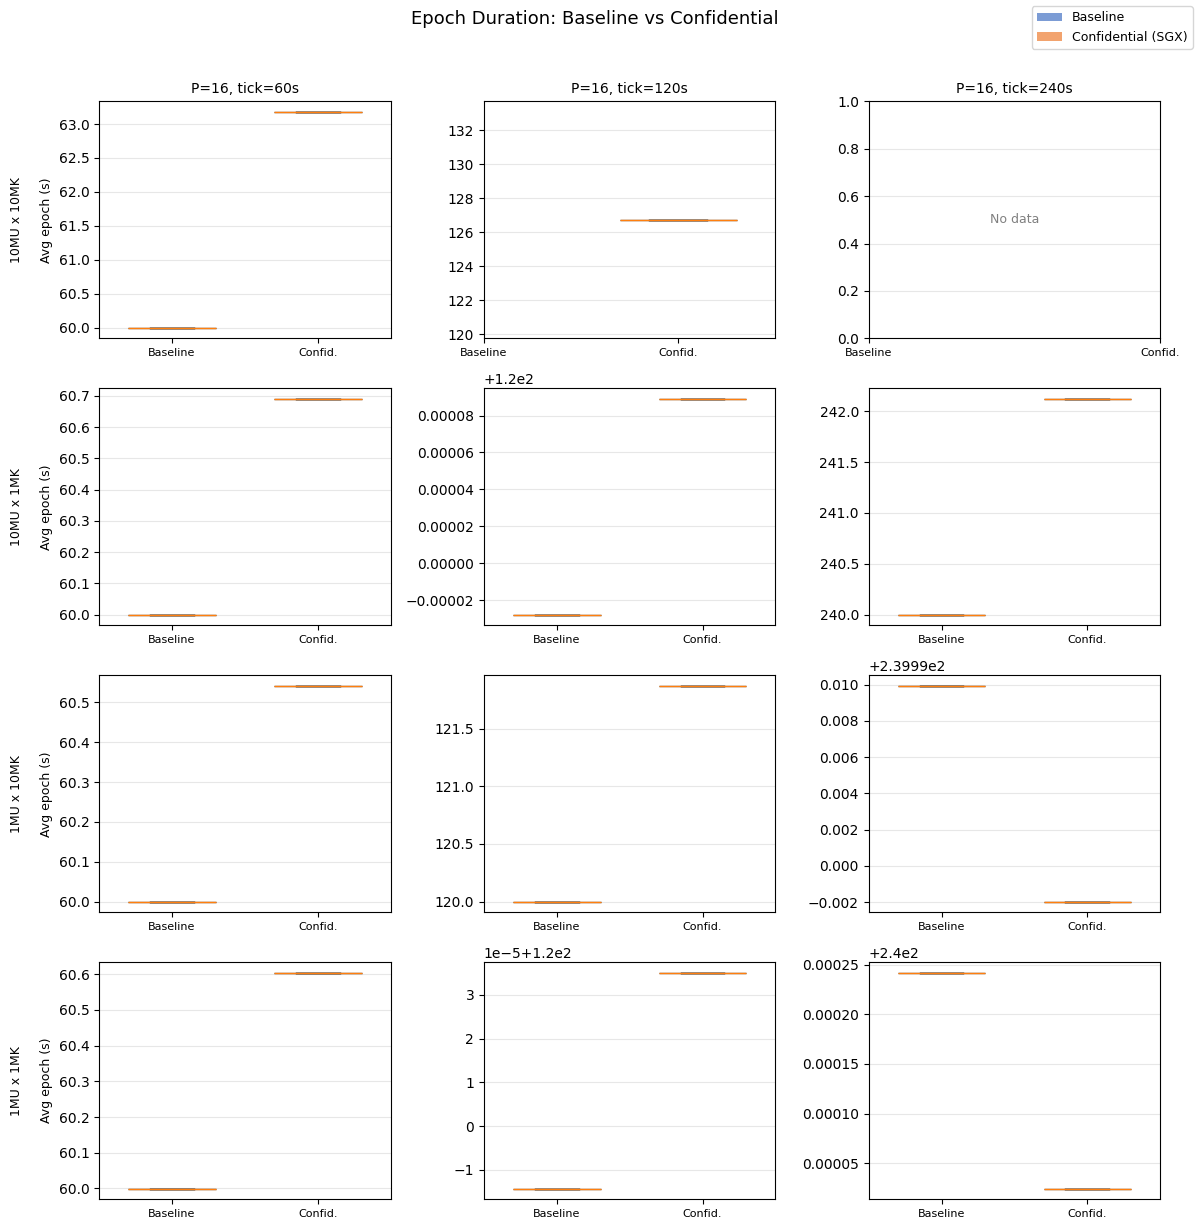

In [15]:
# Subplot grid: rows = workload (users × keys), cols = config (parallelism × tick)
required = {"avg_epoch_duration_s", "num_users", "num_keys", "parallelism", "tick_interval_secs", "topology_type"}
if required.issubset(perf_df.columns):
    perf_df["workload"] = (
        perf_df["num_users"].map(compact_number) + "U x " + perf_df["num_keys"].map(compact_number) + "K"
    )
    perf_df["config"] = (
        "P=" + perf_df["parallelism"].astype(str)
        + ", tick=" + perf_df["tick_interval_secs"].astype(str) + "s"
    )

    # Build config order: sort by tick_interval_secs first, then parallelism
    config_order = (
        perf_df[["tick_interval_secs", "parallelism", "config"]]
        .drop_duplicates()
        .sort_values(["tick_interval_secs", "parallelism"])
        ["config"].tolist()
    )

    workloads = sorted(perf_df["workload"].unique())
    configs = config_order
    nrows, ncols = len(workloads), len(configs)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(max(4 * ncols, 6), max(3 * nrows, 4)),
        squeeze=False,
    )

    for r, wl in enumerate(workloads):
        for c, cfg in enumerate(configs):
            ax = axes[r, c]
            sub = perf_df[(perf_df["workload"] == wl) & (perf_df["config"] == cfg)]
            b = sub.loc[sub["topology_type"] == "baseline", "avg_epoch_duration_s"].dropna().values
            e = sub.loc[sub["topology_type"] == "enclave", "avg_epoch_duration_s"].dropna().values

            box_data, positions, colors = [], [], []
            if len(b) > 0:
                box_data.append(b); positions.append(0); colors.append(COLOR_BASELINE)
            if len(e) > 0:
                box_data.append(e); positions.append(1); colors.append(COLOR_CONFIDENTIAL)

            if box_data:
                bp = ax.boxplot(box_data, positions=positions, widths=0.6, patch_artist=True)
                for patch, col in zip(bp["boxes"], colors):
                    patch.set_facecolor(col)
                    patch.set_alpha(0.7)
            else:
                ax.text(0.5, 0.5, "No data", ha="center", va="center", transform=ax.transAxes, fontsize=9, color="gray")

            ax.set_xticks([0, 1])
            ax.set_xticklabels(["Baseline", "Confid."], fontsize=8)
            ax.grid(True, axis="y", alpha=0.3)

            if r == 0:
                ax.set_title(cfg, fontsize=10)
            if c == 0:
                ax.set_ylabel(wl + "\n\nAvg epoch (s)", fontsize=9)

    legend_handles = [
        mpatches.Patch(facecolor=COLOR_BASELINE, alpha=0.7, label="Baseline"),
        mpatches.Patch(facecolor=COLOR_CONFIDENTIAL, alpha=0.7, label="Confidential (SGX)"),
    ]
    fig.legend(handles=legend_handles, loc="upper right", fontsize=9)
    fig.suptitle("Epoch Duration: Baseline vs Confidential", fontsize=13, y=1.02)
    fig.tight_layout()

    if SAVE_PLOTS:
        save_or_show(fig, OUTPUT_DIR, "a5-epoch-boxplot", PLOT_FORMAT, show=True)
    else:
        plt.show()
else:
    print(f"Skipped: need columns {required - set(perf_df.columns)}")

#### A5b: Throughput-Normalized Epoch Comparison

Epoch duration is misleading: the baseline processes far more tuples per epoch (higher throughput) than the confidential runs, which have much lower throughput due to SGX overhead. 

This means that if we see baseline epochs are longer, it may be because they are doing more work, not because they are slower.

This plot normalizes by showing:
- **Tuples processed per second** (forwarded contributions / active duration) - true throughput
- **Epoch duration vs. tuples per epoch** scatter - reveals whether shorter epochs come from less work or more speed

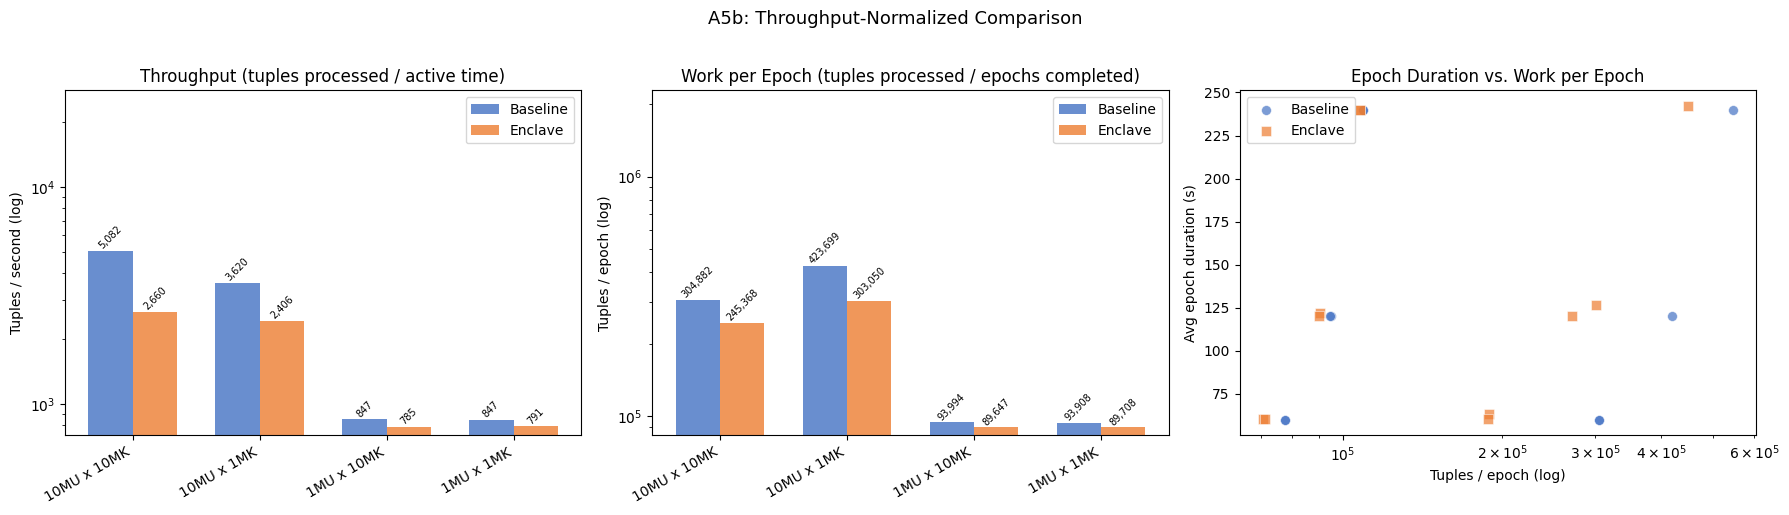

In [16]:
# --- Find the best proxy for "tuples processed" ---
# Prefer contribution_bounding forwarded; fall back to data_perturbation real_emissions
_forwarded_col = None
for candidate in sorted(perf_df.columns):
    if "forwarded" in candidate and candidate.startswith("counter_"):
        _forwarded_col = candidate
        break
if _forwarded_col is None:
    for candidate in sorted(perf_df.columns):
        if "real_emissions" in candidate and candidate.startswith("counter_"):
            _forwarded_col = candidate
            break

if (
    _forwarded_col is not None
    and "avg_epoch_duration_s" in perf_df.columns
    and "active_duration_s" in perf_df.columns
    and "max_epoch_completed" in perf_df.columns
    and "topology_type" in perf_df.columns
    and "num_users" in perf_df.columns
    and "num_keys" in perf_df.columns
):
    _df = perf_df.copy()
    _df["workload"] = _df["num_users"].map(compact_number) + "U x " + _df["num_keys"].map(compact_number) + "K"

    # Derived metrics
    _df["throughput_tuples_per_s"] = _df[_forwarded_col] / _df["active_duration_s"]
    _df["tuples_per_epoch"] = _df[_forwarded_col] / _df["max_epoch_completed"].clip(lower=1)

    # Detect actual topology type labels from the data
    _ttypes = sorted(_df["topology_type"].unique())
    _ttype_colors = {t: (COLOR_BASELINE if "base" in t.lower() else COLOR_CONFIDENTIAL) for t in _ttypes}

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    def _bar_panel(ax, metric, ylabel, title, workloads, x, width):
        """Draw a paired bar chart with log scale and value labels."""
        n_types = len(_ttypes)
        for j, ttype in enumerate(_ttypes):
            vals = []
            for w in workloads:
                sub = _df[(_df["workload"] == w) & (_df["topology_type"] == ttype)]
                vals.append(sub[metric].mean() if len(sub) > 0 else 0)
            offset = (j - (n_types - 1) / 2) * width
            bars = ax.bar(x + offset, vals, width,
                          label=ttype.capitalize(), color=_ttype_colors[ttype], alpha=0.8)
            for bar, v in zip(bars, vals):
                if v > 0:
                    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                            f"{v:,.0f}", ha="center", va="bottom", fontsize=7, rotation=45)
        ax.set_yscale("log")
        # Add top padding so labels don't overflow (expand upper limit by ~3x on log scale)
        ymin, ymax = ax.get_ylim()
        ax.set_ylim(ymin, ymax * 5)
        ax.set_xticks(x)
        ax.set_xticklabels(workloads, rotation=30, ha="right")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend()

    workloads = sorted(_df["workload"].unique())
    x = np.arange(len(workloads))
    width = 0.35

    # --- Panel 1: Throughput (tuples/s) ---
    _bar_panel(axes[0], "throughput_tuples_per_s", "Tuples / second (log)",
               "Throughput (tuples processed / active time)", workloads, x, width)

    # --- Panel 2: Tuples per epoch ---
    _bar_panel(axes[1], "tuples_per_epoch", "Tuples / epoch (log)",
               "Work per Epoch (tuples processed / epochs completed)", workloads, x, width)

    # --- Panel 3: Scatter -- epoch duration vs tuples per epoch ---
    ax = axes[2]
    _markers = ["o", "s", "^", "D"]
    for i, ttype in enumerate(_ttypes):
        sub = _df[_df["topology_type"] == ttype]
        ax.scatter(
            sub["tuples_per_epoch"], sub["avg_epoch_duration_s"],
            c=_ttype_colors[ttype], marker=_markers[i % len(_markers)],
            alpha=0.7, s=50, label=ttype.capitalize(), edgecolors="white", linewidths=0.5,
        )
    ax.set_xscale("log")
    ax.set_xlabel("Tuples / epoch (log)")
    ax.set_ylabel("Avg epoch duration (s)")
    ax.set_title("Epoch Duration vs. Work per Epoch")
    ax.legend()

    fig.suptitle(f"A5b: Throughput-Normalized Comparison", fontsize=13, y=1.02)
    plt.tight_layout()
    save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, "a5b-throughput-normalized", PLOT_FORMAT, True)
else:
    missing = []
    if _forwarded_col is None:
        missing.append("no forwarded/real_emissions counter found")
    for c in ["avg_epoch_duration_s", "active_duration_s", "max_epoch_completed", "num_users", "num_keys"]:
        if c not in perf_df.columns:
            missing.append(c)
    print(f"Skipped A5b: missing {', '.join(missing)}")

$\textcolor{red}{\text{FIXME: This plots groups runs with totally differnet tick intervals -- this is not a fair comparison because tick interval directly affects epoch duration and tuples per epoch. We should group by tick interval to make sure we are comparing runs that have the same expected workload per epoch.}}$

From the results above we can see that the confidential runs have much lower throughput (fewer tuples processed per second) that the baseline -- this is expected due to SGX overhead.

We can also see that the `num_useres` and `num_keys` parameters have a significant impact on throughput: higher values lead to more tuples per epoch, which in turn leads to longer epoch durations. This is especially pronounced in the confidential runs, where the overhead of processing more tuples is much higher.

---
# Section B: Parameter Sensitivity Exploration

How do different parameters affect performance? To answer this question, the following visualizations explore trends across the parameter grid across both baseline and confidential configurations.

### B1: Parameter Interaction Heatmaps

2D heatmaps showing how pairs of parameters affect key metrics, side-by-side for baseline and confidential to understand how SGX overhead impacts different configurations.

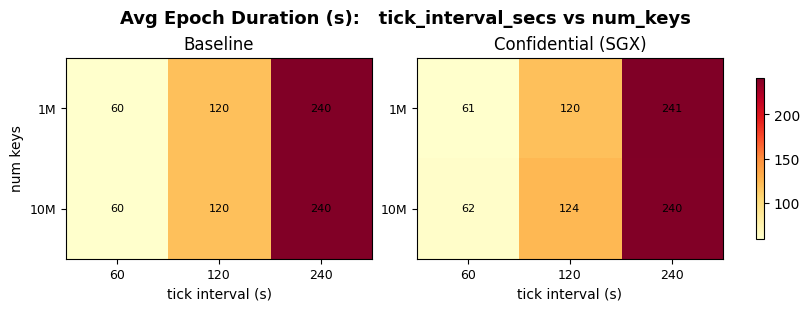

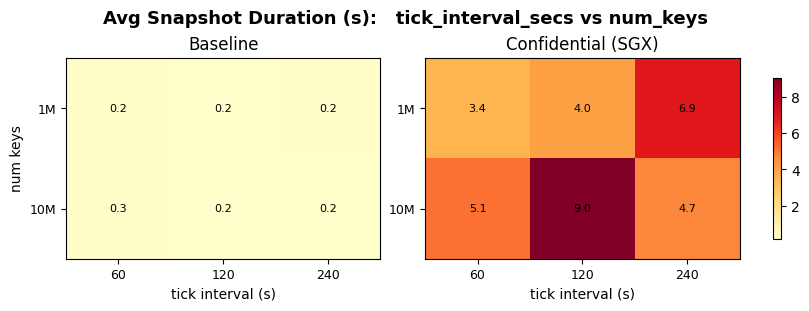

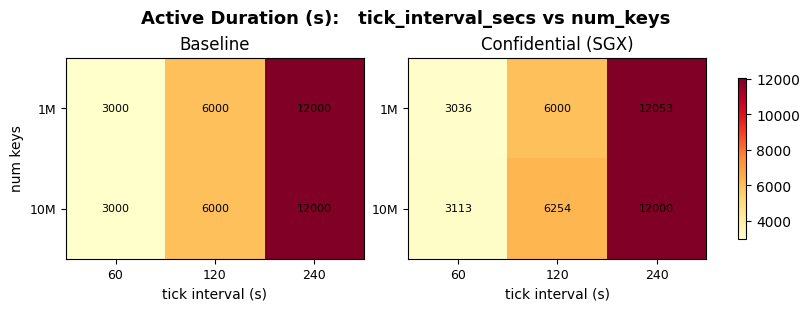

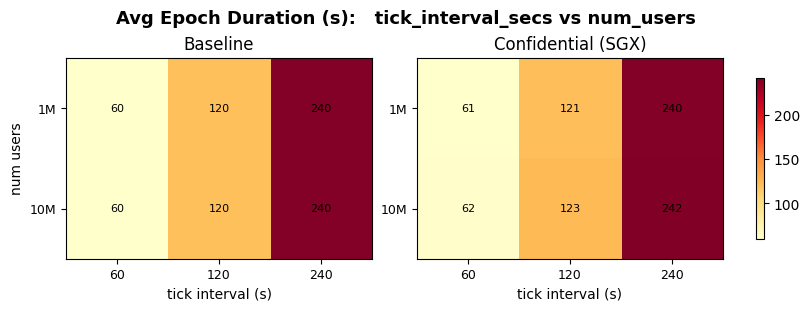

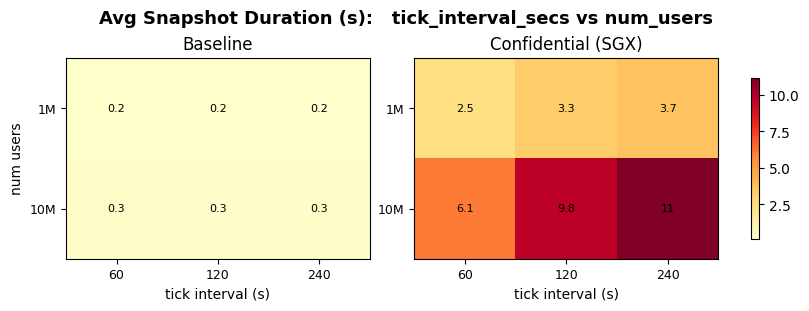

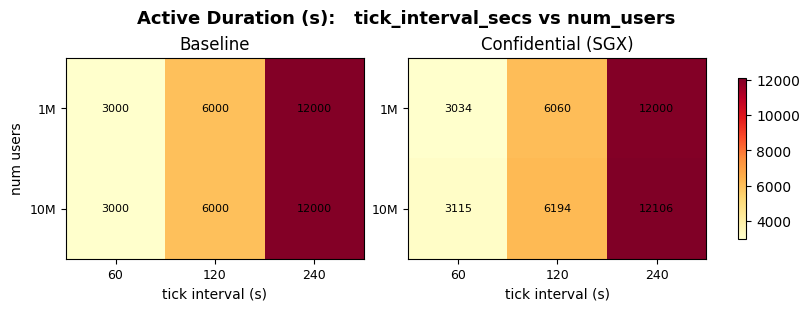

In [51]:
# Define interesting parameter pairs and metrics
param_pairs = []
for x, y in [("tick_interval_secs", "num_keys"), 
            ("tick_interval_secs", "num_users"),
             ("parallelism", "num_users"),
             ("tick_interval_secs", "parallelism")]:
    if x in perf_vary_cols and y in perf_vary_cols:
        param_pairs.append((x, y))

metrics = [("avg_epoch_duration_s", "Avg Epoch Duration (s)"),
           ("avg_snapshot_duration_s", "Avg Snapshot Duration (s)"),
           ("active_duration_s", "Active Duration (s)")]

for x_param, y_param in param_pairs:
    for metric_col, metric_title in metrics:
        if metric_col not in perf_df.columns:
            continue
        parameter_heatmap_faceted(
            perf_df, x_param, y_param, metric_col,
            title=f"{metric_title}:   {x_param} vs {y_param}",
            output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
            plot_name=f"b1-heatmap-{metric_col}-{x_param}-{y_param}",
            fmt=PLOT_FORMAT,
            base_fig_size=(4, 3),
        )

### B2: Sensitivity Line Plots

For each meaningful (parameter, metric) pair, a subplot grid shows sensitivity lines with confidence bands.

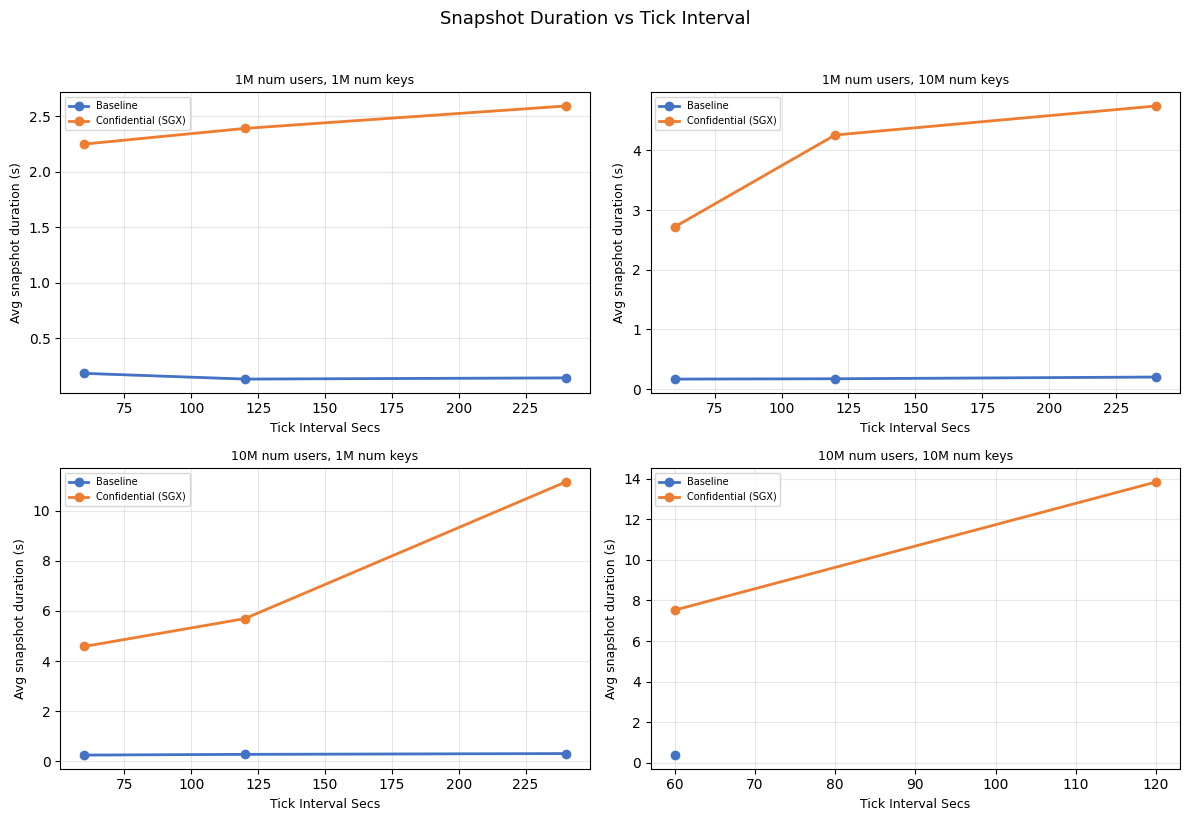

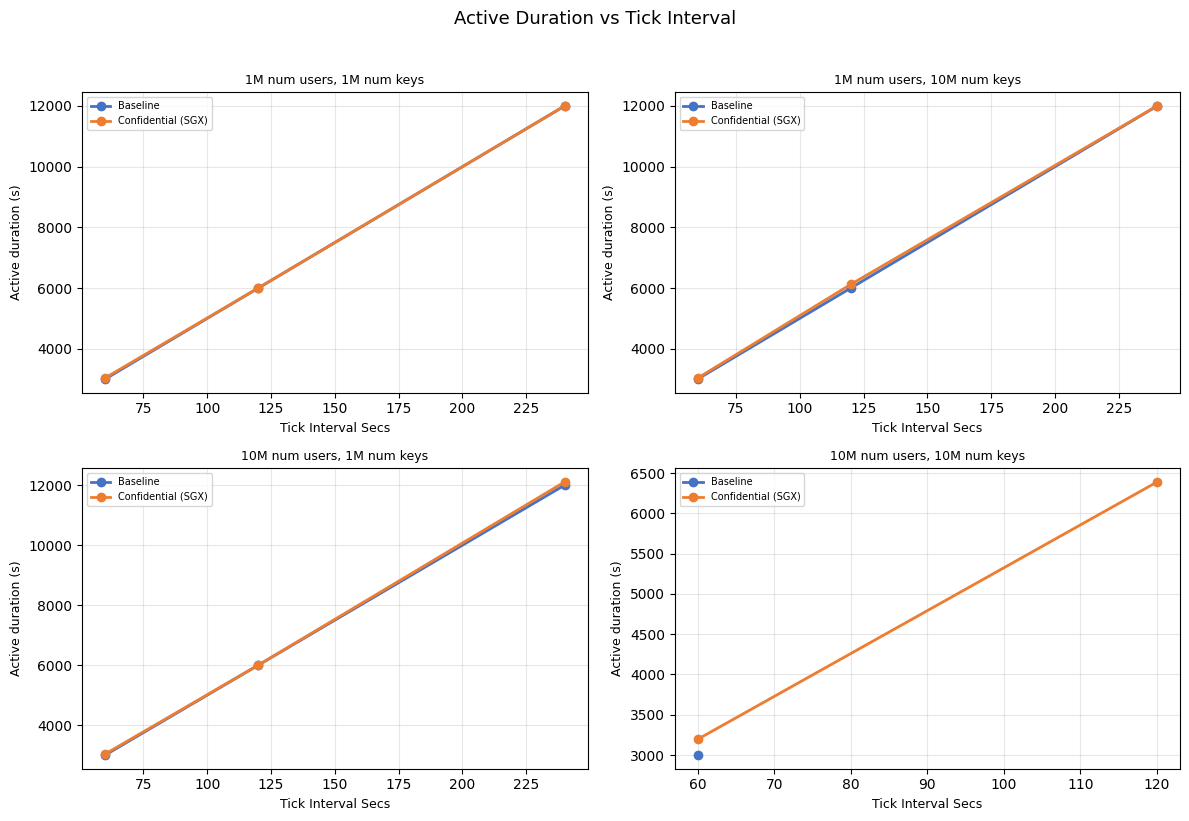

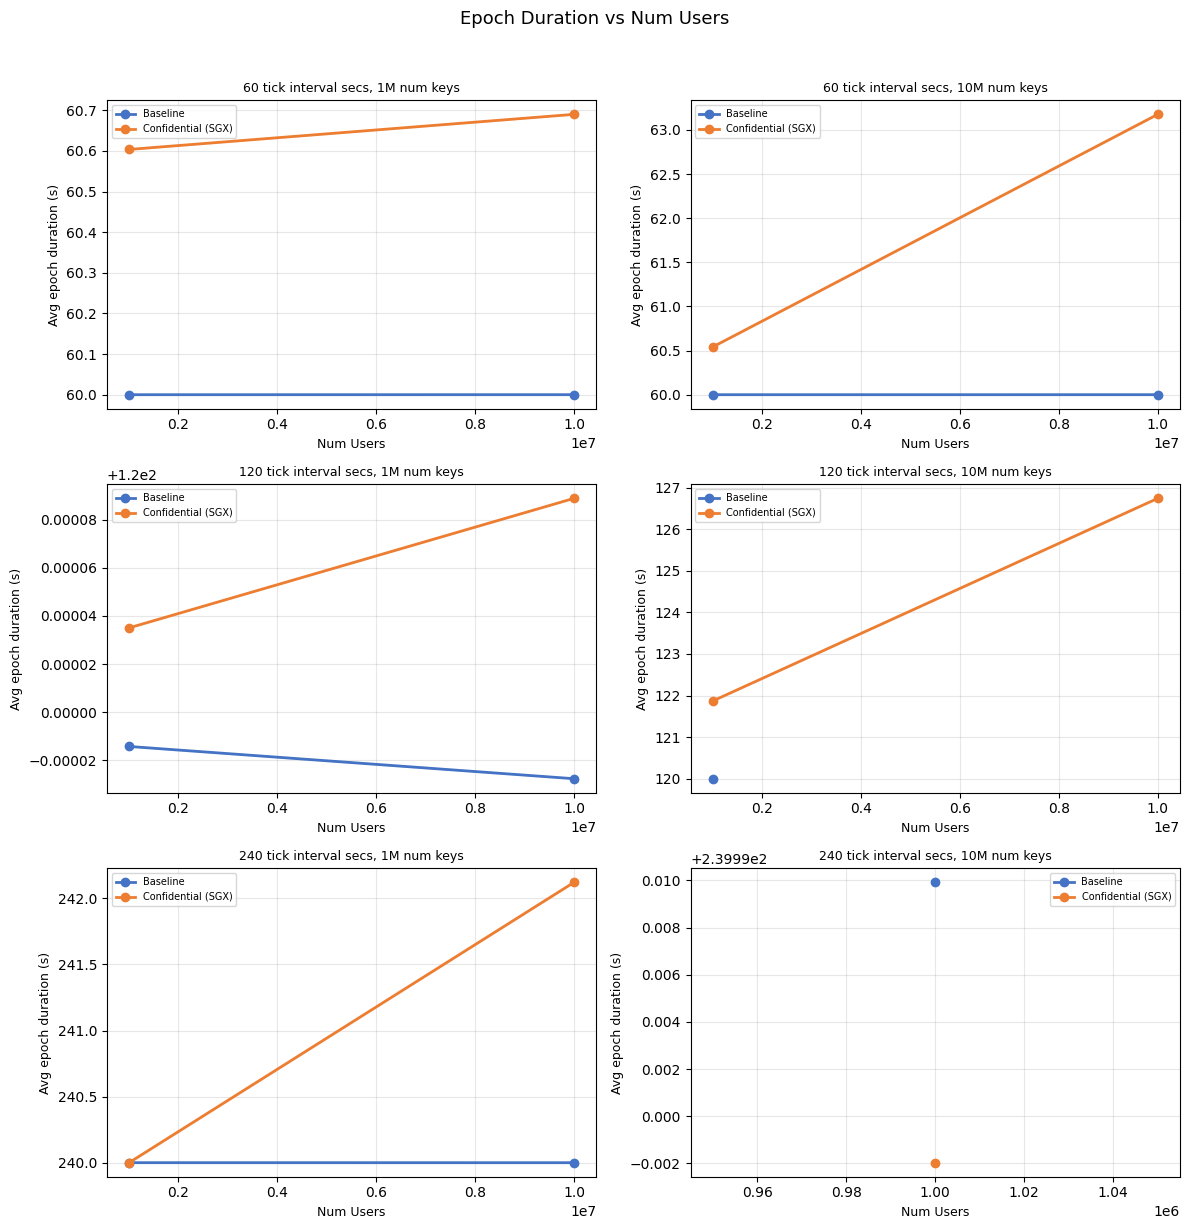

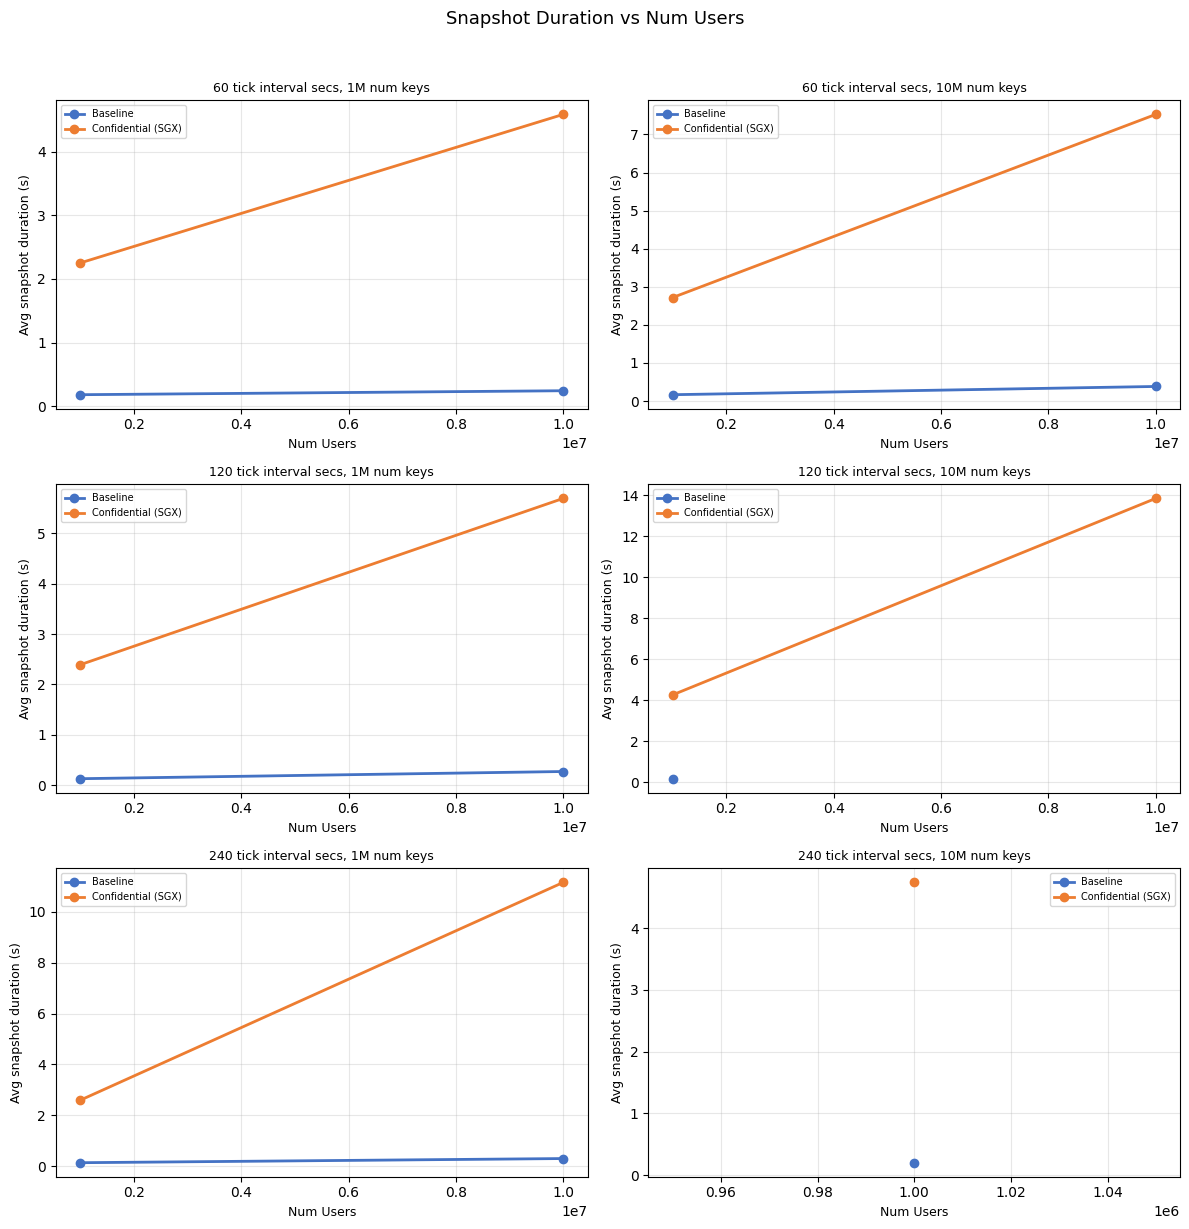

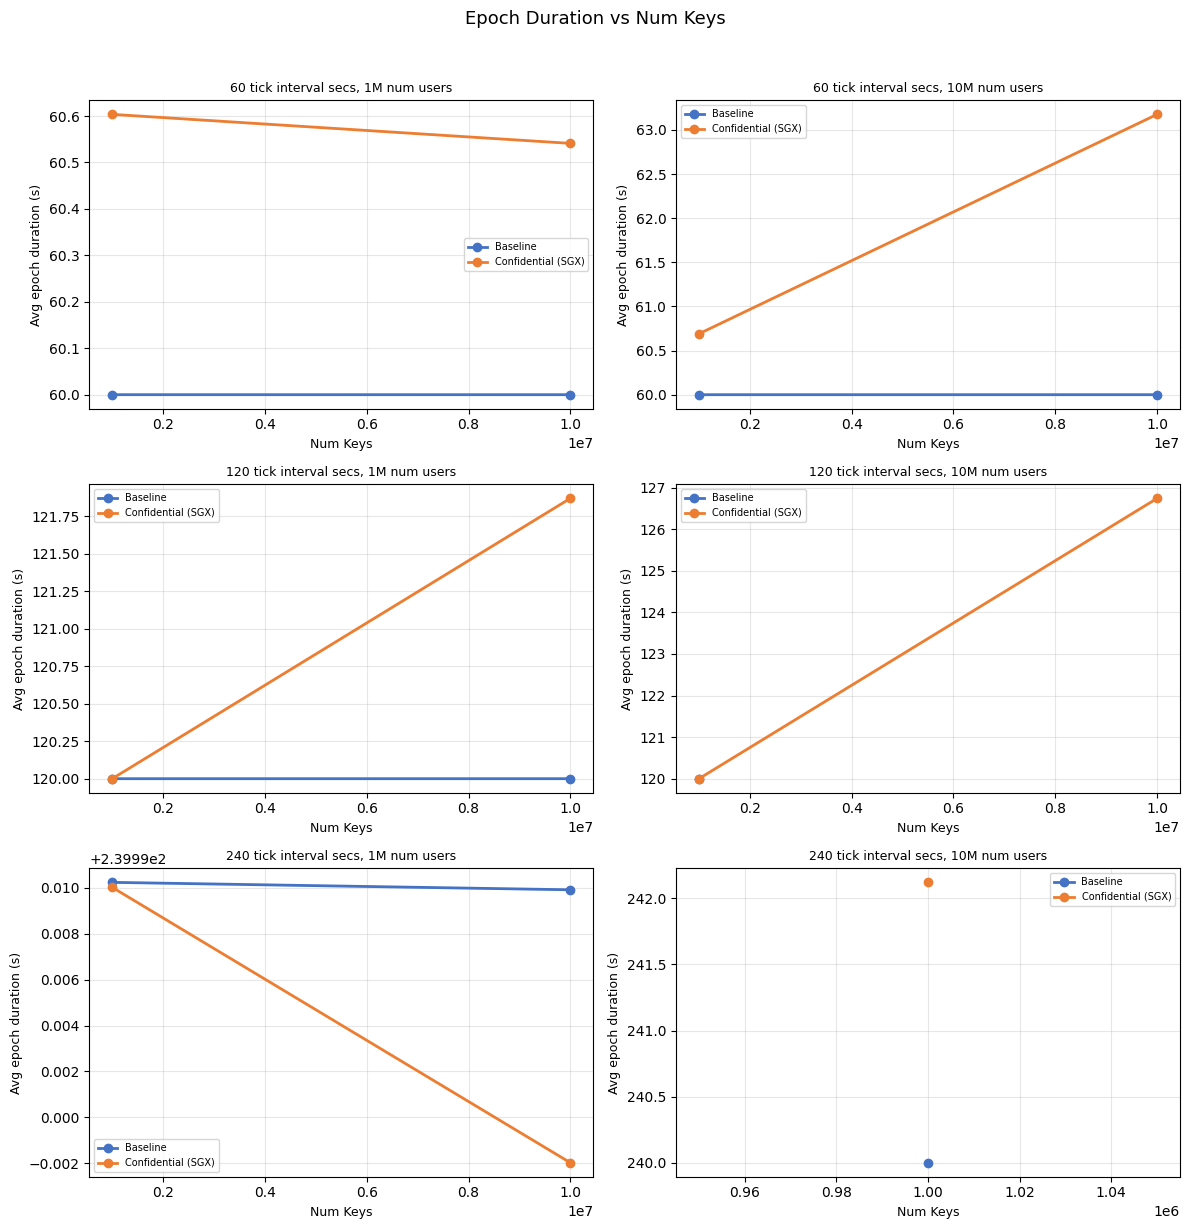

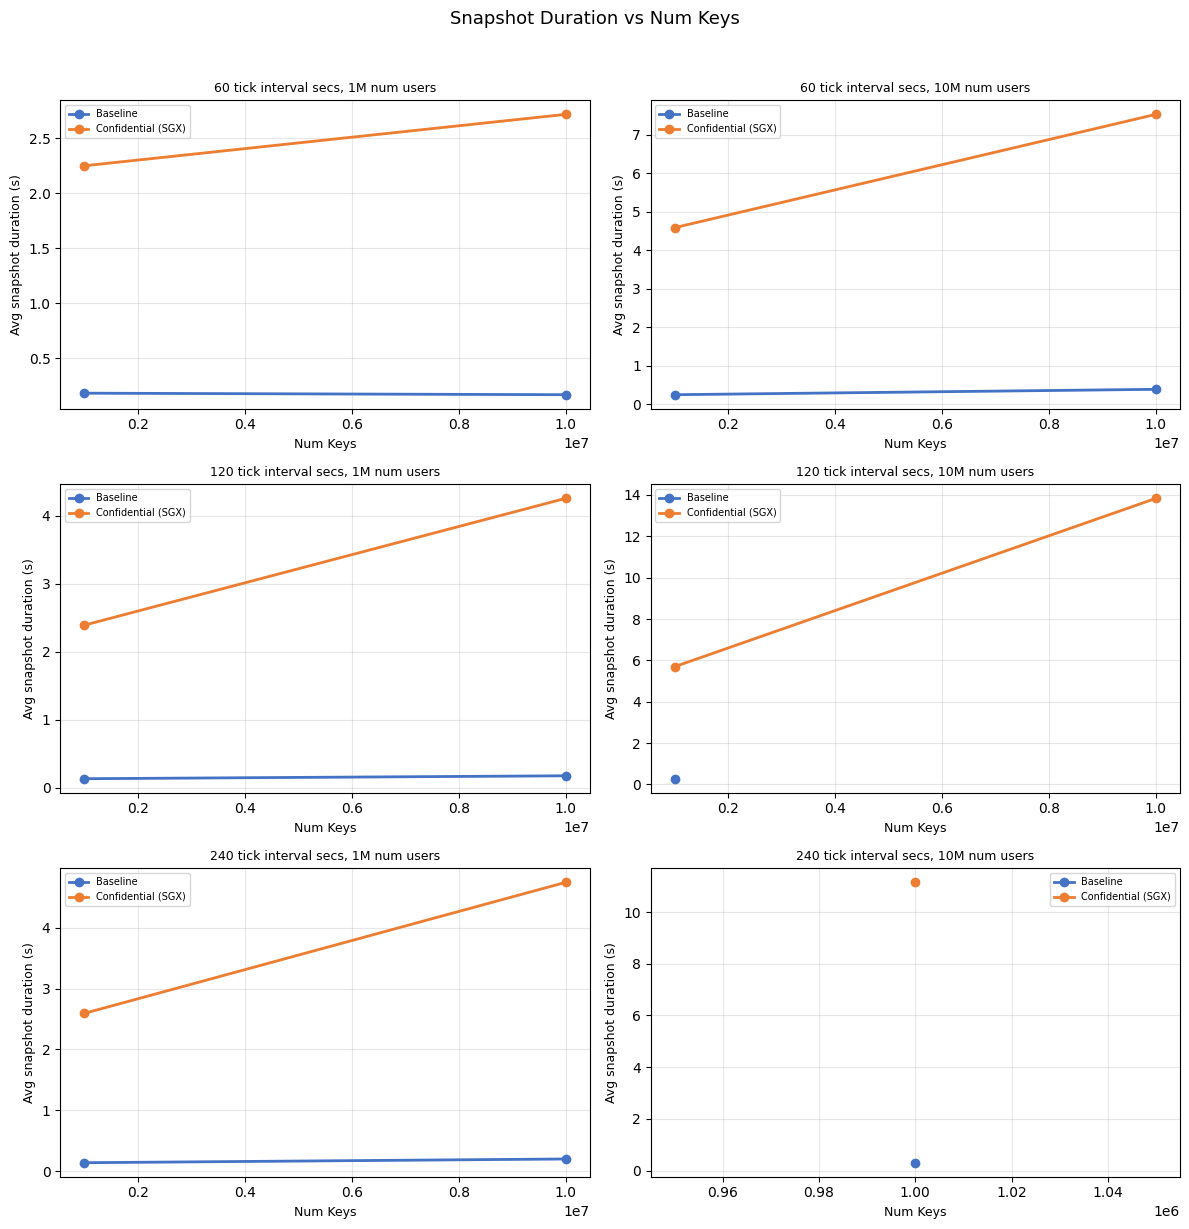

In [18]:
# (sweep_col, metric_col, ylabel, title) combinations that are meaningful
_sensitivity_pairs = [
    ("tick_interval_secs", "avg_snapshot_duration_s", "Avg snapshot duration (s)", "Snapshot Duration vs Tick Interval"),
    ("tick_interval_secs", "active_duration_s",       "Active duration (s)",       "Active Duration vs Tick Interval"),
    ("max_time_steps",     "avg_epoch_duration_s",    "Avg epoch duration (s)",    "Epoch Duration vs Max Time Steps"),
    ("max_time_steps",     "avg_snapshot_duration_s", "Avg snapshot duration (s)", "Snapshot Duration vs Max Time Steps"),
    ("num_users",          "avg_epoch_duration_s",    "Avg epoch duration (s)",    "Epoch Duration vs Num Users"),
    ("num_users",          "avg_snapshot_duration_s", "Avg snapshot duration (s)", "Snapshot Duration vs Num Users"),
    ("num_keys",           "avg_epoch_duration_s",    "Avg epoch duration (s)",    "Epoch Duration vs Num Keys"),
    ("num_keys",           "avg_snapshot_duration_s", "Avg snapshot duration (s)", "Snapshot Duration vs Num Keys"),
]

# All parameter columns that might need to be held constant
_all_params = ["tick_interval_secs", "max_time_steps", "parallelism", "mu", "num_users", "num_keys"]

def _param_label(col: str) -> str:
    """Human-readable label for a parameter column."""
    return col.replace("_", " ").title()

for sweep_col, metric_col, ylabel, title in _sensitivity_pairs:
    if sweep_col not in perf_df.columns or metric_col not in perf_df.columns:
        continue
    # Skip if sweep_col doesn't actually vary
    if perf_df[sweep_col].nunique() <= 1:
        continue

    # Determine which other params to hold constant
    hold_cols = [c for c in _all_params if c != sweep_col and c in perf_df.columns and perf_df[c].nunique() > 1]

    if not hold_cols:
        # Nothing to hold constant -- single sensitivity line is fine
        sensitivity_line(
            perf_df, sweep_col, metric_col,
            ylabel=ylabel, title=title,
            output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
            plot_name=f"b2-sensitivity-{metric_col}-{sweep_col}",
            fmt=PLOT_FORMAT,
        )
        continue

    # Build config groups from the held-constant params
    config_groups = perf_df.groupby(hold_cols, dropna=False).size().reset_index(name="_n").drop(columns="_n")
    n_configs = len(config_groups)

    ncols = min(n_configs, 2)
    nrows = (n_configs + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows), squeeze=False)

    for idx, (_, cfg_row) in enumerate(config_groups.iterrows()):
        r, c = divmod(idx, ncols)
        ax = axes[r, c]

        # Filter to this config group
        mask = pd.Series(True, index=perf_df.index)
        for col in hold_cols:
            mask &= perf_df[col] == cfg_row[col]
        sub = perf_df[mask]

        # Plot baseline and confidential lines
        for ttype, colour, label in [("baseline", COLOR_BASELINE, "Baseline"),
                                      ("enclave", COLOR_CONFIDENTIAL, "Confidential (SGX)")]:
            tsub = sub[sub["topology_type"] == ttype] if "topology_type" in sub.columns else sub
            if tsub.empty:
                continue
            grouped = tsub.groupby(sweep_col)[metric_col].agg(["mean", "std"]).sort_index()
            x = grouped.index.values
            y = grouped["mean"].values
            err = grouped["std"].fillna(0).values
            ax.plot(x, y, marker="o", color=colour, label=label, linewidth=2)
            ax.fill_between(x, y - err, y + err, color=colour, alpha=0.15)

        # Subplot label: show held-constant param values
        cfg_label = ", ".join(
            f"{compact_number(int(cfg_row[col]))} {col.replace('_', ' ')}" for col in hold_cols
        )

        ax.set_title(cfg_label, fontsize=9)
        ax.set_xlabel(_param_label(sweep_col), fontsize=9)
        ax.set_ylabel(ylabel, fontsize=9)
        ax.grid(True, alpha=0.3)
        ax.legend(fontsize=7)

    # Hide unused subplots
    for idx in range(n_configs, nrows * ncols):
        r, c = divmod(idx, ncols)
        axes[r, c].set_visible(False)

    fig.suptitle(title, fontsize=13, y=1.02)
    fig.tight_layout()

    if SAVE_PLOTS:
        save_or_show(fig, OUTPUT_DIR, f"b2-sensitivity-{metric_col}-{sweep_col}", PLOT_FORMAT, show=True)
    else:
        plt.show()

#### B2b: Correlation & Feature Importance Analysis

Which parameters most strongly influence snapshot and epoch duration?

- Left: Spearman rank correlation (captures monotonic relationships, robust to outliers). Sign indicates direction. (source: [Wikipedia](https://en.wikipedia.org/wiki/Spearman%27s_rank_correlation_coefficient))
- Right: Random Forest feature importance (captures non-linear effects). Magnitude indicates relative predictive power. (sources: [scikit-learn](https://scikit-learn.org/stable/modules/feature_selection.html), [Wikipedia](https://en.wikipedia.org/wiki/Feature_selection))

Split by topology type to reveal whether baseline and confidential versions are bottlenecked by different factors.

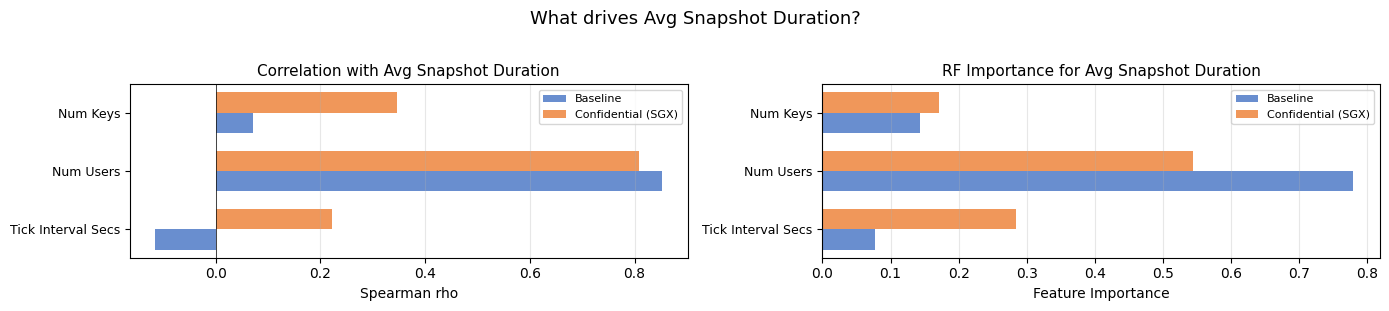

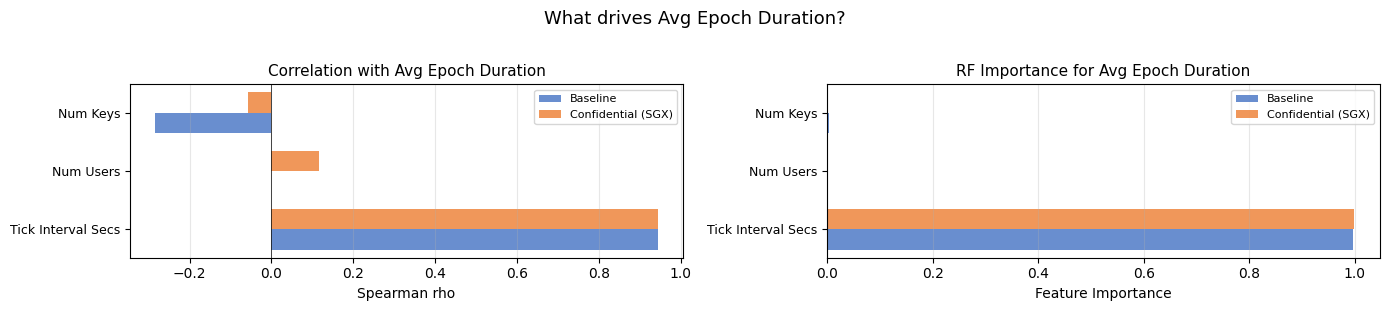

In [19]:
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestRegressor

_target_metrics = [
    ("avg_snapshot_duration_s", "Avg Snapshot Duration"),
    ("avg_epoch_duration_s", "Avg Epoch Duration"),
]
_feature_params = [c for c in _all_params if c in perf_df.columns and perf_df[c].nunique() > 1]
_topology_types = [("baseline", COLOR_BASELINE), ("enclave", COLOR_CONFIDENTIAL)]

for metric_col, metric_title in _target_metrics:
    if metric_col not in perf_df.columns or not _feature_params:
        print(f"Skipped {metric_title}: missing columns")
        continue

    fig, axes = plt.subplots(1, 2, figsize=(14, max(3, 0.6 * len(_feature_params))), squeeze=False)
    ax_corr, ax_imp = axes[0, 0], axes[0, 1]

    # --- Spearman correlation ---
    corr_data = {}
    for ttype, colour in _topology_types:
        sub = perf_df[perf_df["topology_type"] == ttype].dropna(subset=[metric_col])
        if len(sub) < 5:
            continue
        corrs = []
        for param in _feature_params:
            vals = sub[param].dropna()
            target = sub.loc[vals.index, metric_col]
            if len(vals) < 5 or vals.nunique() < 2:
                corrs.append(0.0)
            else:
                rho, _ = spearmanr(vals, target)
                corrs.append(rho)
        corr_data[ttype] = corrs

    y_pos = np.arange(len(_feature_params))
    bar_h = 0.35
    for i, (ttype, colour) in enumerate(_topology_types):
        if ttype not in corr_data:
            continue
        label = "Baseline" if ttype == "baseline" else "Confidential (SGX)"
        ax_corr.barh(y_pos + i * bar_h, corr_data[ttype], bar_h,
                     color=colour, alpha=0.8, label=label)

    ax_corr.set_yticks(y_pos + bar_h / 2)
    ax_corr.set_yticklabels([_param_label(p) for p in _feature_params], fontsize=9)
    ax_corr.set_xlabel("Spearman rho", fontsize=10)
    ax_corr.set_title(f"Correlation with {metric_title}", fontsize=11)
    ax_corr.axvline(0, color="black", linewidth=0.5)
    ax_corr.legend(fontsize=8)
    ax_corr.grid(True, axis="x", alpha=0.3)

    # --- Random Forest feature importance ---
    imp_data = {}
    for ttype, colour in _topology_types:
        sub = perf_df[perf_df["topology_type"] == ttype].dropna(subset=[metric_col])
        X = sub[_feature_params].copy()
        y = sub[metric_col]
        # Drop columns with no variance or all NaN
        X = X.dropna(axis=1, how="all")
        valid_cols = [c for c in X.columns if X[c].nunique() > 1]
        X = X[valid_cols].fillna(X[valid_cols].median())
        if len(X) < 5 or len(valid_cols) == 0:
            continue
        rf = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=5)
        rf.fit(X, y)
        # Map back to full param list (0 for params not in this subset)
        importances = []
        for p in _feature_params:
            if p in valid_cols:
                importances.append(rf.feature_importances_[valid_cols.index(p)])
            else:
                importances.append(0.0)
        imp_data[ttype] = importances

    for i, (ttype, colour) in enumerate(_topology_types):
        if ttype not in imp_data:
            continue
        label = "Baseline" if ttype == "baseline" else "Confidential (SGX)"
        ax_imp.barh(y_pos + i * bar_h, imp_data[ttype], bar_h,
                    color=colour, alpha=0.8, label=label)

    ax_imp.set_yticks(y_pos + bar_h / 2)
    ax_imp.set_yticklabels([_param_label(p) for p in _feature_params], fontsize=9)
    ax_imp.set_xlabel("Feature Importance", fontsize=10)
    ax_imp.set_title(f"RF Importance for {metric_title}", fontsize=11)
    ax_imp.legend(fontsize=8)
    ax_imp.grid(True, axis="x", alpha=0.3)

    fig.suptitle(f"What drives {metric_title}?", fontsize=13, y=1.02)
    fig.tight_layout()

    if SAVE_PLOTS:
        save_or_show(fig, OUTPUT_DIR, f"b2b-importance-{metric_col}", PLOT_FORMAT, show=True)
    else:
        plt.show()

NOTE: The average epoch duration is fixed - doesn't depend on the number of users or keys but only on the tick frequency. Hence, we expect to have near-zero correlation with num_users and num_keys, and strong correlation with tick_interval. 

When there is not enough data, it may show spurious correlations (for example, showing that the num_users is high correlated). Always interpret with caution!

### B3: Snapshot Duration vs max_time_steps

Algorithm 3 (prediction) cost grows with `max_time_steps` and dominates CPU time in SGX.
This dedicated plot shows the scaling curve for both baseline and confidential.

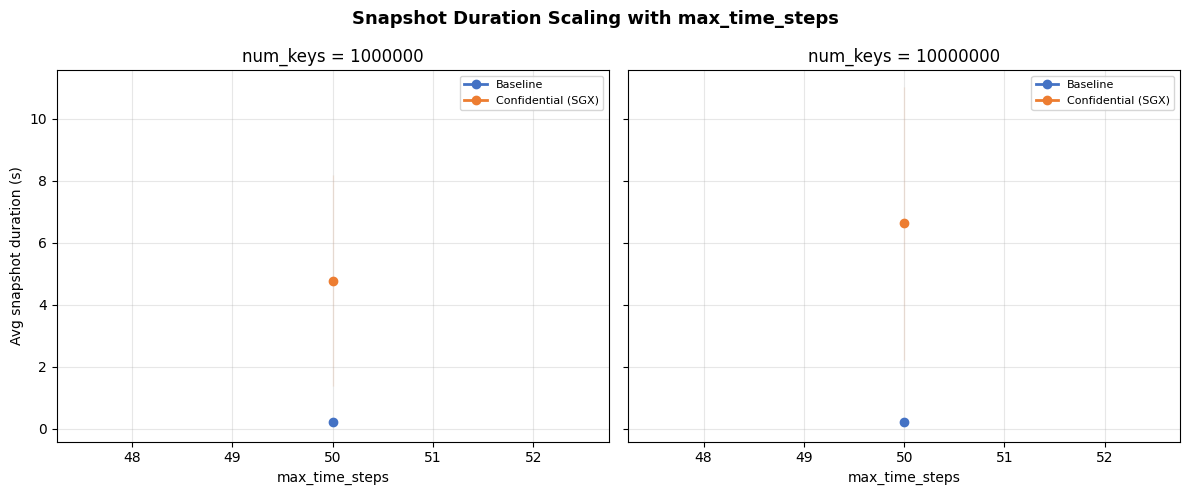

In [20]:
if "max_time_steps" in perf_df.columns and "avg_snapshot_duration_s" in perf_df.columns:
    # If num_keys varies, facet by it
    if "num_keys" in perf_vary_cols and perf_df["num_keys"].nunique() > 1:
        unique_keys = sorted(perf_df["num_keys"].unique())
        n_facets = len(unique_keys)
        fig, axes = plt.subplots(1, n_facets, figsize=(6 * n_facets, 5), sharey=True, squeeze=False)

        for fi, nk in enumerate(unique_keys):
            ax = axes[0, fi]
            sub = perf_df[perf_df["num_keys"] == nk]
            for ttype, colour, label in [("baseline", COLOR_BASELINE, "Baseline"),
                                          ("enclave", COLOR_CONFIDENTIAL, "Confidential (SGX)")]:
                tsub = sub[sub["topology_type"] == ttype] if "topology_type" in sub.columns else sub
                if tsub.empty:
                    continue
                grouped = tsub.groupby("max_time_steps")["avg_snapshot_duration_s"].agg(["mean", "std"]).sort_index()
                x = grouped.index.values
                y = grouped["mean"].values
                err = grouped["std"].fillna(0).values
                ax.plot(x, y, marker="o", color=colour, label=label, linewidth=2)
                ax.fill_between(x, y - err, y + err, color=colour, alpha=0.15)

            from helpers.visualization import _format_param_val
            ax.set_title(f"num_keys = {_format_param_val('num_keys', nk)}")
            ax.set_xlabel("max_time_steps")
            if fi == 0:
                ax.set_ylabel("Avg snapshot duration (s)")
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)

        fig.suptitle("Snapshot Duration Scaling with max_time_steps", fontsize=13, fontweight="bold")
        save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, "b3-snapshot-scaling", PLOT_FORMAT, True)
    else:
        sensitivity_line(
            perf_df, "max_time_steps", "avg_snapshot_duration_s",
            ylabel="Avg snapshot duration (s)",
            title="Snapshot Duration Scaling with max_time_steps",
            output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
            plot_name="b3-snapshot-scaling",
            fmt=PLOT_FORMAT,
        )
else:
    print("Skipped: max_time_steps or avg_snapshot_duration_s not available")

From the results above, is possible to notice that in every configuration, the confidential runs have much higher snapshot durations than the baseline -- still, this is expected due to SGX overhead.

However, in the confidential runs we can see that the snapshot duration decreases as `max_time_steps` increases. This is expected as, with higher `max_time_steps`, the algorithm 3 (prediction) cost becomes more dominant.

---
# Section C: Grid Search Overview & Run Health

Overview of all grid-search runs: completion status, duration distributions, and the full run catalog.

### C1: Run Completion Status

Heatmaps showing the completion rate across the parameter grid, separately for baseline and confidential.

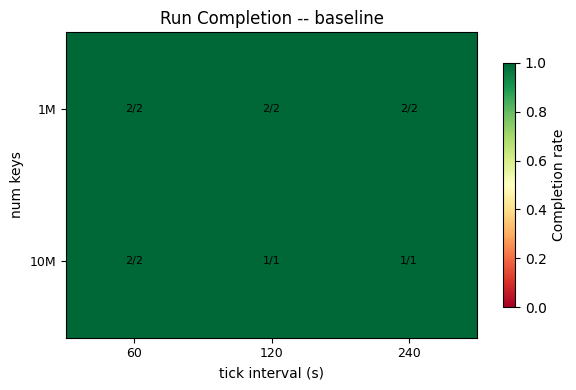

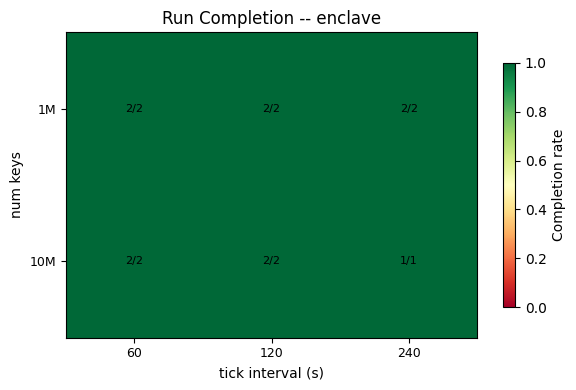

In [21]:
# Pick two parameters for the heatmap axes
heatmap_params = [c for c in ["tick_interval_secs", "parallelism", "num_keys", "num_users"]
                  if c in perf_vary_cols]

if len(heatmap_params) >= 2:
    x_p, y_p = heatmap_params[0], heatmap_params[1]
    for ttype in sorted(comparison_df["topology_type"].unique()):
        completion_heatmap(
            comparison_df, x_p, y_p,
            topology_type=ttype,
            title=f"Run Completion -- {ttype}",
            output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
            plot_name=f"c1-completion-{ttype}",
            fmt=PLOT_FORMAT,
        )
else:
    # Fallback: simple status count bar chart
    for ttype in sorted(comparison_df["topology_type"].unique()):
        sub = comparison_df[comparison_df["topology_type"] == ttype]
        counts = sub["status"].value_counts()
        fig, ax = plt.subplots(figsize=(6, 4))
        colors = {"Completed": "#27AE60", "Timed out": "#F39C12", "OOM": "#E74C3C"}
        ax.bar(counts.index, counts.values, color=[colors.get(s, "grey") for s in counts.index])
        ax.set_ylabel("Number of runs")
        ax.set_title(f"Run Status -- {ttype}")
        save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, f"c1-status-{ttype}", PLOT_FORMAT, True)

We can confirm that the vast majority of runs completed successfully. Especially, when the tick interval is higher ($\ge 30s$).

### C2: Traffic pattern validation across runs

This plot allows to understand which parameters affect the traffic pattern (e.g., number of tuples emitted per epoch) and whether the observed patterns align with expectations. For example, we expect that increasing `num_users` or `num_keys` should increase the number of tuples emitted, while `tick_interval` may have a more complex relationship.

In [22]:
# minimum epochs completed to be included in traffic compliance analysis
# why? inital epochs show great variability and don't reflect steady-state behavior. This would skew the analysis.
MIN_EPOCHS = 0 
traffic_df = None

if "traffic_compliance_rate" not in perf_df.columns or perf_df["traffic_compliance_rate"].isna().all():
    print("Skipped: no traffic compliance data (no DP lifecycle events)")
else:
    traffic_df = perf_df.dropna(subset=["traffic_compliance_rate"])

    # filter dataframe to only include runs that completed at least MIN_EPOCHS epochs, to focus on steady-state behavior
    if "max_epoch_completed" in traffic_df.columns:
        traffic_df = traffic_df[traffic_df["max_epoch_completed"] >= MIN_EPOCHS]
        print(f"Filtered to {len(traffic_df)} runs with at least {MIN_EPOCHS} epochs completed for traffic compliance analysis")
    else:
        print(f"Warning: max_epoch_completed column not found, cannot filter by minimum epochs")

Filtered to 21 runs with at least 0 epochs completed for traffic compliance analysis


In [23]:
# Enrich traffic_df with throughput columns (needed for D1f relation analysis)
if traffic_df is not None and not traffic_df.empty:
    _fwd = next((c for c in traffic_df.columns if c.startswith("counter_") and "forwarded" in c),
                next((c for c in traffic_df.columns if c.startswith("counter_") and "real_emissions" in c), None))
    if _fwd and "active_duration_s" in traffic_df.columns:
        traffic_df["throughput_tuples_per_s"] = traffic_df[_fwd] / traffic_df["active_duration_s"]
        traffic_df["tuples_per_epoch"] = traffic_df[_fwd] / traffic_df["max_epoch_completed"].clip(lower=1)
        print(f"Added throughput columns using '{_fwd}' as forwarded counter")
    else:
        print(f"Warning: could not add throughput columns (_fwd={_fwd})")

Added throughput columns using 'counter_user_contribution_bounding_forwarded' as forwarded counter


#### C2a: Per-run compliance strip chart
Strip chart showing the traffic compliance rate for each run. This allows to immediately identify parameters that lead to poor traffic compliance

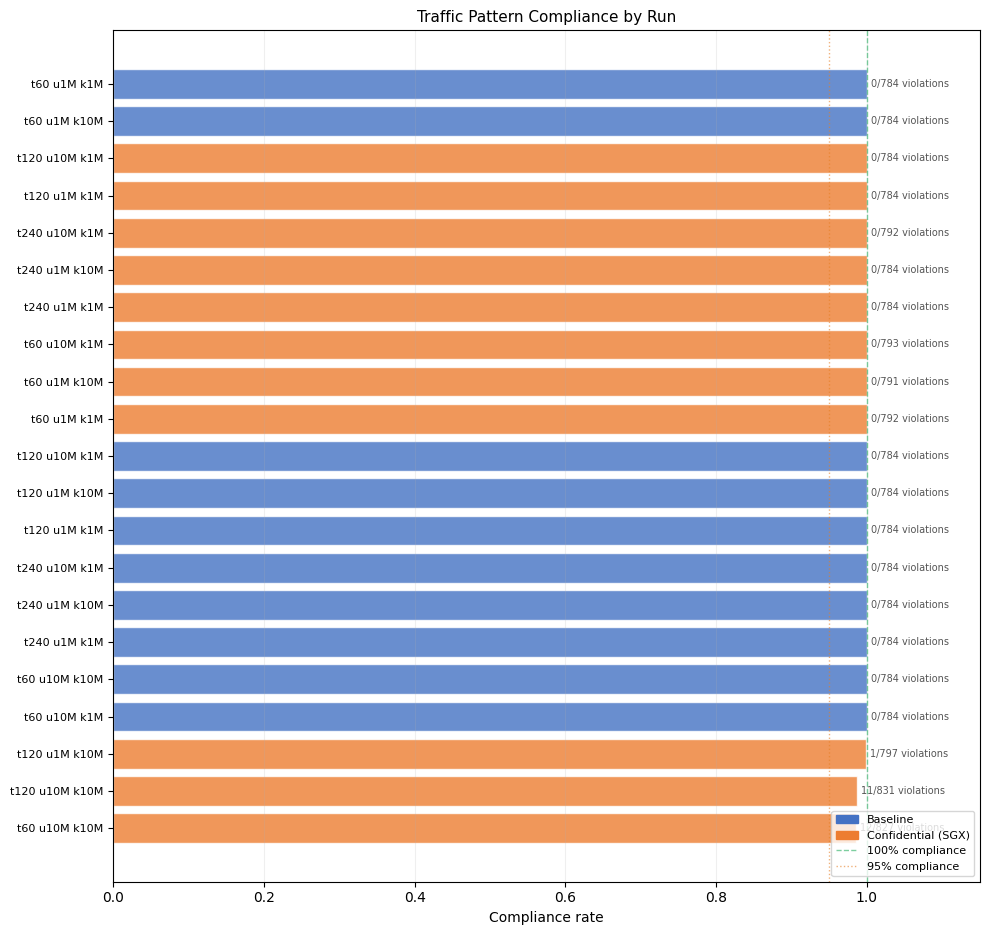

In [24]:
if traffic_df is not None and not traffic_df.empty:
    # Plot 1: Per-run compliance strip chart
    traffic_compliance_strip(
        traffic_df,
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        fmt=PLOT_FORMAT,
    )
else:
    print("Skipped: no traffic compliance data (no DP lifecycle events)")

From the results above, I see that (at least in the confidential runs) the traffic compliance rate is generally higher with a smaller workload (lower num_users and num_keys).

#### C2b: Traffic compliance vs parameters
These plots show how the traffic compliance rate varies with different parameters, helping to understand how workload characteristics influence the ability of the topology to maintain the expected traffic pattern.

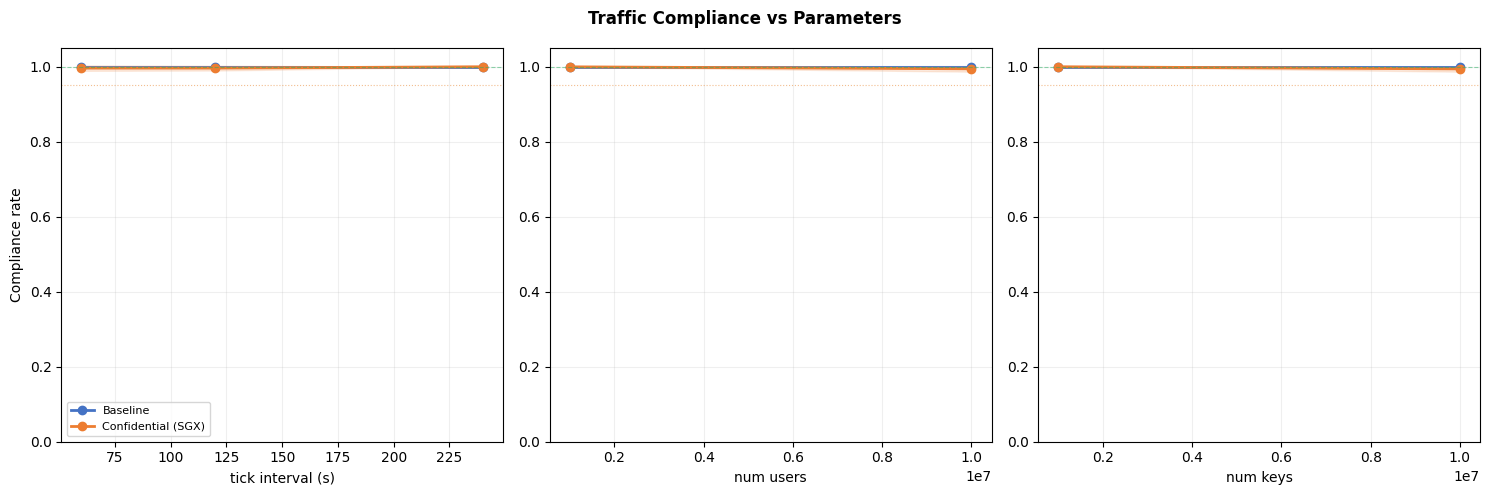

In [25]:
if traffic_df is not None and not traffic_df.empty:
    vary_cols = detect_varying_params(traffic_df)

    # Plot 2: Compliance sensitivity to each varying parameter
    if vary_cols:
        traffic_compliance_sensitivity(
            traffic_df,
            vary_cols,
            output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
            fmt=PLOT_FORMAT,
        )
    else:
        print("No varying parameters to analyze for traffic compliance sensitivity")
else:
    print("Skipped: no traffic compliance data (no DP lifecycle events)")


The plots above show that the traffic compliance rate is generally higher with a smaller workload (lower `num_users` and `num_keys`), and that it tends to decrease as the tick interval increases. 

This suggests that the topology struggles to process tuples in a timely manner as the workload increases, leading to more irregular tick processing since the queues grow larger and the system had to process more tuples per epoch.

This may be probably due to Apache Storm's backpressure mechanism, which slows down the processing of tuples when the system is overwhelmed, leading to irregular tick processing and thus traffic violations.

#### C2c: Violation characteristics scatter plot

This scatter plot shows the relationship between the mean and variability of the timing deltas for emitted tuples, normalized by the expected tick interval. Each point represents a run, with its size proportional to the total number of emissions. 

This visualization helps to identify whether runs with higher traffic compliance (lower mean and std delta) also tend to have more emissions, and whether there are clusters of runs that deviate from the expected timing pattern.

> NOTE: labeled points are outliers - specifically points where:
>   - `traffic_compliance_rate` < 0.95 OR
>   - `norm_std` is above the 85th percentile
> 
> Points that behave well (close to the expected mean with low std) are intentionally left unlabeled to avoid cluttering the plot.

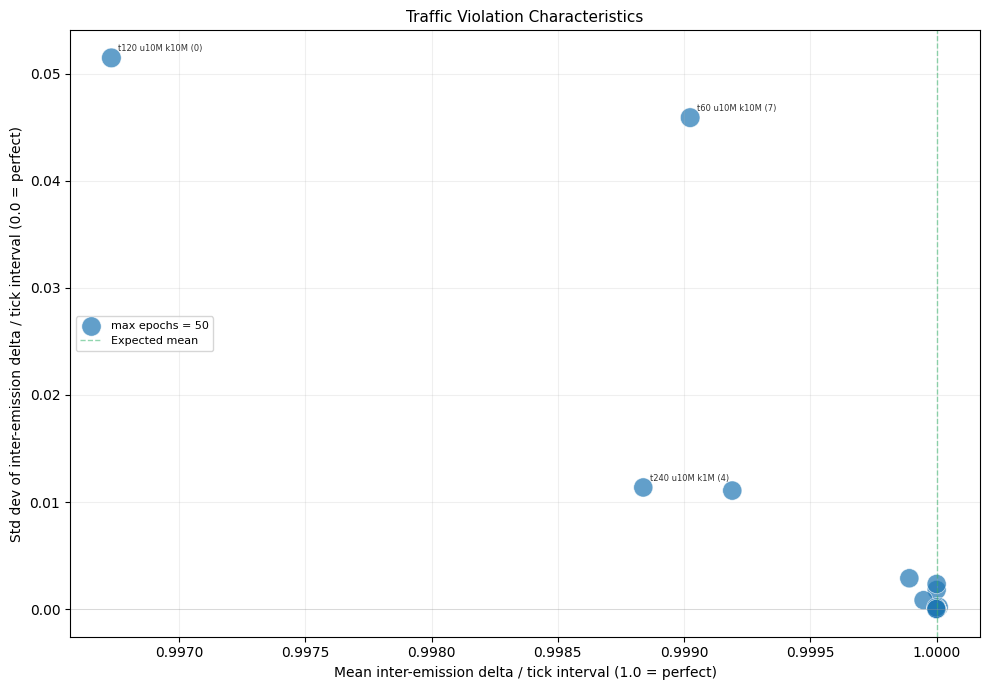

In [26]:
if traffic_df is not None and not traffic_df.empty:
    # Plot 3: Violation characteristic scatter
    traffic_violation_scatter(
        traffic_df,
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        fmt=PLOT_FORMAT,
    )
else:
    print("Skipped: no traffic compliance data (no DP lifecycle events)")

From the results above, it's possible to notice that **_there is not a single parameter that clearly correlates with the traffic compliance rate_**, which suggests that the observed traffic violations may be more related to the underlying system conditions rather than the workload configurations.

For example, runs with much higher workload (e.g., higher num_users or num_keys) do not necessarily have worse traffic compliance, and some runs with low workload also show significant violations.

However, the general trend is that longer runs (higher MAX_TIME_STEPS) tend to have a better traffic compliance rate, which may be because they have more time to stabilize and adapt to the workload, while shorter runs may be more susceptible to transient issues that cause timing violations.

#### C2d: Tick tuple irregularity analysis across runs

The following plots analyze the tick tuple irregularity across runs by showing the distribution of the normalized timing deltas (mean and std) for emitted tuples, grouped by different parameters.

The traffic violations came from irregularities in the timing of received tick tuples, which caused the topology to emit tuples at unexpected times. 

By analyzing the distribution of these timing deltas, we can understand how different parameters affect the regularity of tick processing and identify potential causes of traffic violations.

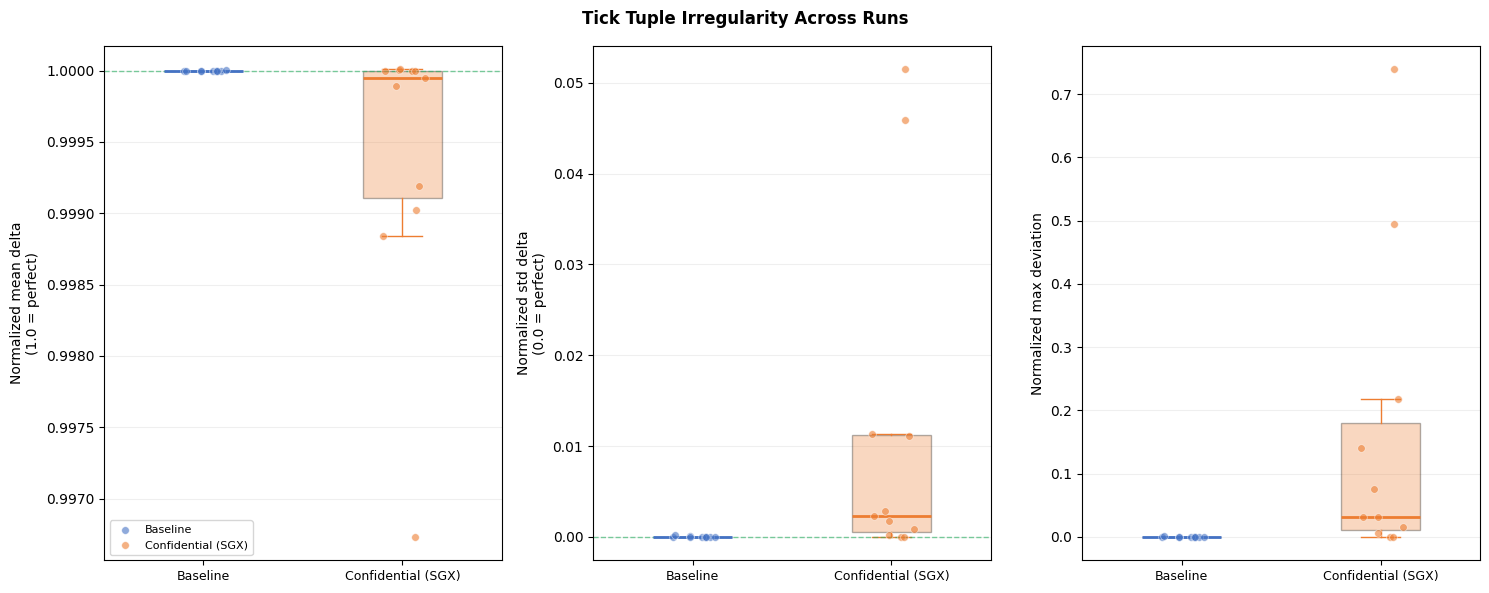

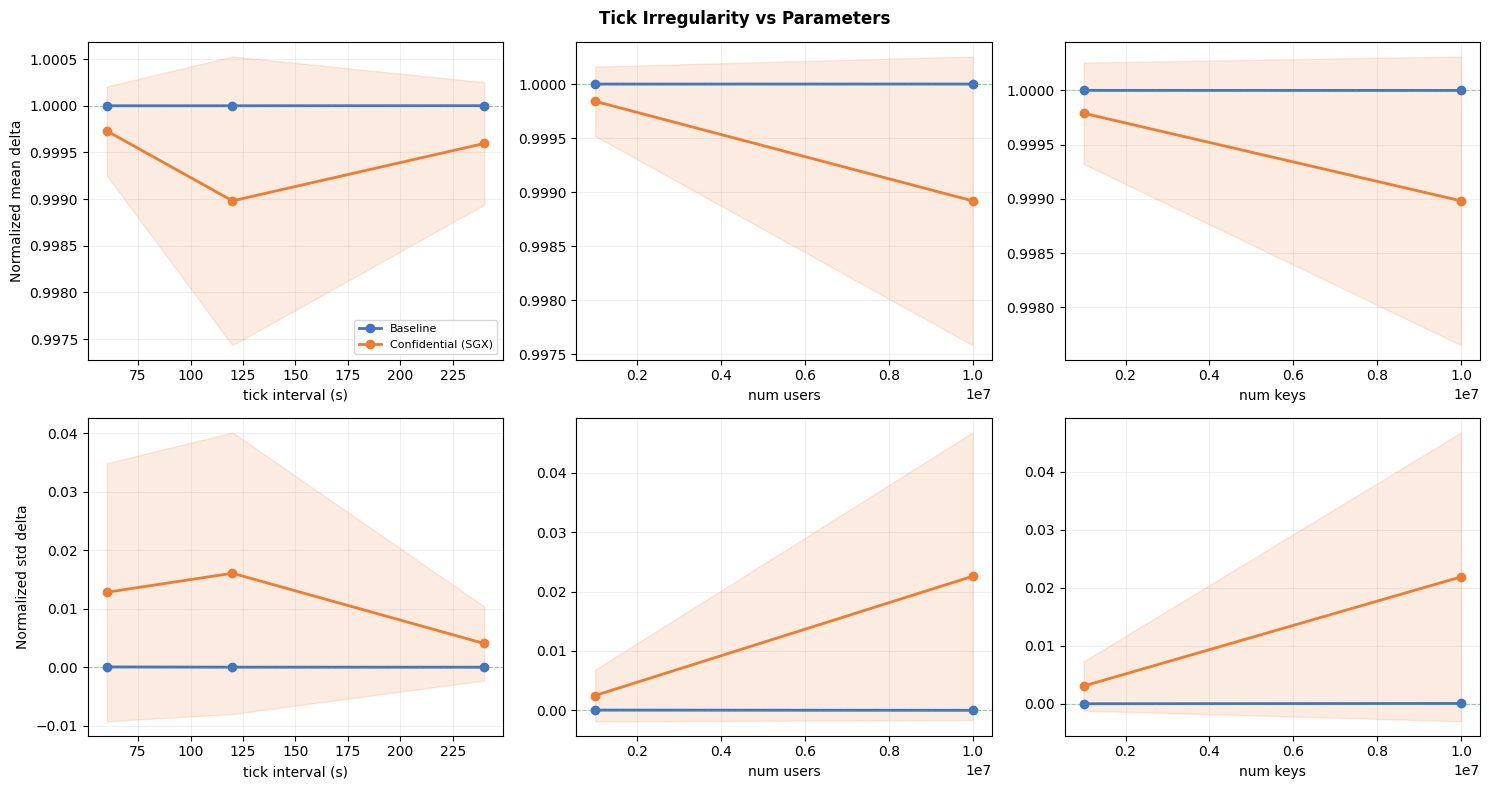

In [27]:
if traffic_df is not None and not traffic_df.empty:
    tick_irregularity_overview(
        traffic_df,
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        fmt=PLOT_FORMAT,
        annotate_outliers=False
    )
    vary_cols = detect_varying_params(traffic_df)
    if vary_cols:
        tick_irregularity_sensitivity(
            traffic_df,
            vary_cols,
            output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
            fmt=PLOT_FORMAT,
        )
else:
    print("Skipped D1e: no traffic compliance data")

The plots above confirm what we already observed: higher workload (higher `num_users` and `num_keys`) tends to lead to higher variability in the timing of emitted tuples, which can contribute to traffic violations.

#### C2e: Relation between traffic compliance / tick tuple irregularity and performance metrics

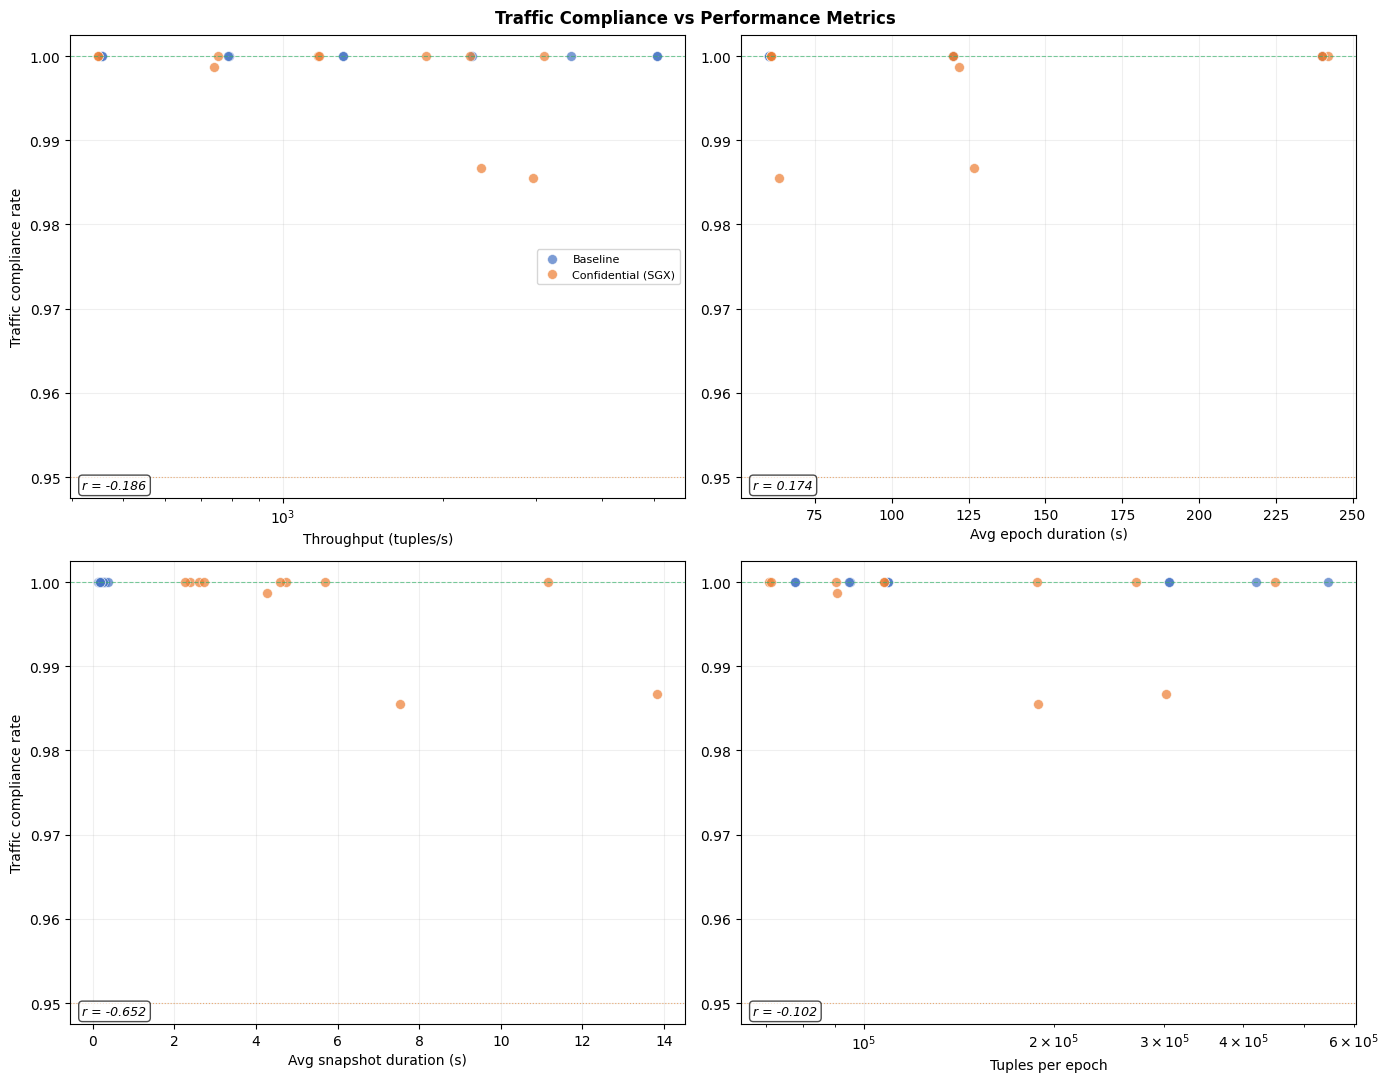

In [28]:
if traffic_df is not None and not traffic_df.empty:
    compliance_vs_performance_scatter(
        traffic_df,
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        fmt=PLOT_FORMAT,
        annotate_outliers=False
    )
else:
    print("Skipped D1f compliance scatter: no traffic compliance data")

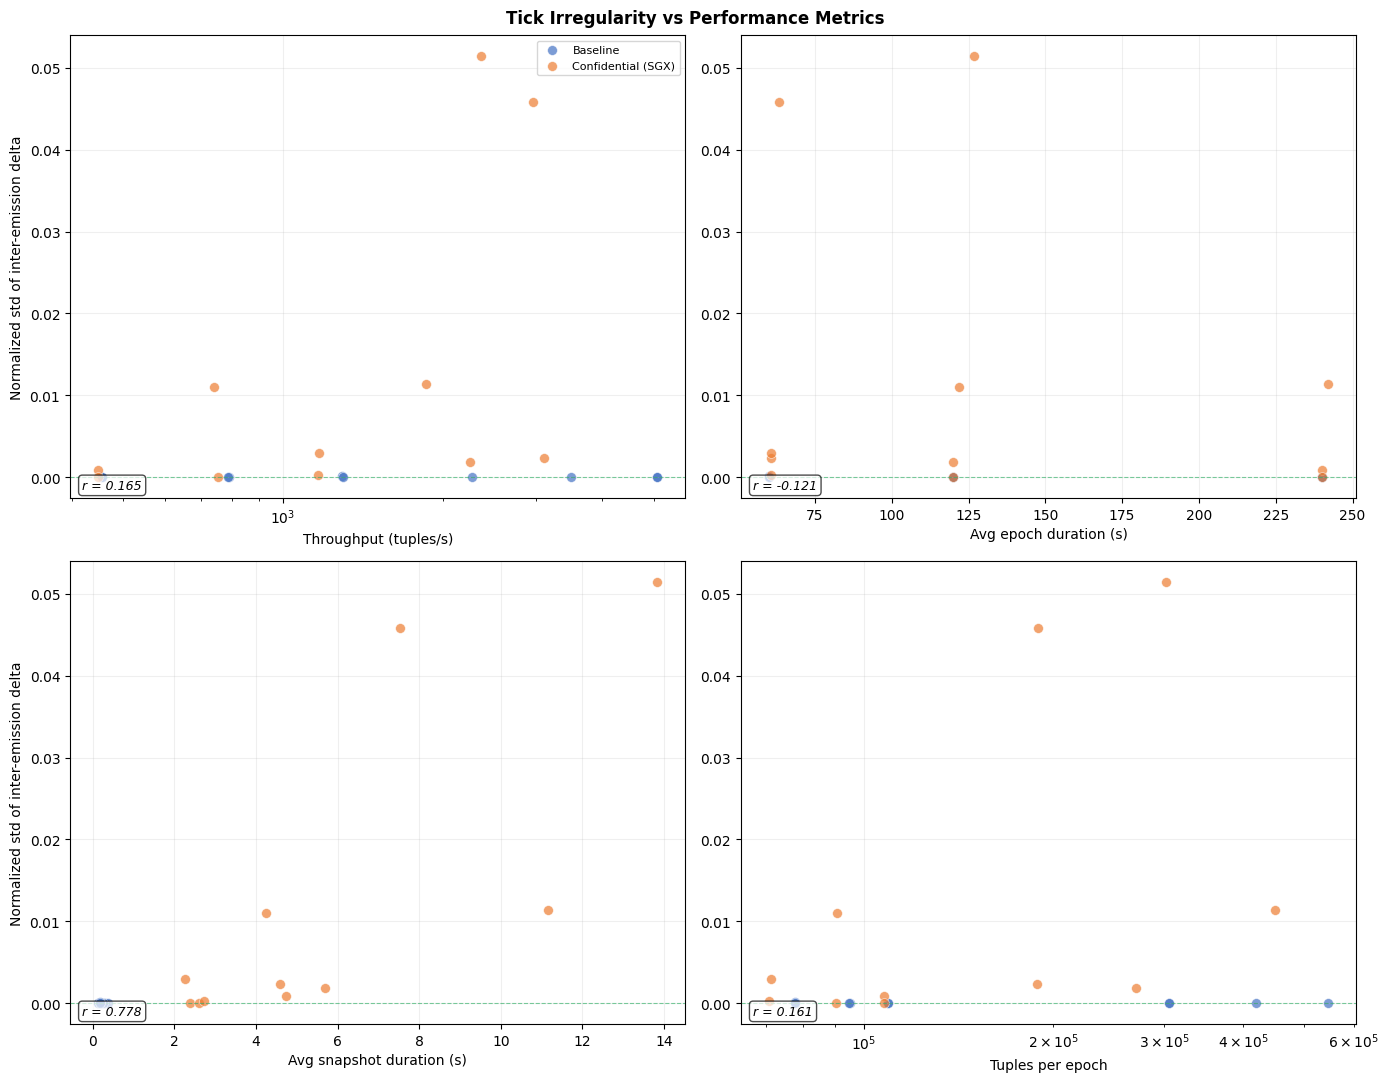

In [29]:
if traffic_df is not None and not traffic_df.empty:
    irregularity_vs_performance_scatter(
        traffic_df,
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        fmt=PLOT_FORMAT,
    )
else:
    print("Skipped D1f irregularity scatter: no traffic compliance data")

#### C2d: Summary table
Shows the key metrics for each run, sorted by traffic compliance rate, to allow a quick overview of which runs performed well or poorly in terms of maintaining the expected traffic pattern.

In [30]:
# Summary table
if traffic_df is not None and not traffic_df.empty:
    summary_cols = ["label", "topology_type", "tick_interval_secs",
                    "traffic_compliance_rate", "traffic_violations",
                    "traffic_total_emissions", "traffic_mean_delta_s",
                    "traffic_std_delta_s"]
    avail = [c for c in summary_cols if c in traffic_df.columns]
    display(traffic_df[avail].sort_values("traffic_compliance_rate"))
else:
    print("Skipped: no traffic compliance data (no DP lifecycle events)")

,label,topology_type,tick_interval_secs,traffic_compliance_rate,traffic_violations,traffic_total_emissions,traffic_mean_delta_s,traffic_std_delta_s
7,t60 u10M k10M,enclave,60,0.985490,12,827,59.941461,2.753004
0,t120 u10M k10M,enclave,120,0.986763,11,831,119.607861,6.175177
2,t120 u1M k10M,enclave,120,0.998745,1,797,119.902930,1.328749
18,t60 u10M k1M,baseline,60,1.000000,0,784,60.000001,0.002062
17,t60 u10M k10M,baseline,60,1.000000,0,784,60.000023,0.001440
16,t240 u1M k1M,baseline,240,1.000000,0,784,240.000257,0.005006
15,t240 u1M k10M,baseline,240,1.000000,0,784,239.999913,0.006715
14,t240 u10M k1M,baseline,240,1.000000,0,784,239.999989,0.001367
13,t120 u1M k1M,baseline,120,1.000000,0,784,119.999979,0.001167
12,t120 u1M k10M,baseline,120,1.000000,0,784,119.999948,0.007546


### C2: Run Catalog

Full run catalog showing parameters, key metrics, and completion status for each run.

In [31]:
catalog_display_cols = ["label", "topology_type", "status", "grid_timestamp",
                        "tick_interval_secs", "max_time_steps", "parallelism",
                        "mu", "num_users", "num_keys", "duration_secs",
                        "startup_elapsed_secs"]
catalog_display_cols = [c for c in catalog_display_cols if c in catalog.columns]

styled_summary_table(catalog, columns=catalog_display_cols)

,label,topology_type,status,grid_timestamp,tick_interval_secs,max_time_steps,parallelism,mu,num_users,num_keys,duration_secs,startup_elapsed_secs
0,t120 u10M k10M,enclave,Completed,20260605_202538,120,50,16,0,10000000,10000000,6740,300
1,t120 u10M k1M,enclave,Completed,20260605_202538,120,50,16,0,10000000,1000000,6260,210
2,t120 u1M k10M,enclave,Completed,20260605_202538,120,50,16,0,1000000,10000000,6428,270
3,t120 u1M k1M,enclave,Completed,20260605_202538,120,50,16,0,1000000,1000000,6256,220
4,t240 u10M k10M,enclave,OOM,20260605_202538,240,50,16,0,10000000,10000000,26079,300
5,t240 u10M k1M,enclave,Completed,20260605_202538,240,50,16,0,10000000,1000000,12419,290
6,t240 u1M k10M,enclave,Completed,20260605_202538,240,50,16,0,1000000,10000000,12257,290
7,t240 u1M k1M,enclave,Completed,20260605_202538,240,50,16,0,1000000,1000000,12282,230
8,t60 u10M k10M,enclave,Completed,20260605_202538,60,50,16,0,10000000,10000000,3465,290
9,t60 u10M k1M,enclave,Completed,20260605_202538,60,50,16,0,10000000,1000000,3348,260


### C3: Duration Distribution by Status

Violin + strip plot showing how run durations distribute across status categories.
Reveals whether OOM occurs during startup or during active processing.

NOTE: if no OOM are detected (which may happen with small datasets) the "OOM" category will be empty, and the plot will only show "Completed" runs.  In this case, this plot is not very informative and can be skipped.

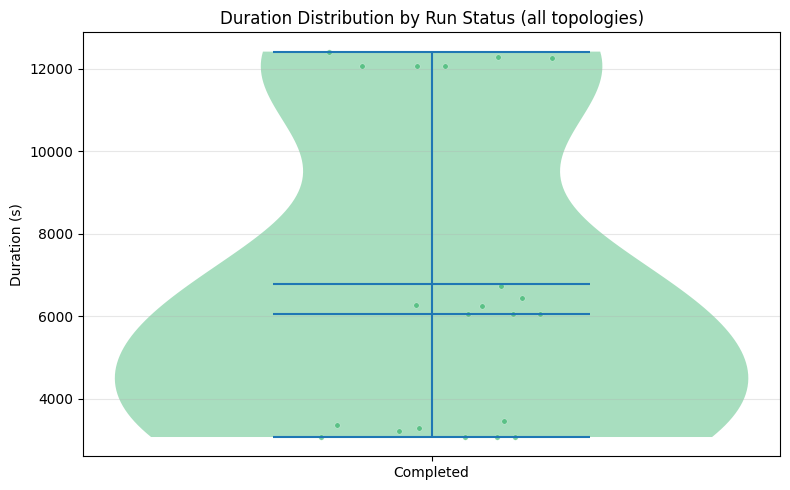

In [32]:
if "status" in comparison_df.columns and comparison_df["status"].nunique() > 0:
    status_distribution_plot(
        comparison_df,
        title="Duration Distribution by Run Status (all topologies)",
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        plot_name="c3-status-distribution",
        fmt=PLOT_FORMAT,
    )

### C4: Performance Summary Table

Key metrics across all configurations at a glance.

In [33]:
summary_cols = ["label", "topology_type", "status", "duration_secs", "startup_elapsed_secs",
                "avg_epoch_duration_s", "avg_snapshot_duration_s", "active_duration_s",
                "total_snapshot_time_s", "max_epoch_completed"]
summary_cols = [c for c in summary_cols if c in comparison_df.columns]

styled_summary_table(comparison_df, columns=summary_cols)

,label,topology_type,status,duration_secs,startup_elapsed_secs,avg_epoch_duration_s,avg_snapshot_duration_s,active_duration_s,total_snapshot_time_s,max_epoch_completed
0,t120 u10M k10M,enclave,Completed,6740,300,126.74x,13.84x,6389.03x,11070,50
1,t120 u10M k1M,enclave,Completed,6260,210,120.00x,5.69x,5999.59x,4555,50
2,t120 u1M k10M,enclave,Completed,6428,270,121.87x,4.26x,6119.69x,3406,50
3,t120 u1M k1M,enclave,Completed,6256,220,120.00x,2.39x,5999.53x,1913,50
4,t240 u10M k1M,enclave,Completed,12419,290,242.12x,11.15x,12105.97x,8921,50
5,t240 u1M k10M,enclave,Completed,12257,290,239.99x,4.74x,11999.91x,3795,50
6,t240 u1M k1M,enclave,Completed,12282,230,240.00x,2.59x,11999.94x,2075,50
7,t60 u10M k10M,enclave,Completed,3465,290,63.18x,7.53x,3195.46x,6021,50
8,t60 u10M k1M,enclave,Completed,3348,260,60.69x,4.58x,3034.99x,3667,50
9,t60 u1M k10M,enclave,Completed,3283,210,60.54x,2.72x,3030.36x,2174,50


---
# Section D: Single Run Deep-Dive

Set `SINGLE_RUN_IDX` in the configuration cell to a catalog row index to enable detailed profiler analysis for a specific run.

In [34]:
# SINGLE_RUN_IDX = 141
# SINGLE_RUN_IDX = 132
SINGLE_RUN_IDX = 21

In [35]:
from IPython.display import display
if SINGLE_RUN_IDX is None:
    print("Section D disabled. Set SINGLE_RUN_IDX to a catalog row index to enable.")
    print(f"Available indices: 0 to {len(catalog) - 1}")
    print("\nRun catalog (showing first 20):")
    display_cols = ["label", "topology_type", "status", "duration_secs"]
    display_cols = [c for c in display_cols if c in catalog.columns]
    
    # list 20 for enclave and 20 for baseline, to increase chances of showing a variety of runs
    display(styled_summary_table(catalog[catalog["topology_type"] == "enclave"].head(20), columns=display_cols))
    display(styled_summary_table(catalog[catalog["topology_type"] == "baseline"].head(20), columns=display_cols))
else:
    if SINGLE_RUN_IDX < 0 or SINGLE_RUN_IDX >= len(catalog):
        raise IndexError(f"SINGLE_RUN_IDX={SINGLE_RUN_IDX} out of range [0, {len(catalog) - 1}]")

    run_info = catalog.iloc[SINGLE_RUN_IDX]
    METRICS_CSV_DIR = run_info["profiler_dir"]
    print(f"Loading single-run data for: {run_info['label']} ({run_info.get('topology_type', '?')})")
    print(f"  Source: {METRICS_CSV_DIR}")

    run_display_cols = ["label", "topology_type", "status", "duration_secs", "startup_elapsed_secs"]
    run_display_cols = [c for c in run_display_cols if c in catalog.columns]
    display(styled_summary_table(catalog.iloc[[SINGLE_RUN_IDX]], columns=run_display_cols))

    df = load_profiler_csvs(METRICS_CSV_DIR)
    if df is None:
        raise ValueError(f"No profiler data found at {METRICS_CSV_DIR}")

    print(f"  Loaded {len(df)} rows from {df['source_file'].nunique()} file(s)")
    print(f"  Components: {', '.join(_get_components(df))}")
    print(f"  Time span: {df['elapsed_s'].max():.1f}s ({df['elapsed_s'].max()/60:.1f} minutes)")


Loading single-run data for: t60 u1M k10M (baseline)
  Source: ../examples/synthetic-benchmark-baseline/data/runs/scaling-sweep/20260607_120003/n=2/tick60_epochs50_p16_mu0_u1000000_k10000000_run4/profiler


,label,topology_type,status,duration_secs,startup_elapsed_secs
21,t60 u1M k10M,baseline,Completed,3066,20


  Loaded 4704 rows from 34 file(s)
  Components: bolt-data-perturbation, bolt-histogram-aggregation, bolt-user-contribution-bounding, spout
  Time span: 3023.9s (50.4 minutes)


### D1: Topology behavior analysis

The following subsections provide the tools to analyze and validate the expected lifecycle of the topology. This is useful for debugging and understanding the behavior of individual runs, especially those with anomalies.

The following plots allow to have a general understanding of the event timeline, the emission patterns, and the relationship between Apache Storm's timing and the observed traffic patterns.

#### D1a: Task behavior timeline

Timeline showing each task's phases: startup, active processing, snapshot computation, and shutdown.

It's useful to have a general understanding of the timeline structure and the pace of events, as well as the relative duration of each phase. This was primarly used for debugging and understanding the behavior of individual runs, especially those with anomalies.

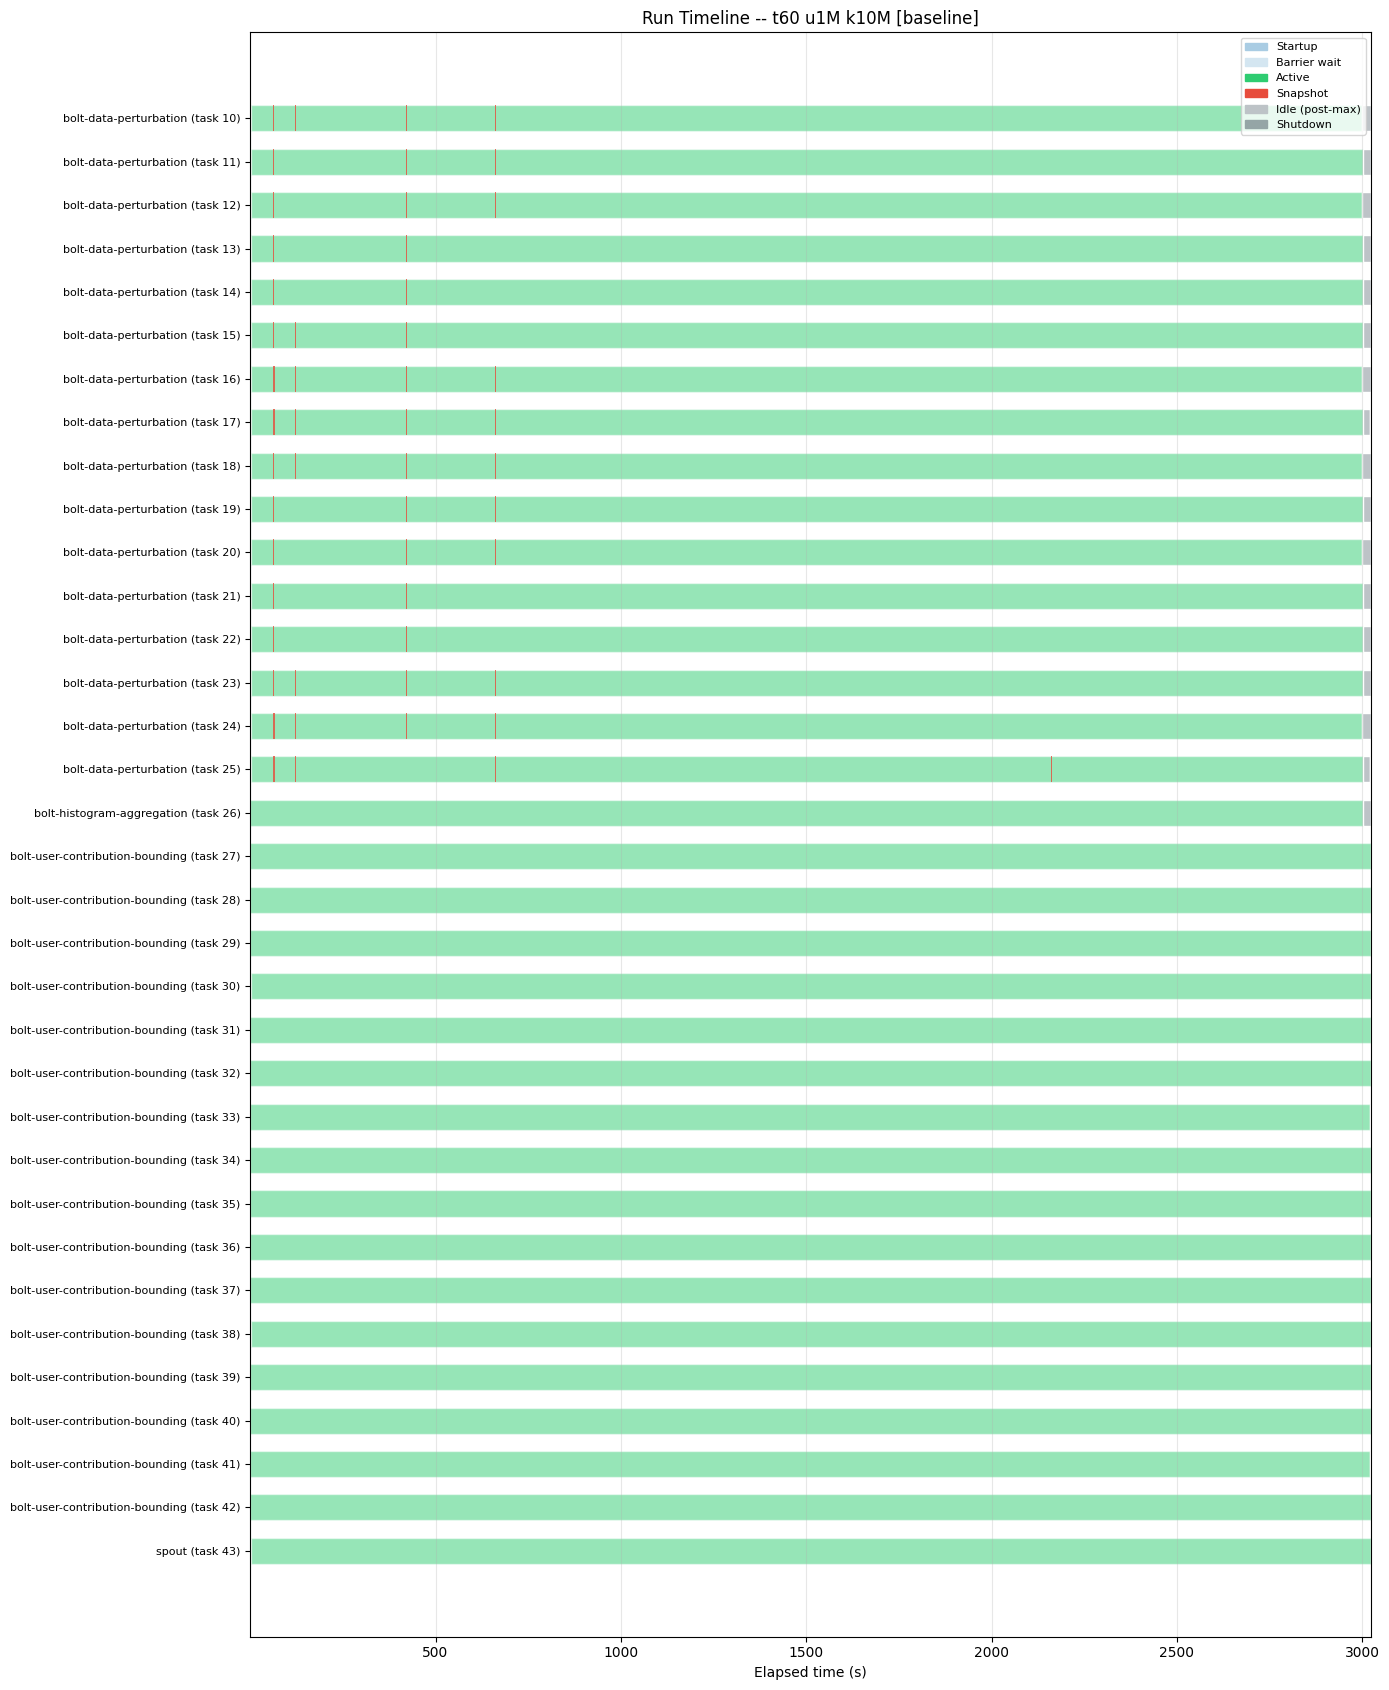

In [36]:
if SINGLE_RUN_IDX is not None:
    lifecycle = get_lifecycle_events(df)
    run_timeline_gantt(
        df, lifecycle,
        title=f"Run Timeline -- {run_info['label']} [{run_info['topology_type']}]",
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        plot_name="d1-timeline",
        fmt=PLOT_FORMAT,
    )

Here we expect to see verically aligned snapshot computation phases across all `DataPerturbationBolt` tasks, which indicates that the snapshots are synchronized and that the synchronization mechanism (Zookeeper) is working correctly. 

If we see misaligned snapshots, it may indicate synchronization issues or that some tasks are lagging behind.

#### D1b: Emission Timeline - Partials vs Dummies

This plots shows the counter of total real partial histograms (green) and dummy partial histograms (red) emitted over time. Useful to understand when the topology is emitting real data vs dummy data, and how this relates to the expected tick intervals.

If we see more dummy emissions than real emissions, it may indicate that the topology is struggling to keep up with the expected tick intervals, which could be a sign of performance issues or bottlenecks.

> NOTE: Dotted vertical lines mark ideal tick intervals while solid grey lines mark the actual epoch advances. A bit messy but gets the job done

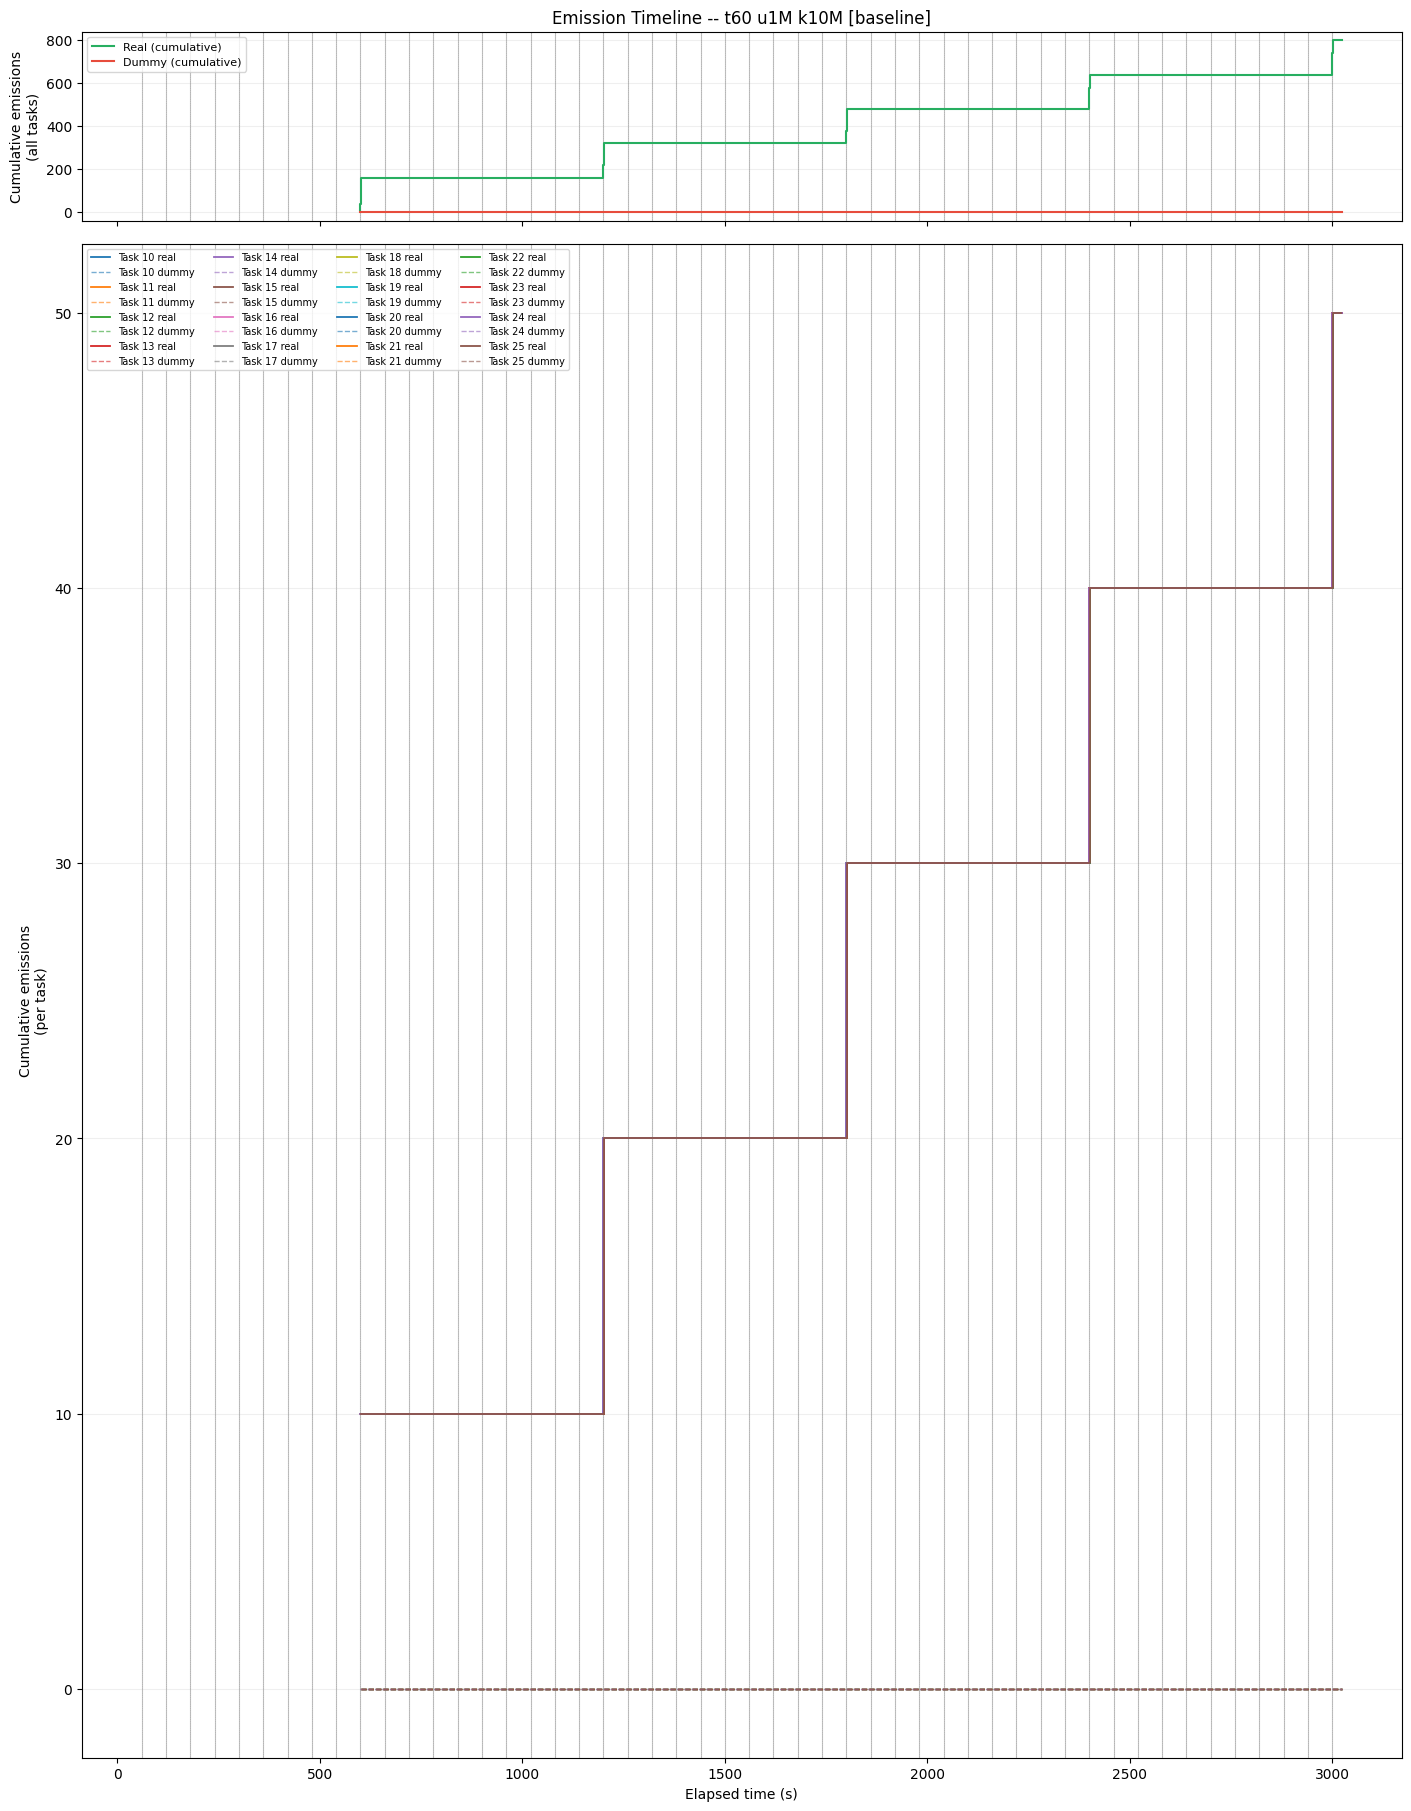

In [37]:
if SINGLE_RUN_IDX is not None:
    lifecycle = get_lifecycle_events(df)
    emission_timeline(
        df, lifecycle,
        title=f"Emission Timeline -- {run_info['label']} [{run_info['topology_type']}]",
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        plot_name="d1b-emission-timeline",
        fmt=PLOT_FORMAT,
    )

#### D1c: `DataPerturbationBolts` Emission Timeline

Per-task swim-lane timeline showing the emission of real partial histograms (green) and dummy partial histograms (red) from the data-perturbation bolts, overlaid with key lifecycle events to understand better the traffic patterns and synchronization between real and dummy emissions.

This is done using the following lifecycle events:

- **TICK_RECEIVED** (grey triangles)
- **EPOCH_ADVANCED** (green diamonds)
- **DUMMY_RELEASED** (orange circles)
- and snapshot computation blocks (red bars, using **SNAPSHOT_STARTED** and **SNAPSHOT_COMPLETED** events). 

The gray vertical dotted lines represent the ideal tick intervals. This allows to visually assess whether the emissions are aligned with the expected tick intervals and whether there are delays in epoch advancement.

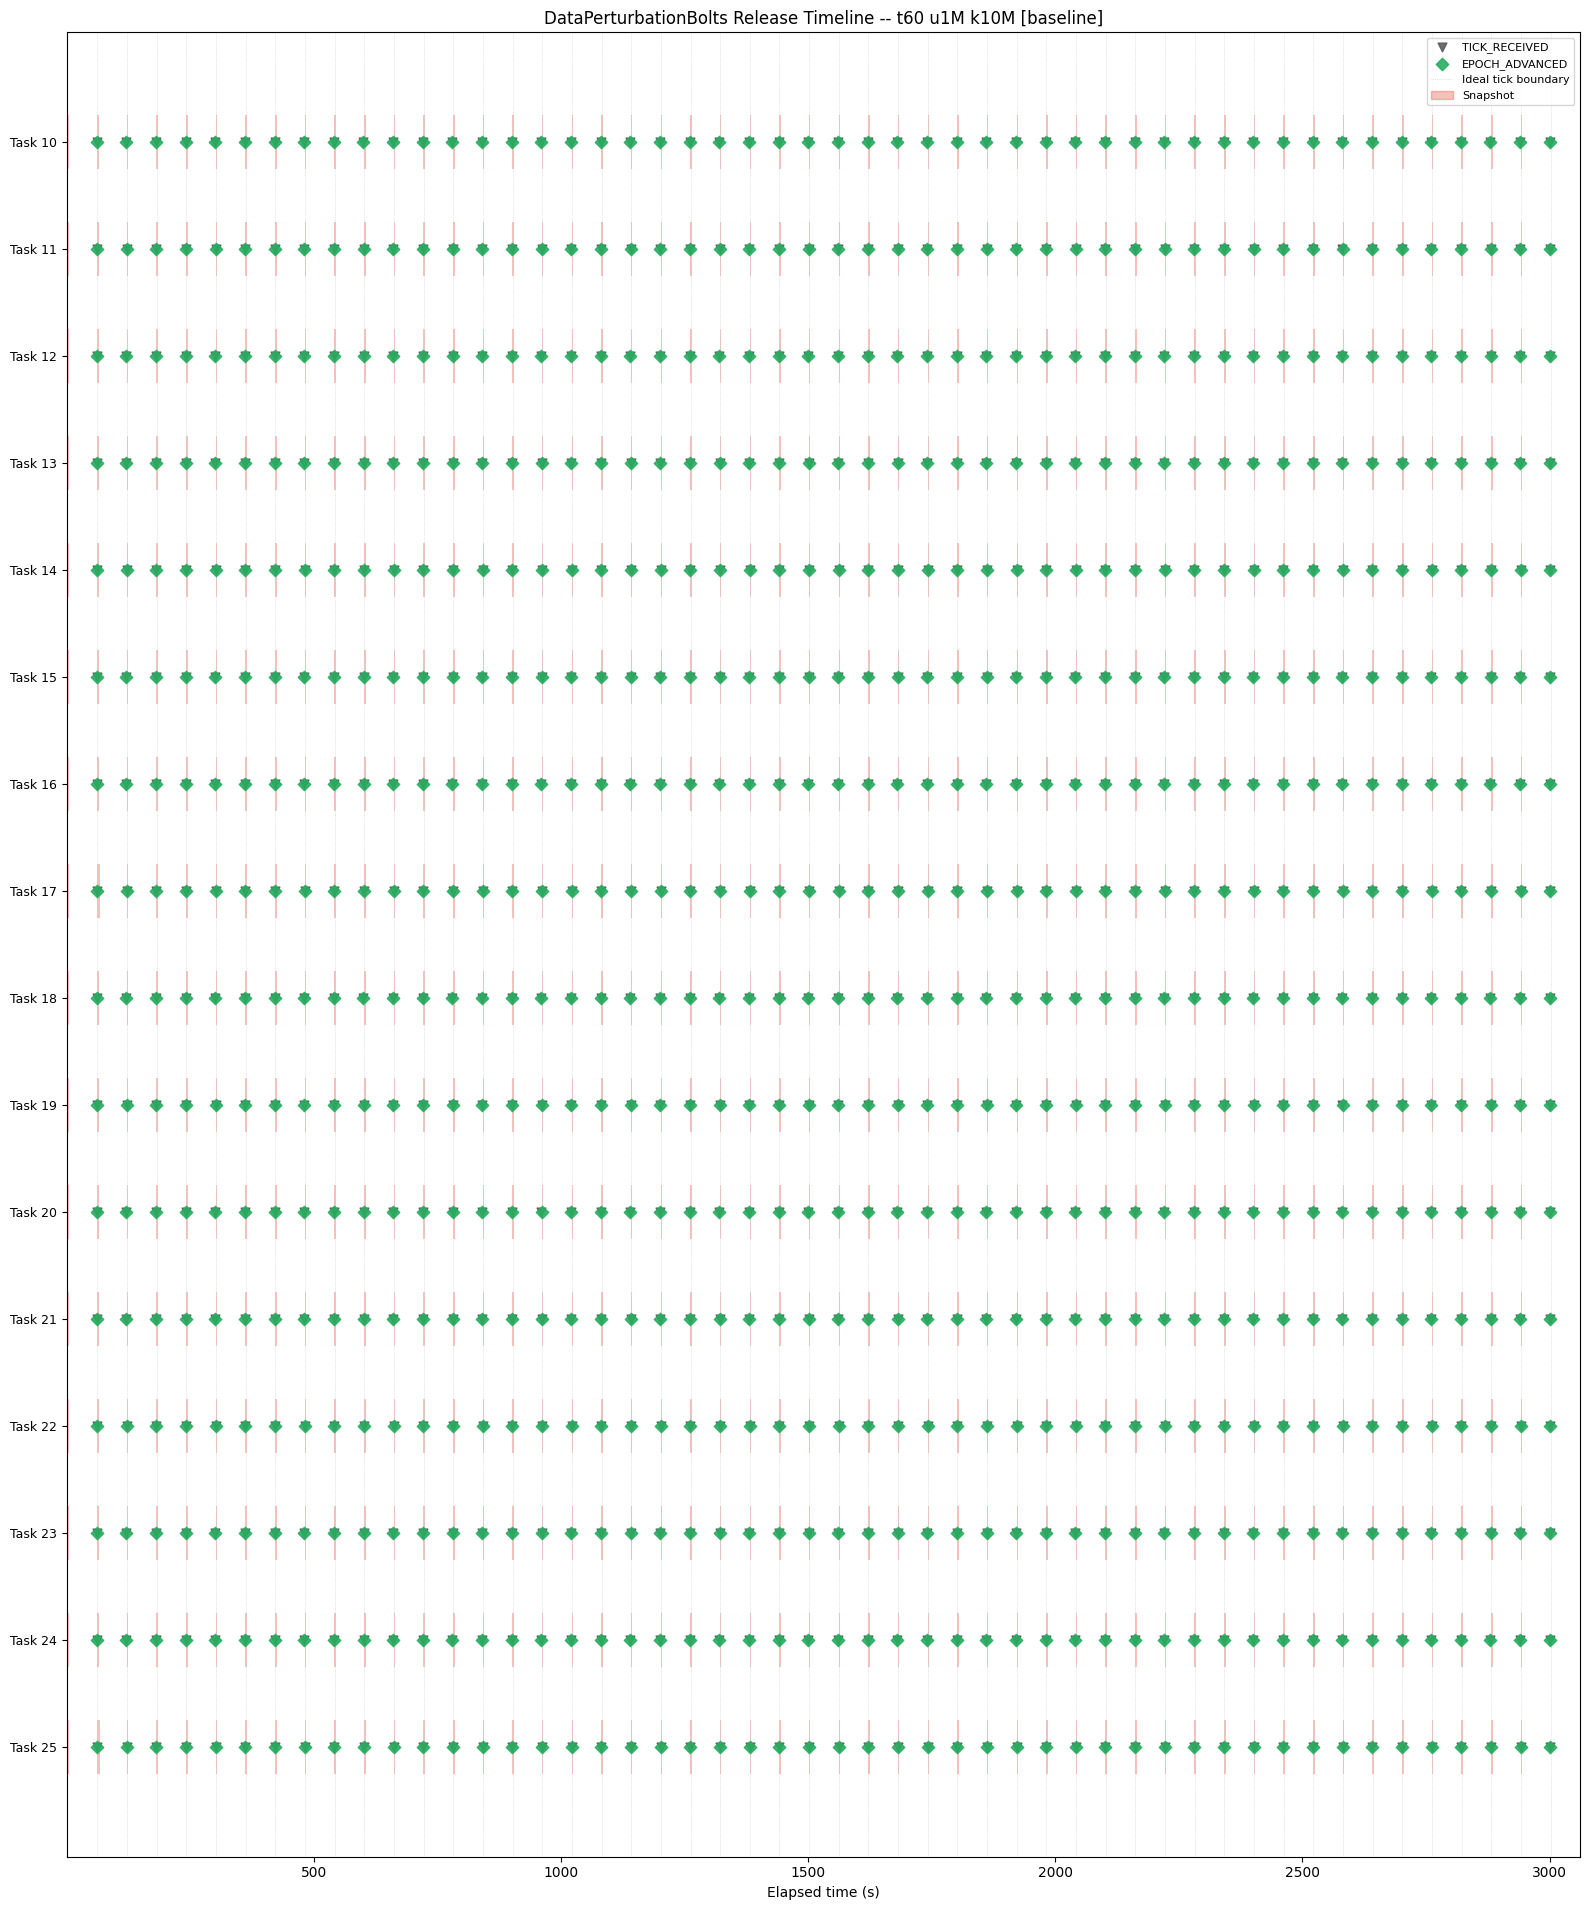

In [38]:
if SINGLE_RUN_IDX is not None:
    lifecycle = get_lifecycle_events(df)
    dp_release_timeline(
        df, lifecycle,
        title=f"DataPerturbationBolts Release Timeline -- {run_info['label']} [{run_info['topology_type']}]",
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        plot_name="d1c-dp-release-timeline",
        fmt=PLOT_FORMAT,
    )

We expect to see real emissions (green) occurring shortly after - even milliseconds - tick reception (grey triangles). 

If there are significant delays between tick reception and real emissions, it indicates that the topology is struggling to keep up with the expected tick intervals, which could be a sign of performance issues or bottlenecks.

#### D1d: Tick tuple irregularity analysis

The following two-panel analysis focuses on the timing regularity of tick tuples received by the data-perturbation bolt. These are emitted by Apache Storm at regular intervals to trigger the snapshot computation and the emission of partial histograms and are critical for the correct functioning of the topology.

The top panel shows a scatter plot of the inter-tick deltas (time between consecutive ticks) for each task over elapsed time. The expected tick interval is shown as a horizontal band ($\pm20\%$) to visually assess whether the ticks are arriving at regular intervals or, conversely, if there are significant deviations that could indicate timing irregularities.

The bottom panel shows the rolling standard deviation of the inter-tick deltas with a window size of 5. This helps to identify whether any observed irregularities in tick timing are persistent or if they diminish over time.

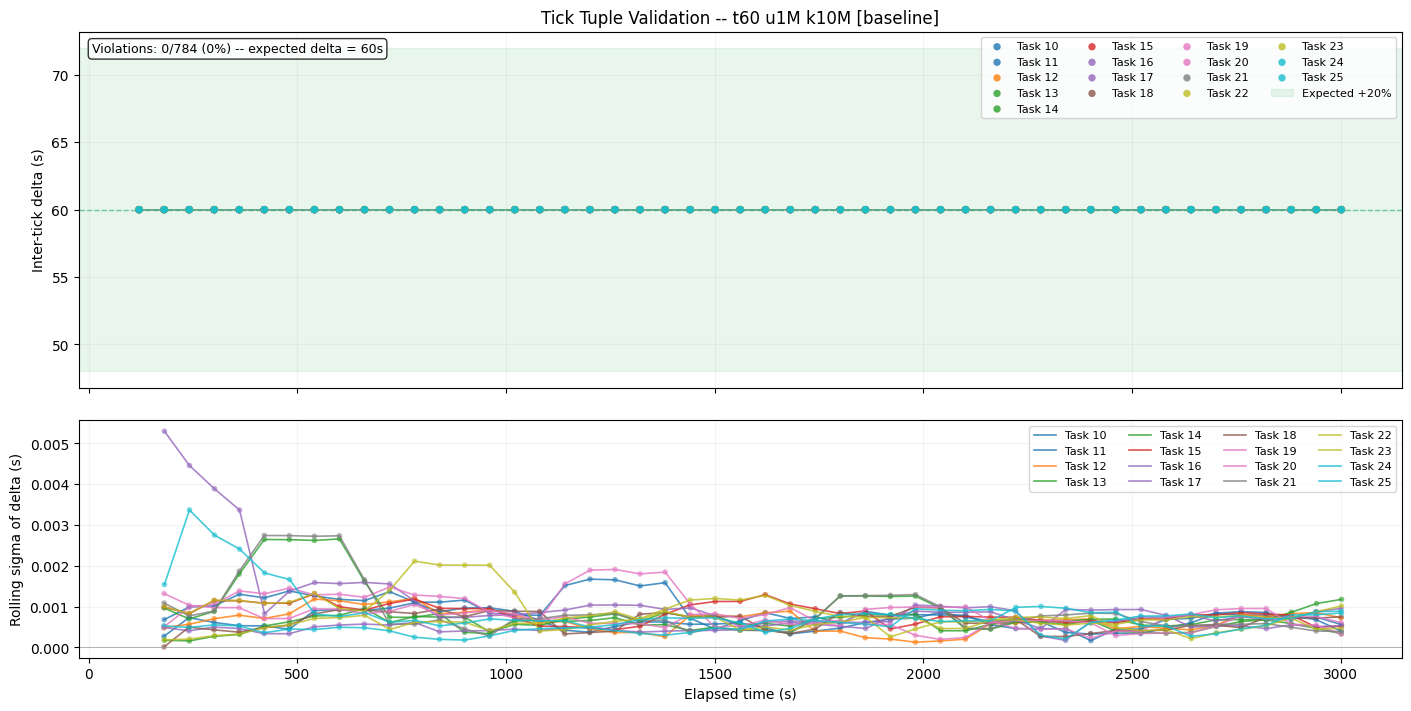

In [39]:
if SINGLE_RUN_IDX is not None:
    lifecycle = get_lifecycle_events(df)
    tick_tuple_validation(
        df, lifecycle,
        title=f"Tick Tuple Validation -- {run_info['label']} [{run_info['topology_type']}]",
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        plot_name="d1d-tick-tuple-validation",
        fmt=PLOT_FORMAT,
    )

#### D1e: Traffic Pattern Validation

Validates the constant-rate communication pattern by measuring inter-emission deltas per task.
Each emission (real partial or dummy) should occur approximately once per tick interval.
Scatter plot shows per-task deltas with a tolerance band (+20%) around the expected tick interval.
Violations are printed with details.

In [40]:
if SINGLE_RUN_IDX is not None:
    lifecycle = get_lifecycle_events(df)
    traffic_pattern_analysis(
        df, lifecycle,
        title=f"Traffic Pattern Validation -- {run_info['label']} [{run_info['topology_type']}]",
        output_dir=OUTPUT_DIR if SAVE_PLOTS else None,
        plot_name="d1d-traffic-pattern",
        fmt=PLOT_FORMAT,
    )

Traffic pattern validation: tick_interval=60s, tolerance=+12.0s (48.0-72.0s)
  Total emissions: 784, Violations: 0
  Task 10: ALL OK (49 intervals)
  Task 11: ALL OK (49 intervals)
  Task 12: ALL OK (49 intervals)
  Task 13: ALL OK (49 intervals)
  Task 14: ALL OK (49 intervals)
  Task 15: ALL OK (49 intervals)
  Task 16: ALL OK (49 intervals)
  Task 17: ALL OK (49 intervals)
  Task 18: ALL OK (49 intervals)
  Task 19: ALL OK (49 intervals)
  Task 20: ALL OK (49 intervals)
  Task 21: ALL OK (49 intervals)
  Task 22: ALL OK (49 intervals)
  Task 23: ALL OK (49 intervals)
  Task 24: ALL OK (49 intervals)
  Task 25: ALL OK (49 intervals)


KeyboardInterrupt: 

### D2: Epoch & Snapshot Duration Analysis

Filters data to the active window and analyzes epoch/snapshot durations.

Topology fully started at: 2.1s
Topology shutdown at: 3021.1s
Active window: 3019.0s
Filtered: 4704 -> 1200 rows


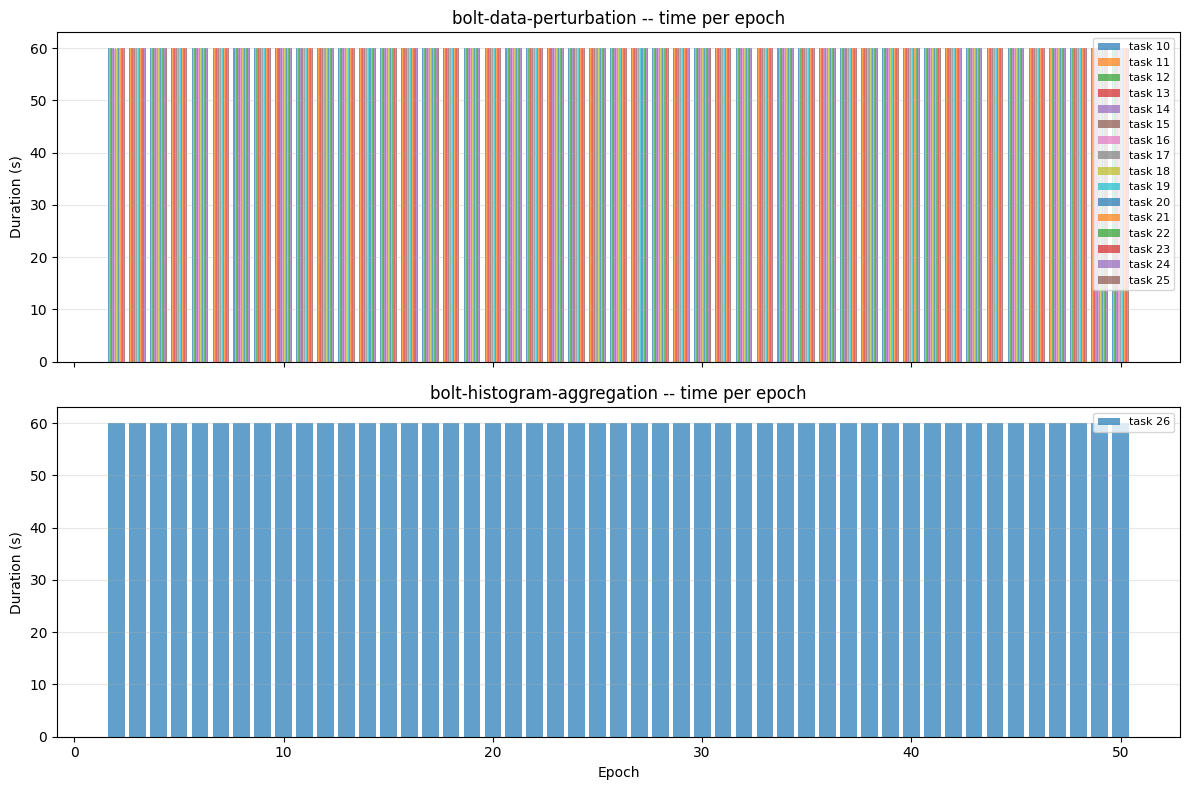

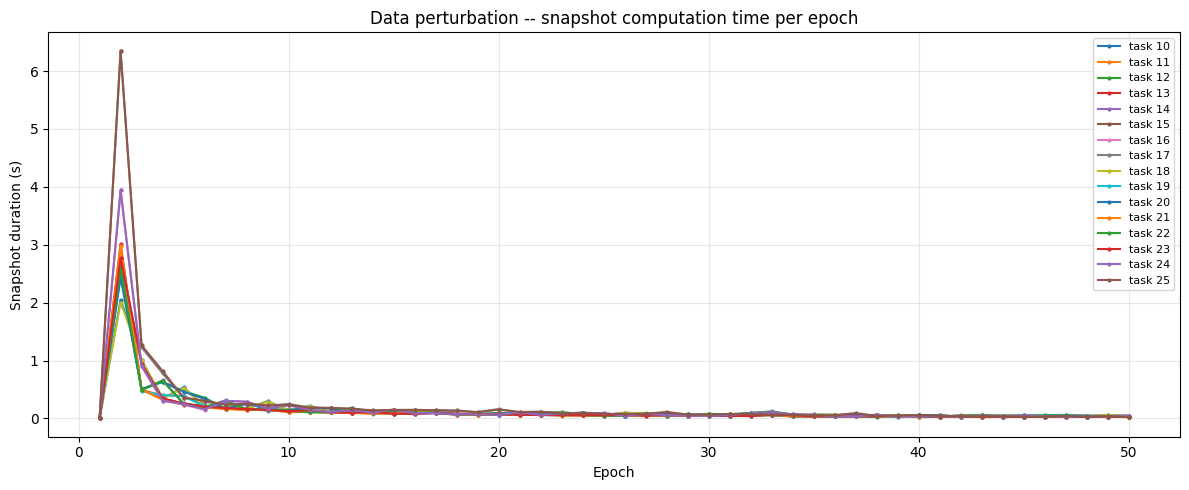

In [ ]:
if SINGLE_RUN_IDX is not None:
    lifecycle = get_lifecycle_events(df)
    started = lifecycle[lifecycle["event"] == "COMPONENT_STARTED"]
    stopping = lifecycle[lifecycle["event"] == "COMPONENT_STOPPING"]

    if started.empty:
        print("WARNING: No COMPONENT_STARTED events - using first-row heuristic")
        task_start_times = df.groupby(["component", "taskId"])["elapsed_s"].min().sort_values()
        topology_ready_s = task_start_times.max()
        topology_shutdown_s = df["elapsed_s"].max()
    else:
        task_start_times = started.groupby(["component", "taskId"])["elapsed_s"].min().sort_values()
        topology_ready_s = task_start_times.max()
        topology_shutdown_s = stopping.groupby(["component", "taskId"])["elapsed_s"].min().min() if not stopping.empty else df["elapsed_s"].max()

    print(f"Topology fully started at: {topology_ready_s:.1f}s")
    print(f"Topology shutdown at: {topology_shutdown_s:.1f}s")
    print(f"Active window: {topology_shutdown_s - topology_ready_s:.1f}s")

    rows_before = len(df)
    df = df[(df["elapsed_s"] >= topology_ready_s) & (df["elapsed_s"] <= topology_shutdown_s) & (df["type"] != "lifecycle")].copy()
    print(f"Filtered: {rows_before} -> {len(df)} rows")

    # Epoch events for plots
    epoch_events = lifecycle[lifecycle["event"].isin(["EPOCH_ADVANCED", "SNAPSHOT_STARTED", "SNAPSHOT_COMPLETED", "MAX_EPOCH_REACHED"])]
    max_epoch_ev = epoch_events[epoch_events["event"] == "MAX_EPOCH_REACHED"]
    max_epoch = max_epoch_ev["elapsed_s"].max() if not max_epoch_ev.empty else None

    # Epoch duration plot
    epoch_adv = epoch_events[epoch_events["event"] == "EPOCH_ADVANCED"]
    if not epoch_adv.empty:
        components = sorted(epoch_adv["component"].unique())
        fig, axes = plt.subplots(len(components), 1, figsize=(12, 4 * len(components)), sharex=True, squeeze=False)
        for idx, comp in enumerate(components):
            ax = axes[idx, 0]
            comp_data = epoch_adv[epoch_adv["component"] == comp]
            tasks = sorted(comp_data["taskId"].unique())
            bar_width = 0.8 / len(tasks)
            for i, task in enumerate(tasks):
                td = comp_data[comp_data["taskId"] == task].sort_values("epoch")
                durations = td["elapsed_s"].diff()
                x_offset = (i - (len(tasks) - 1) / 2) * bar_width
                ax.bar(td["epoch"].iloc[1:] + x_offset, durations.iloc[1:], label=f"task {task}", color=color_for(i), alpha=0.7, width=bar_width)
            ax.set_ylabel("Duration (s)")
            ax.set_title(f"{comp} -- time per epoch")
            ax.legend(fontsize=8)
            ax.grid(True, axis="y", alpha=0.3)
        axes[-1, 0].set_xlabel("Epoch")
        save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, "d2-epoch-duration", PLOT_FORMAT, True)

    # Snapshot duration plot
    snap_start = epoch_events[epoch_events["event"] == "SNAPSHOT_STARTED"]
    snap_end = epoch_events[epoch_events["event"] == "SNAPSHOT_COMPLETED"]
    if not snap_start.empty and not snap_end.empty:
        merged = snap_start.merge(snap_end, on=["component", "taskId", "epoch"], suffixes=("_start", "_end"))
        merged["snap_duration_s"] = merged["elapsed_s_end"] - merged["elapsed_s_start"]
        tasks = sorted(merged["taskId"].unique())
        fig, ax = plt.subplots(figsize=(12, 5))
        for i, task in enumerate(tasks):
            td = merged[merged["taskId"] == task].sort_values("epoch")
            ax.plot(td["epoch"], td["snap_duration_s"], label=f"task {task}", color=color_for(i), linewidth=1.5, marker=".", markersize=4)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Snapshot duration (s)")
        ax.set_title("Data perturbation -- snapshot computation time per epoch")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, "d2-snapshot-duration", PLOT_FORMAT, True)

### D3: ECALL Latency Over Time

Per-component, per-ECALL line plot of average latency (ms) over elapsed time. One plot per component and ECALL name, with one line per task. A vertical dashed line marks `MAX_EPOCH_REACHED`.

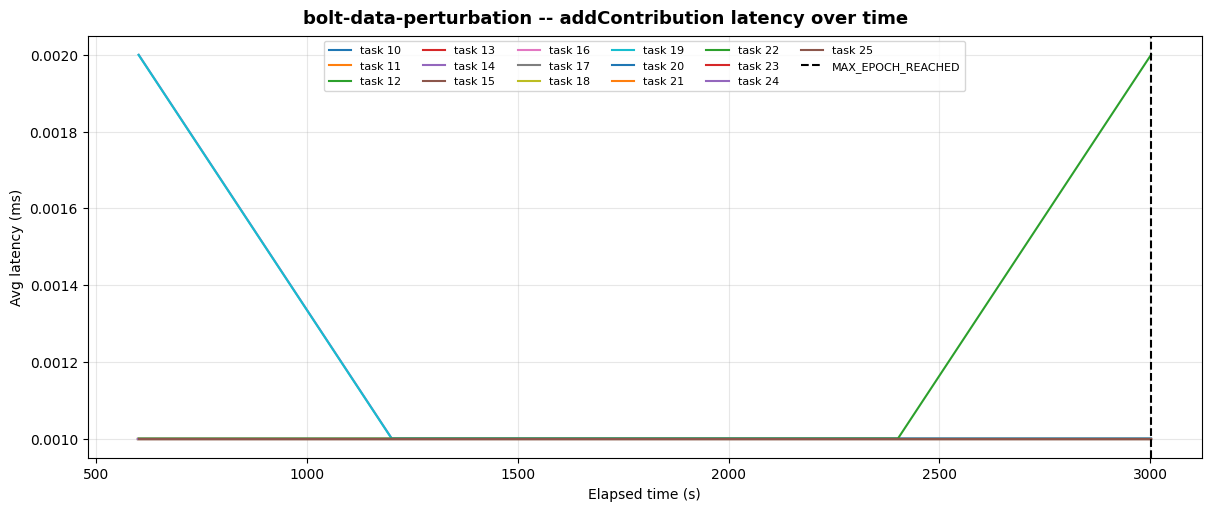

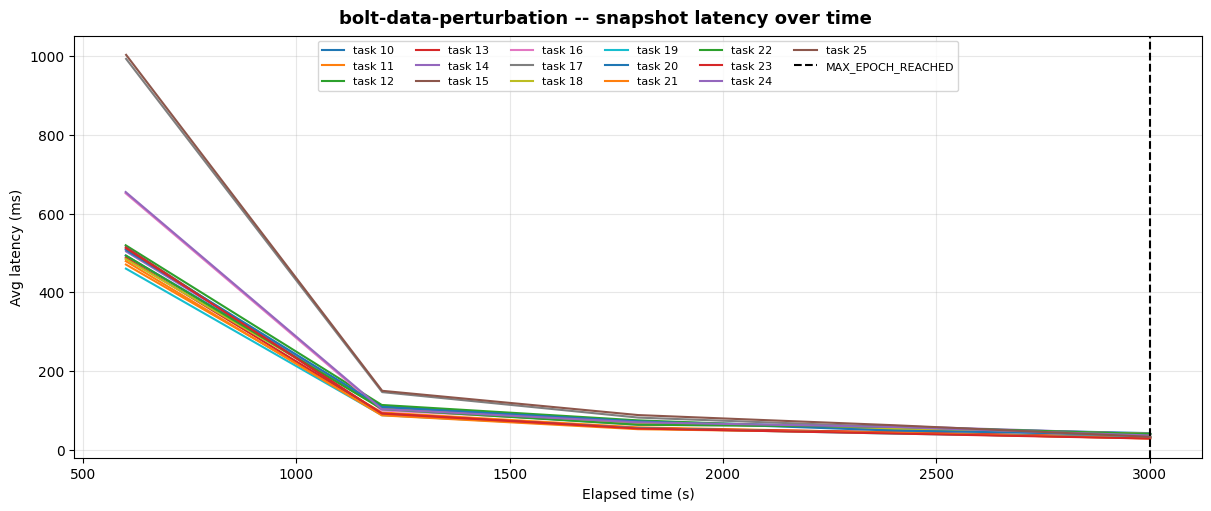

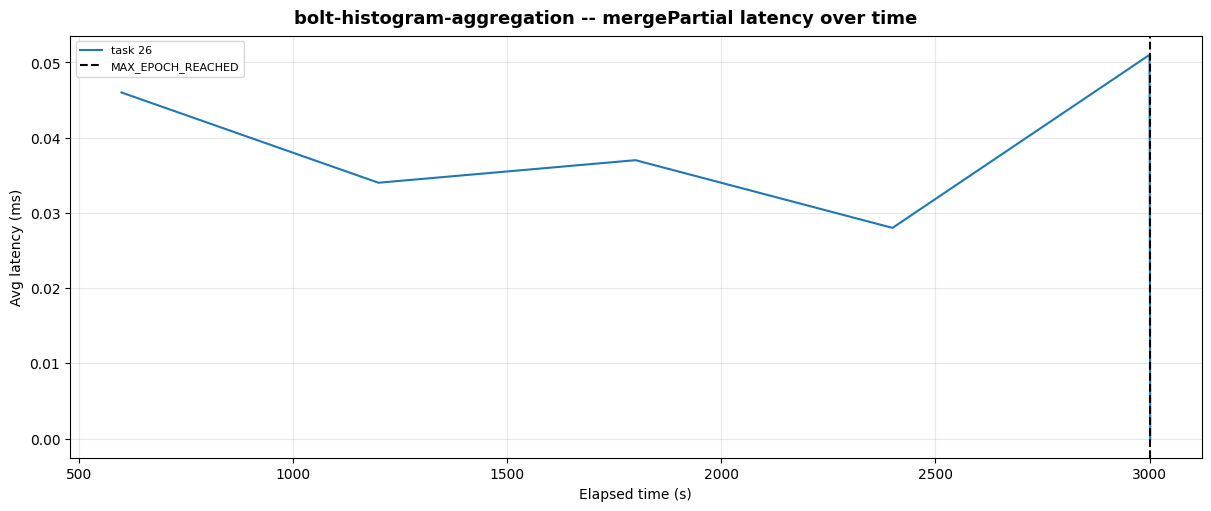

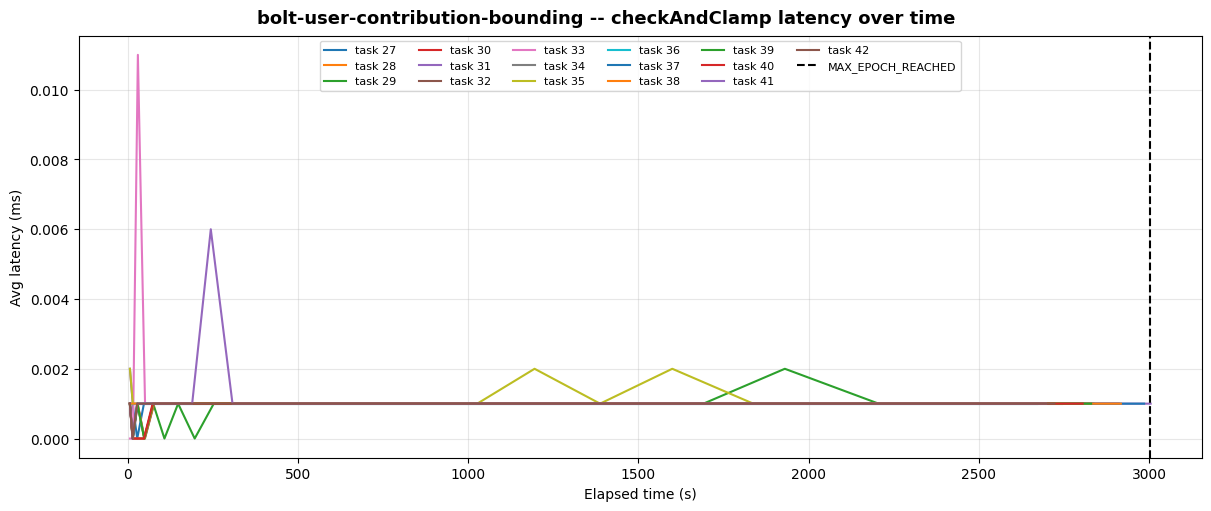

In [ ]:
if SINGLE_RUN_IDX is not None:
    ecalls = df[df["type"] == "ecall"]
    if not ecalls.empty:
        components = _get_components(ecalls)
        for comp in components:
            comp_data = ecalls[ecalls["component"] == comp]
            ecall_names = _get_ecall_names(ecalls, comp)
            for ecall_name in ecall_names:
                ed = comp_data[comp_data["name"] == ecall_name]
                tasks = sorted(ed["taskId"].unique())
                n_tasks = len(tasks)
                fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
                for i, task in enumerate(tasks):
                    td = ed[ed["taskId"] == task].sort_values("elapsed_s")
                    ax.plot(td["elapsed_s"], td["avgMs"], label=f"task {task}", color=color_for(i), linewidth=1.5)
                if max_epoch is not None and not np.isnan(max_epoch):
                    ax.axvline(max_epoch, color=MAX_EPOCH_COLOR, linestyle="--", label="MAX_EPOCH_REACHED")
                ax.set_ylabel("Avg latency (ms)")
                ax.legend(fontsize=8, ncol=min(n_tasks, 6))
                ax.grid(True, alpha=0.3)
                format_elapsed_axis(ax)
                fig.suptitle(f"{comp} -- {ecall_name} latency over time", fontsize=13, fontweight="bold")
                save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, f"d3-latency-{comp}-{ecall_name}", PLOT_FORMAT, True)

### D4: ECALL Latency Distribution (Box Plots)

Per-component box plot showing the distribution of average latency (ms) across all ECALL types. Useful for comparing the spread and outliers of different ECALLs within a component.

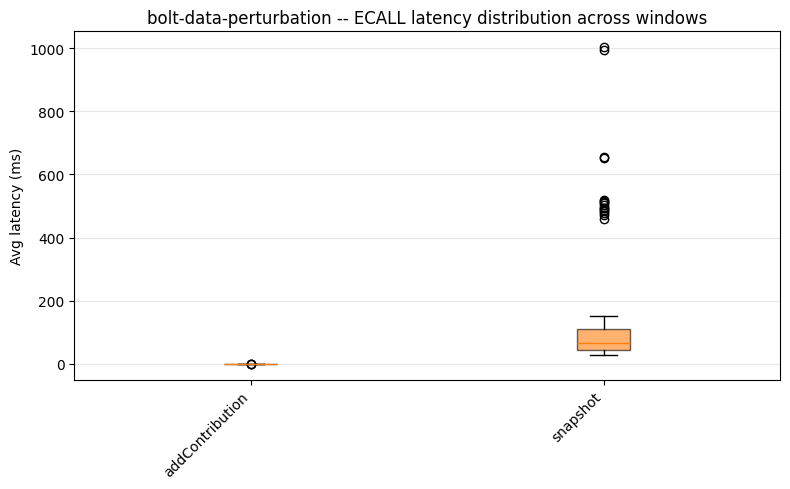

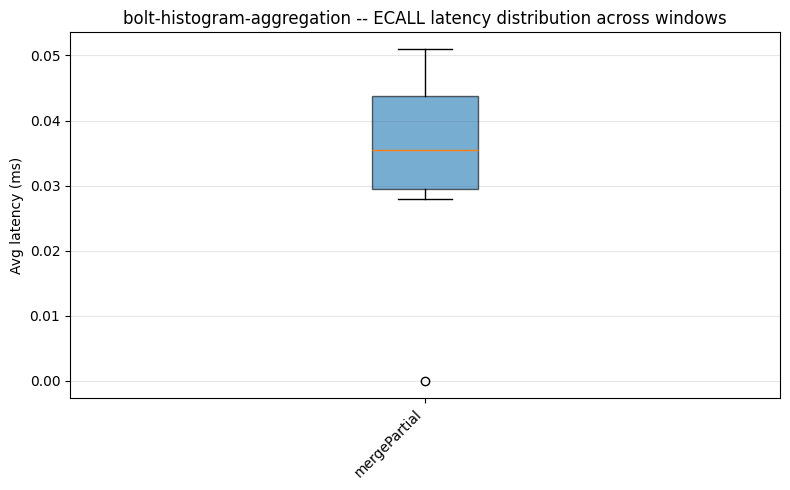

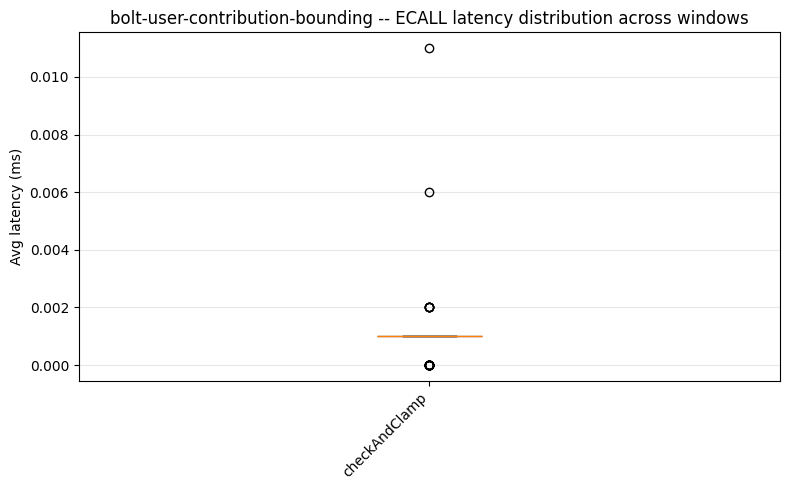

In [ ]:
if SINGLE_RUN_IDX is not None:
    ecalls = df[df["type"] == "ecall"]
    if not ecalls.empty:
        components = _get_components(ecalls)
        for comp in components:
            comp_data = ecalls[ecalls["component"] == comp]
            ecall_names = _get_ecall_names(ecalls, comp)
            data_for_box = []
            box_labels = []
            for en in ecall_names:
                vals = comp_data.loc[comp_data["name"] == en, "avgMs"].dropna()
                if not vals.empty:
                    data_for_box.append(vals.values)
                    box_labels.append(en)
            if not data_for_box:
                continue
            fig, ax = plt.subplots(figsize=adaptive_figsize(len(box_labels), per_item=2.5))
            bp = ax.boxplot(data_for_box, tick_labels=box_labels, patch_artist=True)
            for i, patch in enumerate(bp["boxes"]):
                patch.set_facecolor(color_for(i))
                patch.set_alpha(0.6)
            ax.set_ylabel("Avg latency (ms)")
            ax.set_title(f"{comp} -- ECALL latency distribution across windows")
            ax.grid(True, axis="y", alpha=0.3)
            plt.xticks(rotation=45, ha="right")
            save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, f"d4-boxplot-{comp}", PLOT_FORMAT, True)

### D5: Throughput Over Time

Per-component line plot of total ECALL invocations per second over elapsed time, broken down by ECALL name. A vertical dashed line marks `MAX_EPOCH_REACHED`.

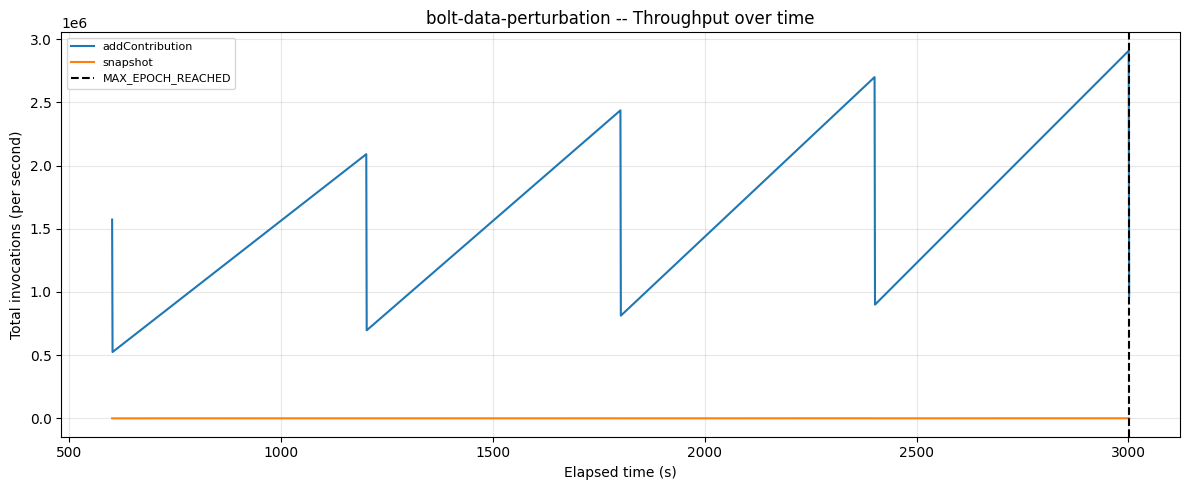

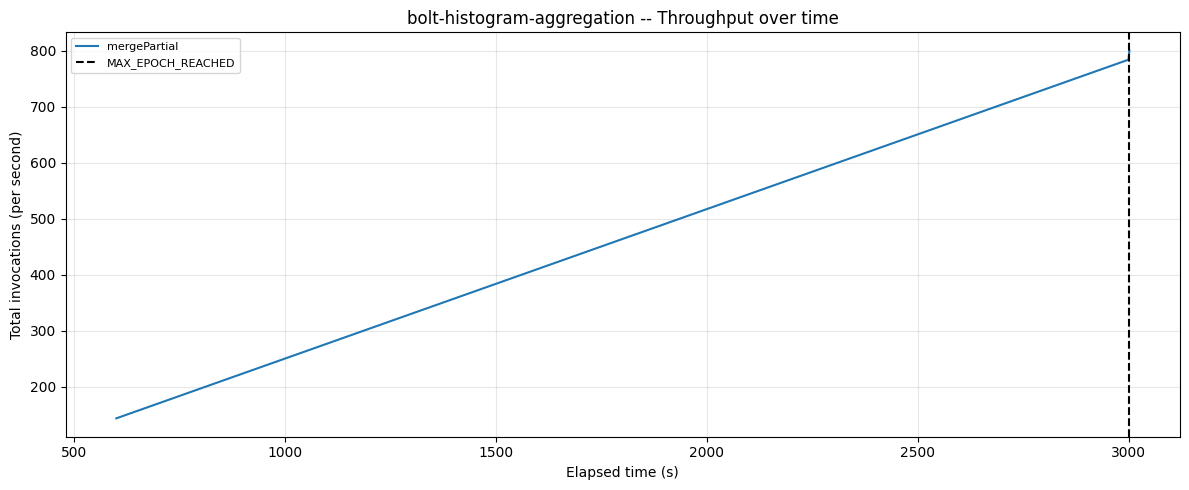

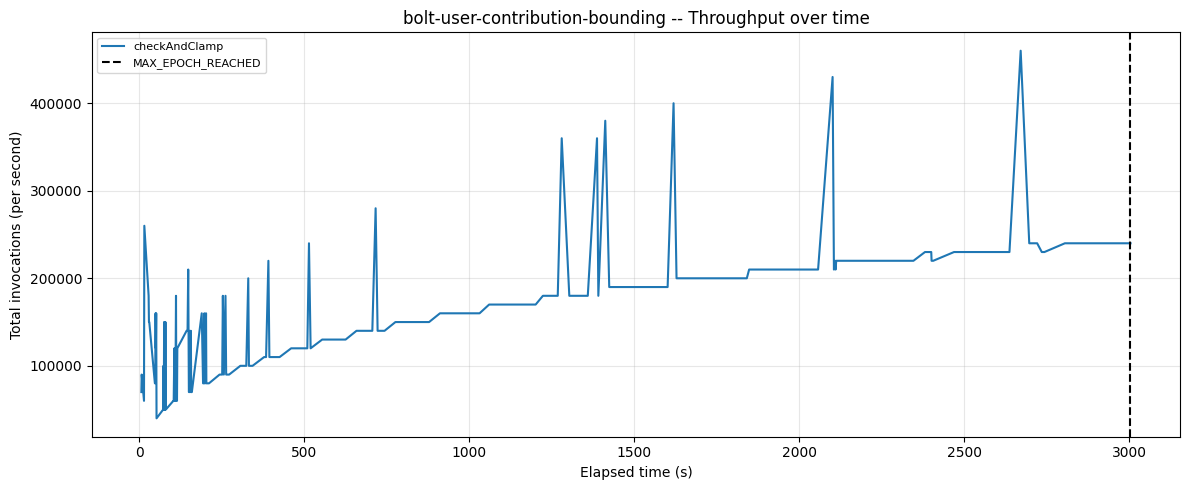

In [ ]:
if SINGLE_RUN_IDX is not None:
    ecalls = df[df["type"] == "ecall"]
    if not ecalls.empty:
        components = _get_components(ecalls)
        for comp in components:
            comp_data = ecalls[ecalls["component"] == comp]
            ecall_names = _get_ecall_names(ecalls, comp)
            fig, ax = plt.subplots(figsize=(12, 5))
            for i, en in enumerate(ecall_names):
                ed = comp_data[comp_data["name"] == en]
                grouped = ed.groupby(ed["elapsed_s"].round())["total"].sum().sort_index()
                ax.plot(grouped.index, grouped.to_numpy(), label=en, color=color_for(i), linewidth=1.5)
            if max_epoch is not None and not np.isnan(max_epoch):
                ax.axvline(max_epoch, color=MAX_EPOCH_COLOR, linestyle="--", label="MAX_EPOCH_REACHED")
            ax.set_ylabel("Total invocations (per second)")
            ax.set_title(f"{comp} -- Throughput over time")
            format_elapsed_axis(ax)
            ax.legend(fontsize=8)
            ax.grid(True, alpha=0.3)
            save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, f"d5-throughput-{comp}", PLOT_FORMAT, True)

### D6: Counter Evolution Over Time

Per-component, per-counter line plot showing how each counter metric evolves over elapsed time. One subplot per counter, one line per task. Useful for tracking cumulative event counts (e.g., tuples processed, contributions bounded).

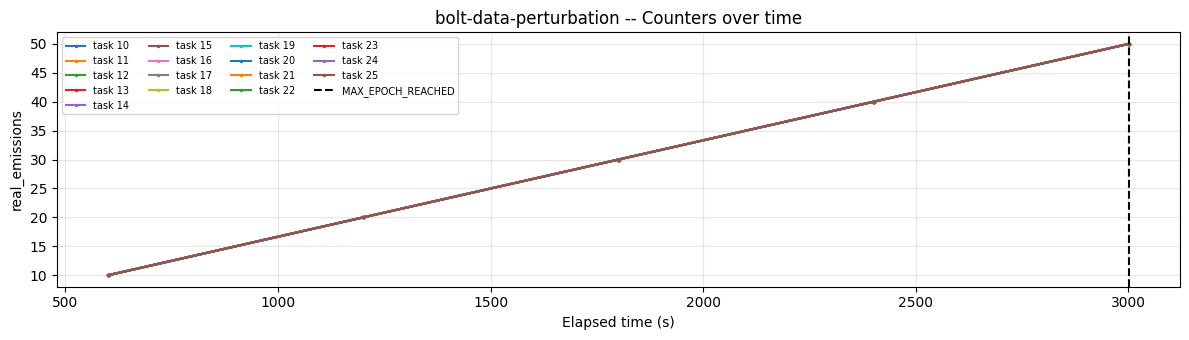

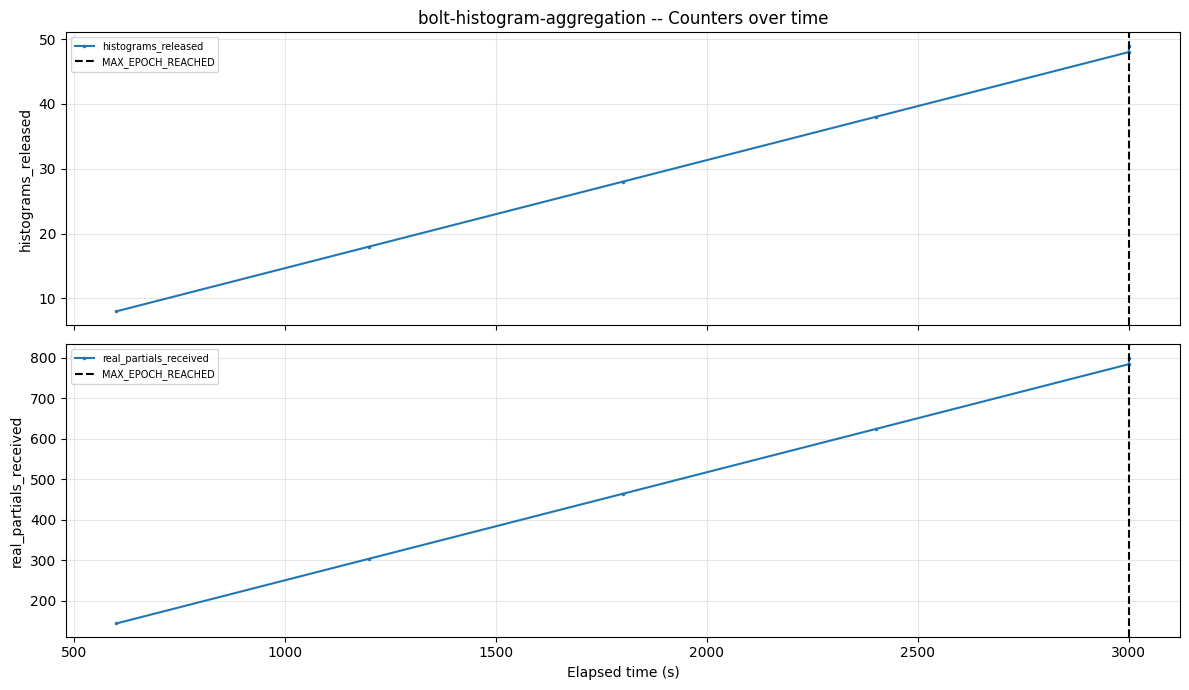

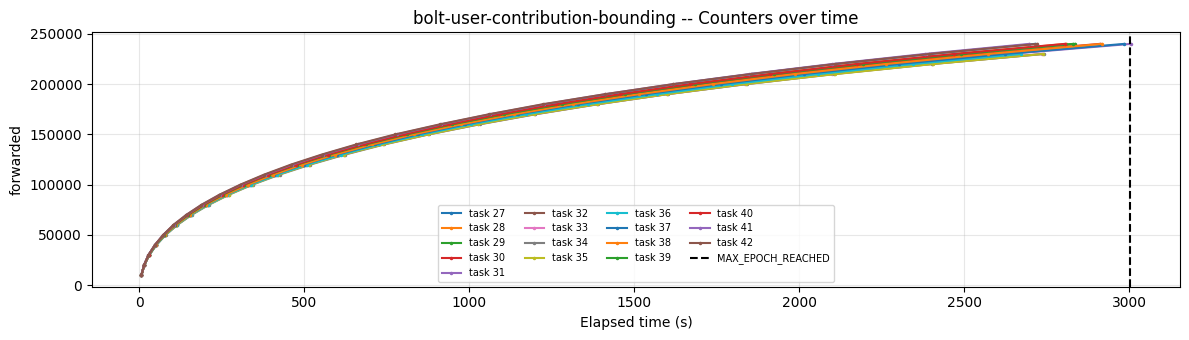

In [ ]:
if SINGLE_RUN_IDX is not None:
    counters = df[df["type"] == "counter"]
    if not counters.empty:
        components = _get_components(counters)
        for comp in components:
            comp_data = counters[counters["component"] == comp]
            counter_names = sorted(comp_data["name"].unique())
            if not counter_names:
                continue
            tasks = sorted(comp_data["taskId"].unique())
            n_counters = len(counter_names)
            fig, axes = plt.subplots(n_counters, 1, figsize=(12, 3.5 * n_counters), sharex=True, squeeze=False)
            for i, cn in enumerate(counter_names):
                ax = axes[i, 0]
                cd = comp_data[comp_data["name"] == cn]
                for j, task in enumerate(tasks):
                    td = cd[cd["taskId"] == task].sort_values("elapsed_s")
                    lbl = f"task {task}" if len(tasks) > 1 else cn
                    ax.plot(td["elapsed_s"], td["total"], label=lbl, color=color_for(j), linewidth=1.5, marker=".", markersize=3)
                if max_epoch is not None and not np.isnan(max_epoch):
                    ax.axvline(max_epoch, color=MAX_EPOCH_COLOR, linestyle="--", label="MAX_EPOCH_REACHED")
                ax.set_ylabel(cn)
                ax.legend(fontsize=7, ncol=min(len(tasks), 4))
                ax.grid(True, alpha=0.3)
            axes[0, 0].set_title(f"{comp} -- Counters over time")
            format_elapsed_axis(axes[-1, 0])
            save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, f"d6-counters-{comp}", PLOT_FORMAT, True)

### D7: Gauge Evolution Over Time

Per-component, per-gauge line plot showing how each gauge metric evolves over elapsed time. One subplot per gauge, one line per task. Useful for tracking instantaneous values (e.g., queue sizes, memory usage) throughout the run.

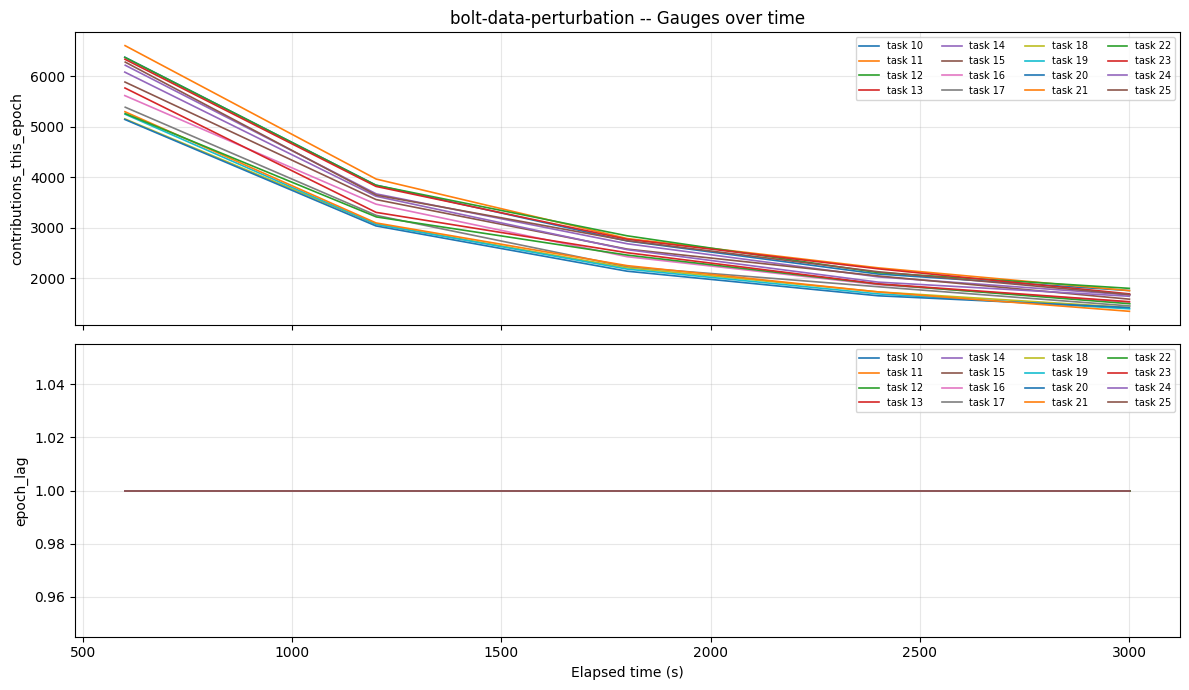

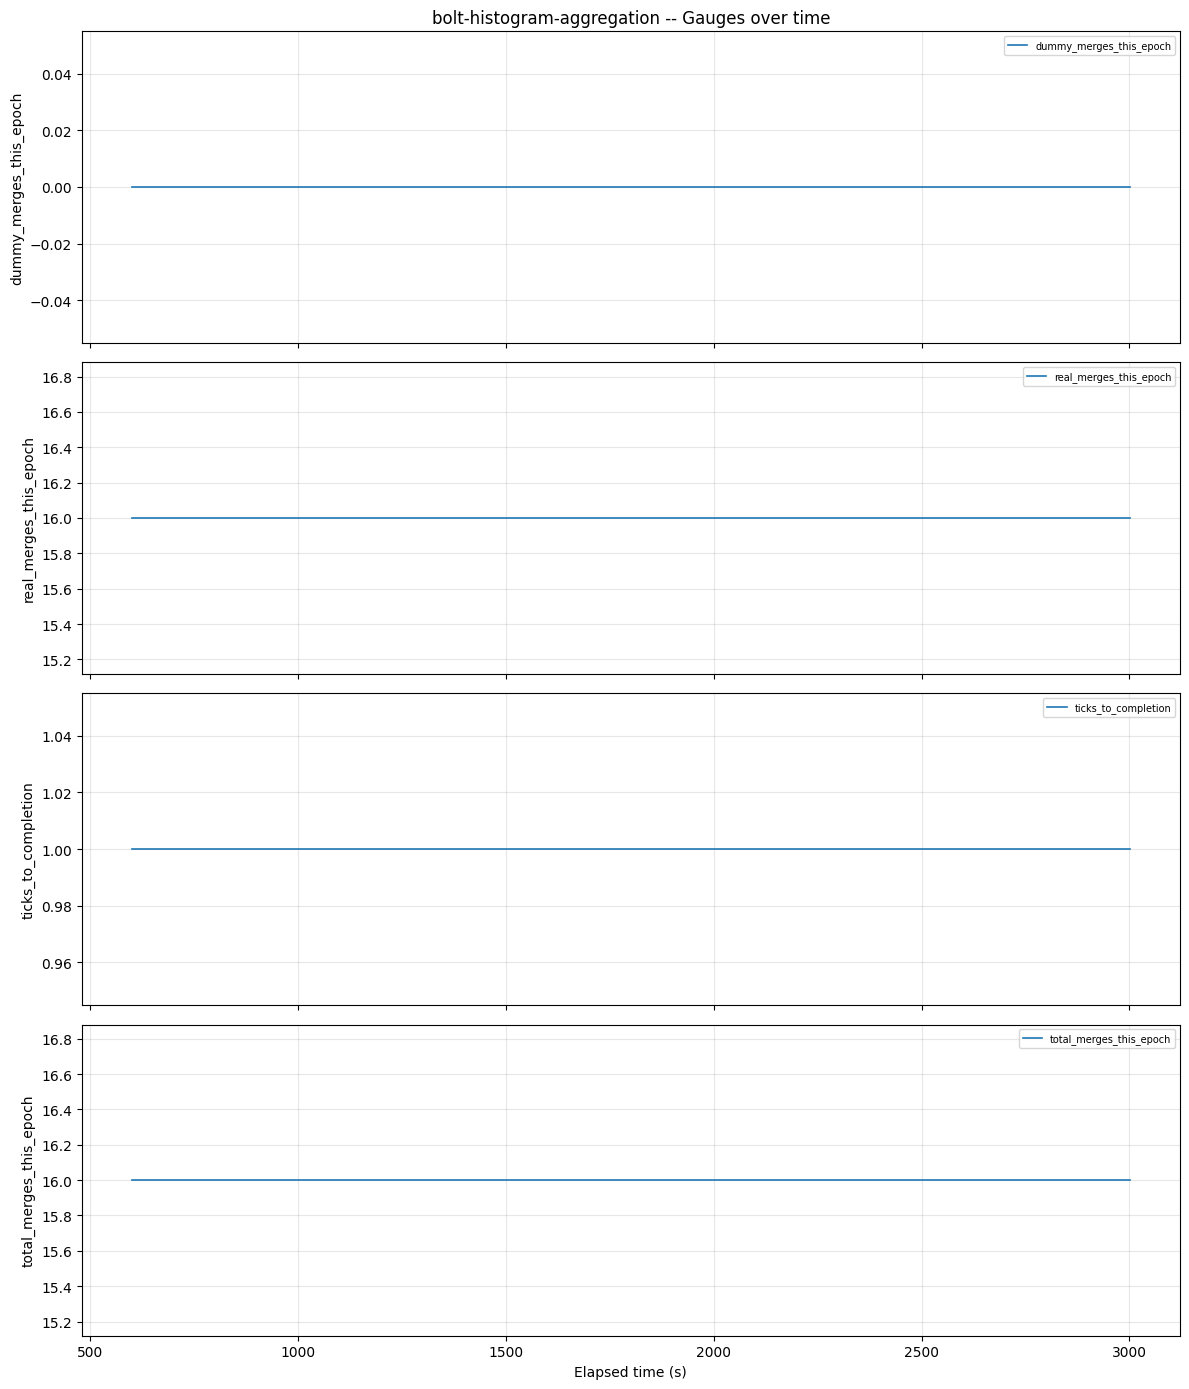

In [ ]:
if SINGLE_RUN_IDX is not None:
    gauges = cast(pd.DataFrame, df[df["type"] == "gauge"])
    if not gauges.empty:
        components = _get_components(gauges)
        for comp in components:
            comp_data = cast(pd.DataFrame, gauges[gauges["component"] == comp])
            gauge_names = sorted(comp_data["name"].unique())
            if not gauge_names:
                continue
            n_gauges = len(gauge_names)
            fig, axes = plt.subplots(n_gauges, 1, figsize=(12, 3.5 * n_gauges), sharex=True, squeeze=False)
            for i, gn in enumerate(gauge_names):
                ax = axes[i, 0]
                gd = cast(pd.DataFrame, comp_data[comp_data["name"] == gn])
                tasks = sorted(gd["taskId"].unique())
                for j, task in enumerate(tasks):
                    td = cast(pd.DataFrame, gd[gd["taskId"] == task]).sort_values("elapsed_s")
                    lbl = f"task {task}" if len(tasks) > 1 else gn
                    ax.plot(td["elapsed_s"], td["total"], label=lbl, color=color_for(j), linewidth=1.2)
                ax.set_ylabel(gn)
                ax.legend(fontsize=7, ncol=min(len(tasks), 4))
                ax.grid(True, alpha=0.3)
            axes[0, 0].set_title(f"{comp} -- Gauges over time")
            format_elapsed_axis(axes[-1, 0])
            save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, f"d7-gauges-{comp}", PLOT_FORMAT, True)

### D8: Task Imbalance Comparison

Per-component, per-ECALL side-by-side comparison of task latency distributions. Left: box plot of average latency per task. Right: bar chart of total invocations per task. Highlights load imbalance when tasks process significantly different amounts of work.

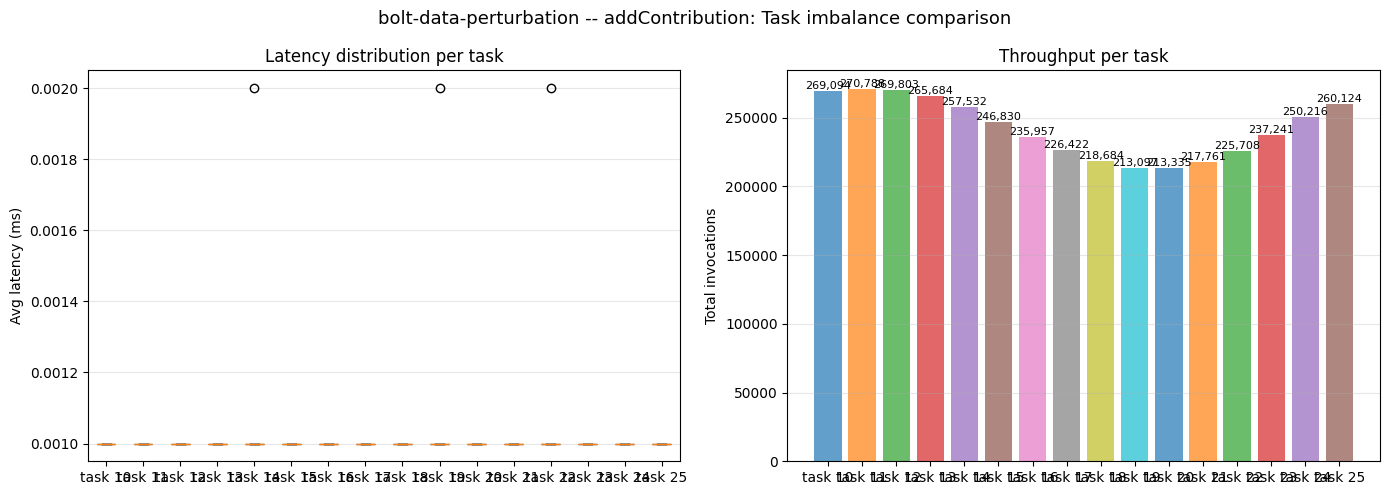

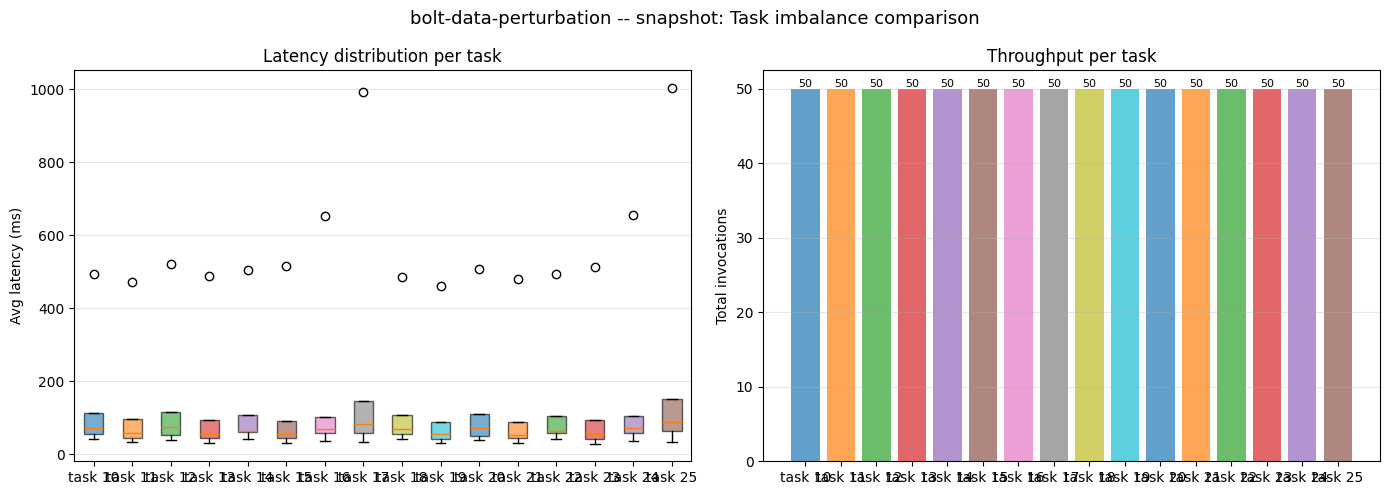

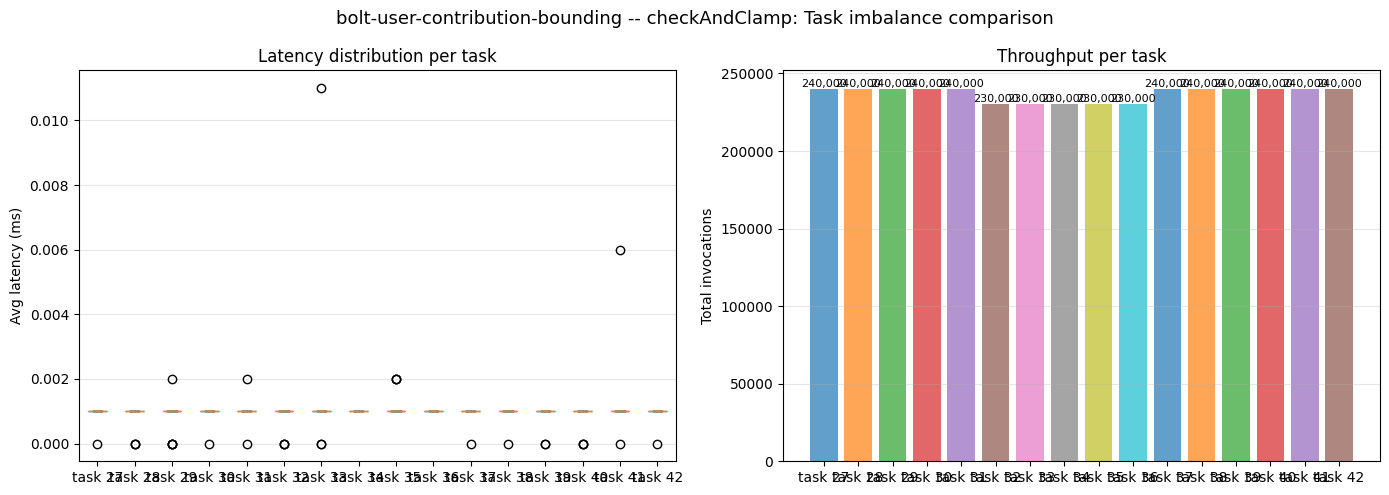

In [ ]:
if SINGLE_RUN_IDX is not None:
    ecalls = cast(pd.DataFrame, df[df["type"] == "ecall"])
    if not ecalls.empty:
        components = _get_components(ecalls)
        for comp in components:
            comp_data = cast(pd.DataFrame, ecalls[ecalls["component"] == comp])
            tasks = sorted(comp_data["taskId"].unique())
            if len(tasks) < 2:
                continue
            ecall_names = _get_ecall_names(ecalls, comp)
            for en in ecall_names:
                ed = cast(pd.DataFrame, comp_data[comp_data["name"] == en])
                fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
                task_latencies = []
                task_labels = []
                for t in tasks:
                    vals = ed.loc[ed["taskId"] == t, "avgMs"].dropna()
                    if not vals.empty:
                        task_latencies.append(vals.values)
                        task_labels.append(f"task {t}")
                if task_latencies:
                    bp = ax1.boxplot(task_latencies, tick_labels=task_labels, patch_artist=True)
                    for i, patch in enumerate(bp["boxes"]):
                        patch.set_facecolor(color_for(i))
                        patch.set_alpha(0.6)
                ax1.set_ylabel("Avg latency (ms)")
                ax1.set_title("Latency distribution per task")
                ax1.grid(True, axis="y", alpha=0.3)
                task_totals = []
                for t in tasks:
                    td = cast(pd.DataFrame, ed[ed["taskId"] == t])
                    task_totals.append(int(td["total"].max()) if not td.empty else 0)
                bars = ax2.bar([f"task {t}" for t in tasks], task_totals,
                               color=[color_for(i) for i in range(len(tasks))], alpha=0.7)
                ax2.set_ylabel("Total invocations")
                ax2.set_title("Throughput per task")
                ax2.grid(True, axis="y", alpha=0.3)
                for bar, val in zip(bars, task_totals):
                    if val > 0:
                        ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                                 f"{val:,.0f}", ha="center", va="bottom", fontsize=8)
                fig.suptitle(f"{comp} -- {en}: Task imbalance comparison", fontsize=13)
                save_or_show(fig, OUTPUT_DIR if SAVE_PLOTS else None, f"d8-imbalance-{comp}-{en}", PLOT_FORMAT, True)

## D9: Single-run summary table

In [ ]:
if SINGLE_RUN_IDX is not None:
    ecalls = cast(pd.DataFrame, df[df["type"] == "ecall"])
    counters = cast(pd.DataFrame, df[df["type"] == "counter"])
    gauges = cast(pd.DataFrame, df[df["type"] == "gauge"])
    lifecycle = get_lifecycle_events(df)
    components = _get_components(df)

    # --- Table 1: ECALL summary ---
    ecall_rows = []
    for comp in components:
        ce = cast(pd.DataFrame, ecalls[ecalls["component"] == comp])
        for en in sorted(ce["name"].unique()):
            ed = cast(pd.DataFrame, ce[ce["name"] == en])
            ecall_rows.append({
                "Component": comp,
                "ECALL": en,
                "Avg (ms)": round(ed["avgMs"].mean(), 2),
                "Min (ms)": round(ed["minMs"].min(), 2),
                "Max (ms)": round(ed["maxMs"].max(), 2),
                "Total calls": int(ed["total"].max()),
                "Tasks": len(ed["taskId"].unique()),
            })
    if ecall_rows:
        print("=== ECALL Summary ===")
        display(pd.DataFrame(ecall_rows))

    # --- Table 2: Topology & lifecycle summary ---
    topo_rows = []
    for comp in components:
        comp_lc = lifecycle[lifecycle["component"] == comp]
        comp_counters = counters[counters["component"] == comp]
        n_tasks = df[df["component"] == comp]["taskId"].nunique()

        row: dict = {"Component": comp, "Tasks": n_tasks}

        # Epochs completed (per task, then min/max across tasks)
        epoch_adv = comp_lc[comp_lc["event"] == "EPOCH_ADVANCED"]
        if not epoch_adv.empty:
            per_task_max = epoch_adv.groupby("taskId")["epoch"].max()
            row["Epochs (min task)"] = int(per_task_max.min())
            row["Epochs (max task)"] = int(per_task_max.max())

            # Avg epoch duration (time between successive EPOCH_ADVANCED per task)
            durations = []
            for task, grp in epoch_adv.groupby("taskId"):
                grp = grp.sort_values("epoch")
                diffs = grp["elapsed_s"].diff().dropna()
                durations.extend(diffs.tolist())
            if durations:
                row["Avg epoch duration (s)"] = round(np.mean(durations), 2)
                row["Std epoch duration (s)"] = round(np.std(durations), 2)

        # Real / dummy emissions per task (from counters)
        for counter_name, label in [("real_emissions", "Real partials"),
                                     ("dummy_emissions", "Dummy partials")]:
            c = comp_counters[comp_counters["name"] == counter_name]
            if not c.empty:
                per_task_total = c.groupby("taskId")["total"].max()
                row[f"{label} (total)"] = int(per_task_total.sum())
                row[f"{label} (avg/task)"] = round(per_task_total.mean(), 2)

        # Dummy-to-real ratio
        total_real = row.get("Real partials (total)", 0)
        total_dummy = row.get("Dummy partials (total)", 0)
        if total_real > 0:
            row["Dummy / Real ratio"] = round(total_dummy / total_real, 3)

        # Avg dummies per epoch, avg reals per epoch (per task)
        max_epochs = row.get("Epochs (max task)", 0)
        if max_epochs > 0:
            row["Avg reals / epoch / task"] = round(row.get("Real partials (avg/task)", 0) / max_epochs, 3)
            row["Avg dummies / epoch / task"] = round(row.get("Dummy partials (avg/task)", 0) / max_epochs, 3)

        # Snapshot duration (from lifecycle)
        snap_start = comp_lc[comp_lc["event"] == "SNAPSHOT_STARTED"]
        snap_end = comp_lc[comp_lc["event"] == "SNAPSHOT_COMPLETED"]
        if not snap_start.empty and not snap_end.empty:
            merged = snap_start.merge(snap_end, on=["component", "taskId", "epoch"],
                                      suffixes=("_start", "_end"))
            if not merged.empty:
                snap_dur = merged["elapsed_s_end"] - merged["elapsed_s_start"]
                row["Avg snapshot (s)"] = round(snap_dur.mean(), 2)
                row["Max snapshot (s)"] = round(snap_dur.max(), 2)

        # Epoch lag (from gauges)
        comp_gauges = gauges[gauges["component"] == comp]
        lag = comp_gauges[comp_gauges["name"] == "epoch_lag"]
        if not lag.empty:
            row["Avg epoch lag"] = round(lag["total"].mean(), 2)
            row["Max epoch lag"] = int(lag["total"].max())

        # Active duration
        started = comp_lc[comp_lc["event"] == "COMPONENT_STARTED"]
        max_reached = comp_lc[comp_lc["event"] == "MAX_EPOCH_REACHED"]
        stopping = comp_lc[comp_lc["event"] == "COMPONENT_STOPPING"]
        if not started.empty:
            t_start = started["elapsed_s"].max()
            if not max_reached.empty:
                t_end = max_reached["elapsed_s"].max()
            elif not stopping.empty:
                t_end = stopping["elapsed_s"].min()
            else:
                t_end = df[df["component"] == comp]["elapsed_s"].max()
            row["Active duration (s)"] = round(t_end - t_start, 2)

        topo_rows.append(row)

    if topo_rows:
        print("\n=== Topology & Lifecycle Summary ===")
        display(pd.DataFrame(topo_rows))

=== ECALL Summary ===


,Component,ECALL,Avg (ms),Min (ms),Max (ms),Total calls,Tasks
0,bolt-data-perturbation,addContribution,0.00,0.00,5.90,270788,16
1,bolt-data-perturbation,snapshot,167.03,0.03,6349.89,50,16
2,bolt-histogram-aggregation,mergePartial,0.03,0.00,0.14,800,1
3,bolt-user-contribution-bounding,checkAndClamp,0.00,0.00,4.72,240000,16



=== Topology & Lifecycle Summary ===


,Component,Tasks,Real partials (total),Real partials (avg/task),Dummy / Real ratio,Avg epoch lag,Max epoch lag
0,bolt-data-perturbation,16,800.0,50.0,0.0,1.0,1.0
1,bolt-histogram-aggregation,1,NaN,NaN,NaN,NaN,NaN
2,bolt-user-contribution-bounding,16,NaN,NaN,NaN,NaN,NaN


---
# Section E: Synchronization & Dummy Analysis

Counters and gauges from the DP bolts reveal how the epoch synchronization mechanism behaves.

Key questions:
- How many dummy vs real partials does each topology emit? (More dummies = more synchronization overhead.)
- Does the confidential topology emit disproportionately more dummies due to slower snapshot computation?
- How does epoch lag scale with parameters like tick interval and parallelism?
- At the aggregation bolt, how do received real vs dummy partials compare?

In [ ]:
# Discover available counter/gauge columns
counter_cols = sorted([c for c in comparison_df.columns if c.startswith("counter_")])
gauge_cols = sorted([c for c in comparison_df.columns if c.startswith("gauge_avg_")])

print("Available counter columns:")
for c in counter_cols:
    non_null = comparison_df[c].notna().sum()
    print(f"  {c}: {non_null}/{len(comparison_df)} non-null, mean={comparison_df[c].mean():.1f}")

print(f"\nAvailable gauge columns:")
for c in gauge_cols:
    non_null = comparison_df[c].notna().sum()
    print(f"  {c}: {non_null}/{len(comparison_df)} non-null, mean={comparison_df[c].mean():.2f}")

Available counter columns:
  counter_data_perturbation_dummy_emissions: 7/21 non-null, mean=19.3
  counter_data_perturbation_real_emissions: 21/21 non-null, mean=800.0
  counter_histogram_aggregation_dummies_received: 7/21 non-null, mean=19.3
  counter_histogram_aggregation_histograms_released: 21/21 non-null, mean=49.0
  counter_histogram_aggregation_real_partials_received: 21/21 non-null, mean=800.0
  counter_histogram_aggregation_stale_releases: 4/21 non-null, mean=1.8
  counter_user_contribution_bounding_dropped: 4/21 non-null, mean=3.0
  counter_user_contribution_bounding_forwarded: 21/21 non-null, mean=9708657.9

Available gauge columns:
  gauge_avg_data_perturbation_contributions_this_epoch: 21/21 non-null, mean=8351.40
  gauge_avg_data_perturbation_epoch_lag: 21/21 non-null, mean=1.00
  gauge_avg_histogram_aggregation_dummy_merges_this_epoch: 21/21 non-null, mean=0.06
  gauge_avg_histogram_aggregation_real_merges_this_epoch: 21/21 non-null, mean=16.00
  gauge_avg_histogram_aggr